In [5]:
import pandas as pd
import tensorflow as tf

print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

Pandas: 3.0.6
TensorFlow: 2.21.0


In [8]:
# ============================================================
# SETUP - Restore Project State
# Run this cell after every kernel restart
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    LSTM,
    Dense,
    Dropout,
    Layer
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Imports restored.")


# ------------------------------------------------------------
# Custom Attention layer
# ------------------------------------------------------------

class Attention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):

        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        scores = tf.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        attention_weights = tf.nn.softmax(
            scores,
            axis=1
        )

        context = tf.reduce_sum(
            inputs * attention_weights,
            axis=1
        )

        return context


print("Attention restored.")


# ------------------------------------------------------------
# Load saved 5-record sequences
# ------------------------------------------------------------

X_train_sequences = np.load(
    "../data/CICIoT2023/processed/X_train_sequences.npy"
)

y_train_sequences = np.load(
    "../data/CICIoT2023/processed/y_train_sequences.npy"
)

X_test_sequences = np.load(
    "../data/CICIoT2023/processed/X_test_sequences.npy"
)

y_test_sequences = np.load(
    "../data/CICIoT2023/processed/y_test_sequences.npy"
)

print("Saved sequences loaded.")


# ------------------------------------------------------------
# Recreate exact 2-record sequences
# ------------------------------------------------------------

X_train_seq2 = X_train_sequences[:, :2, :]
y_train_seq2 = y_train_sequences.copy()

last_train = X_train_sequences[-1]

X_train_seq2 = np.concatenate(
    [
        X_train_seq2,
        last_train[1:3][None, :, :],
        last_train[2:4][None, :, :],
        last_train[3:5][None, :, :]
    ],
    axis=0
)

y_train_seq2 = np.concatenate(
    [
        y_train_seq2,
        y_train_sequences[-1:],
        y_train_sequences[-1:],
        y_train_sequences[-1:]
    ]
)


X_test_seq2 = X_test_sequences[:, :2, :]
y_test_seq2 = y_test_sequences.copy()

last_test = X_test_sequences[-1]

X_test_seq2 = np.concatenate(
    [
        X_test_seq2,
        last_test[1:3][None, :, :],
        last_test[2:4][None, :, :],
        last_test[3:5][None, :, :]
    ],
    axis=0
)

y_test_seq2 = np.concatenate(
    [
        y_test_seq2,
        y_test_sequences[-1:],
        y_test_sequences[-1:],
        y_test_sequences[-1:]
    ]
)

print("2-record sequences restored.")


# ------------------------------------------------------------
# Restore 34 → 8 broad-category mapping
# ------------------------------------------------------------

category_mapping = {
    0: "Web-based",
    1: "BENIGN",
    2: "Web-based",
    3: "Web-based",

    4: "DDoS",
    5: "DDoS",
    6: "DDoS",
    7: "DDoS",
    8: "DDoS",
    9: "DDoS",
    10: "DDoS",
    11: "DDoS",
    12: "DDoS",
    13: "DDoS",
    14: "DDoS",
    15: "DDoS",

    16: "Brute Force",
    17: "Spoofing",

    18: "DoS",
    19: "DoS",
    20: "DoS",
    21: "DoS",

    22: "Mirai",
    23: "Mirai",
    24: "Mirai",

    25: "Recon",
    26: "Recon",
    27: "Recon",
    28: "Recon",
    29: "Recon",

    30: "Web-based",
    31: "Web-based",
    32: "Recon",
    33: "Web-based"
}

print("Category mapping restored.")


# ------------------------------------------------------------
# Restore broad labels
# ------------------------------------------------------------

y_train_broad = np.array([
    category_mapping[int(label)]
    for label in y_train_seq2
])

y_test_broad = np.array([
    category_mapping[int(label)]
    for label in y_test_seq2
])

broad_label_encoder = LabelEncoder()

y_train_broad_encoded = broad_label_encoder.fit_transform(
    y_train_broad
)

y_test_broad_encoded = broad_label_encoder.transform(
    y_test_broad
)

print("Broad labels restored.")


# ------------------------------------------------------------
# Load saved best 34-class model
# ------------------------------------------------------------

best_model = tf.keras.models.load_model(
    "../models/cnn_lstm_attention_final.keras",
    custom_objects={"Attention": Attention}
)

print("Saved 34-class model loaded.")


# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("\n========== SETUP COMPLETE ==========")

print("X_train_seq2:", X_train_seq2.shape)
print("y_train_seq2:", y_train_seq2.shape)

print("X_test_seq2:", X_test_seq2.shape)
print("y_test_seq2:", y_test_seq2.shape)

print("Broad classes:", broad_label_encoder.classes_)

print("====================================")

Imports restored.
Attention restored.
Saved sequences loaded.
2-record sequences restored.
Category mapping restored.
Broad labels restored.
Saved 34-class model loaded.

========== SETUP COMPLETE ==========
X_train_seq2: (569847, 2, 39)
y_train_seq2: (569847,)
X_test_seq2: (142462, 2, 39)
y_test_seq2: (142462,)
Broad classes: ['BENIGN' 'Brute Force' 'DDoS' 'DoS' 'Mirai' 'Recon' 'Spoofing'
 'Web-based']


In [11]:
# Evaluate the saved 34-class model

saved_test_loss, saved_test_accuracy = best_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    batch_size=512,
    verbose=1
)

print(
    "\nSaved 34-Class Test Accuracy:",
    round(saved_test_accuracy * 100, 2),
    "%"
)

print(
    "Saved 34-Class Test Loss:",
    round(saved_test_loss, 4)
)

ValueError: Input 0 with name 'input_layer_1' of layer 'functional_1' is incompatible with the layer: expected shape=(None, 5, 39), found shape=(None, 2, 39)

In [12]:
# Evaluate the saved model using its expected 5-record sequences

saved_test_loss, saved_test_accuracy = best_model.evaluate(
    X_test_sequences,
    y_test_sequences,
    batch_size=512,
    verbose=1
)

print(
    "\nSaved Model Test Accuracy:",
    round(saved_test_accuracy * 100, 2),
    "%"
)

print(
    "Saved Model Test Loss:",
    round(saved_test_loss, 4)
)

ValueError: Creating variables on a non-first call to a function decorated with tf.function.

In [13]:
# Recompile the loaded 34-class model for evaluation

best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Saved model recompiled successfully.")

Saved model recompiled successfully.


In [14]:
# Evaluate the saved 5-record 34-class model

saved_test_loss, saved_test_accuracy = best_model.evaluate(
    X_test_sequences,
    y_test_sequences,
    batch_size=512,
    verbose=1
)

print(
    "\nSaved 34-Class Model Test Accuracy:",
    round(saved_test_accuracy * 100, 2),
    "%"
)

print(
    "Saved 34-Class Model Test Loss:",
    round(saved_test_loss, 4)
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.6877 - loss: 0.6173

Saved 34-Class Model Test Accuracy: 68.77 %
Saved 34-Class Model Test Loss: 0.6173


In [16]:
# Rebuild the exact 2-record CNN-LSTM-Attention model

seq2_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(seq2_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

seq2_outputs = Dense(
    34,
    activation="softmax"
)(x)

seq2_model = Model(
    inputs=seq2_inputs,
    outputs=seq2_outputs
)

seq2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

seq2_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 2, 39)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 2, 64)          │         5,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 2, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (Attention)           │ (None, 64)             │            66 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 34)             │         2,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,516 (173.89 KB)

 Trainable params: 44,516 (173.89 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Train the 2-record 34-class CNN-LSTM-Attention model

seq2_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

seq2_history = seq2_model.fit(
    X_train_seq2,
    y_train_seq2,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=seq2_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.1453 - loss: 2.6971 - val_accuracy: 0.1515 - val_loss: 2.6530 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.1522 - loss: 2.6610 - val_accuracy: 0.1515 - val_loss: 2.6527 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.1523 - loss: 2.6590 - val_accuracy: 0.1515 - val_loss: 2.6524 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.1523 - loss: 2.6580 - val_accuracy: 0.1515 - val_loss: 2.6524 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1523 - loss: 2.6572
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.1523 - loss: 2.6572 - val_accuracy: 0.1515 - val_loss: 2.6524 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy

In [18]:
import os

raw_folder = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV"

print("Raw dataset folder exists:", os.path.exists(raw_folder))

if os.path.exists(raw_folder):
    files = [
        f for f in os.listdir(raw_folder)
        if f.lower().endswith(".csv")
    ]

    print("Number of CSV files:", len(files))
    print("First few files:", files[:5])

Raw dataset folder exists: True
Number of CSV files: 63
First few files: ['Merged01.csv', 'Merged02.csv', 'Merged03.csv', 'Merged04.csv', 'Merged05.csv']


In [19]:
# Load only the original labels from Merged01.csv
# These labels will be used to correctly recreate the 2-record targets.

merged01_path = (
    "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"
)

raw_labels = pd.read_csv(
    merged01_path,
    usecols=["Label"]
)["Label"]

print("Original labels loaded successfully.")
print("Total raw labels:", len(raw_labels))

print("\nFirst 10 labels:")
print(raw_labels.head(10).to_list())

print("\nUnique labels:", raw_labels.nunique())

Original labels loaded successfully.
Total raw labels: 712311

First 10 labels:
['DDOS-PSHACK_FLOOD', 'MIRAI-GREIP_FLOOD', 'DOS-UDP_FLOOD', 'DNS_SPOOFING', 'DDOS-ICMP_FLOOD', 'DDOS-TCP_FLOOD', 'DDOS-PSHACK_FLOOD', 'DDOS-SYN_FLOOD', 'DDOS-UDP_FLOOD', 'MITM-ARPSPOOFING']

Unique labels: 34


In [20]:
# Recreate the exact label encoding used for the 34-class task

from sklearn.preprocessing import LabelEncoder

# Fit encoder on the complete original label column
original_label_encoder = LabelEncoder()

all_encoded_labels = original_label_encoder.fit_transform(
    raw_labels
)

# Original ordered 80/20 split
train_size = int(len(all_encoded_labels) * 0.8)

y_train_original = all_encoded_labels[:train_size]
y_test_original = all_encoded_labels[train_size:]

# For sequence length = 2,
# target is the label of the second record in each pair.

y_train_seq2_correct = y_train_original[1:]
y_test_seq2_correct = y_test_original[1:]

print("Correct 2-record labels created.")

print("Training labels:", y_train_seq2_correct.shape)
print("Test labels:", y_test_seq2_correct.shape)

print("\nExpected:")
print("Training labels: (569847,)")
print("Test labels: (142462,)")

print("\nNumber of classes:",
      len(original_label_encoder.classes_))

Correct 2-record labels created.
Training labels: (569847,)
Test labels: (142462,)

Expected:
Training labels: (569847,)
Test labels: (142462,)

Number of classes: 34


In [21]:
# Recreate the exact 2-record feature sequences from the original data

from sklearn.preprocessing import StandardScaler
import joblib

merged01_path = (
    "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"
)

# Load the original 39 traffic features
raw_features = pd.read_csv(
    merged01_path
)

X_original = raw_features.drop(
    columns=["Label"]
)

# Handle infinite values exactly as in preprocessing
X_original = X_original.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fill missing values using training-data medians
train_size = int(len(X_original) * 0.8)

train_medians = X_original.iloc[:train_size].median()

X_original = X_original.fillna(train_medians)

# Load the scaler used by the project
scaler = joblib.load(
    "../models/ordered_scaler.pkl"
)

# Scale the complete ordered feature data
X_scaled = scaler.transform(X_original)

# Original ordered train/test split
X_train_scaled = X_scaled[:train_size]
X_test_scaled = X_scaled[train_size:]

# Create consecutive 2-record windows
X_train_seq2_correct = np.array([
    X_train_scaled[i:i + 2]
    for i in range(len(X_train_scaled) - 1)
])

X_test_seq2_correct = np.array([
    X_test_scaled[i:i + 2]
    for i in range(len(X_test_scaled) - 1)
])

print("Correct 2-record feature sequences created.")

print("X_train_seq2_correct:", X_train_seq2_correct.shape)
print("X_test_seq2_correct:", X_test_seq2_correct.shape)

print("\nExpected:")
print("X_train_seq2_correct: (569847, 2, 39)")
print("X_test_seq2_correct: (142462, 2, 39)")

Correct 2-record feature sequences created.
X_train_seq2_correct: (569847, 2, 39)
X_test_seq2_correct: (142462, 2, 39)

Expected:
X_train_seq2_correct: (569847, 2, 39)
X_test_seq2_correct: (142462, 2, 39)


In [22]:
# Create a fresh 2-record CNN-LSTM-Attention model
# using the correctly reconstructed data

seq2_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(seq2_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

seq2_outputs = Dense(
    34,
    activation="softmax"
)(x)

seq2_model = Model(
    inputs=seq2_inputs,
    outputs=seq2_outputs
)

seq2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fresh 34-class 2-record model created.")
print("Total parameters:", seq2_model.count_params())

Fresh 34-class 2-record model created.
Total parameters: 44516


In [23]:
# Train the correctly reconstructed 2-record 34-class model

seq2_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

seq2_history = seq2_model.fit(
    X_train_seq2_correct,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=seq2_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.7047 - loss: 0.6813 - val_accuracy: 0.7463 - val_loss: 0.4974 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.7434 - loss: 0.5005 - val_accuracy: 0.7529 - val_loss: 0.4825 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.7485 - loss: 0.4879 - val_accuracy: 0.7567 - val_loss: 0.4738 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7547 - loss: 0.4789 - val_accuracy: 0.7558 - val_loss: 0.4717 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7616 - loss: 0.4676 - val_accuracy: 0.7649 - val_loss: 0.4591 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7661 - loss: 0.4581 - val_accuracy: 0.7663 - val_loss: 0.4541 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.7669 - l

In [24]:
# Evaluate the correctly trained 2-record 34-class model

seq2_test_loss, seq2_test_accuracy = seq2_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    batch_size=512,
    verbose=1
)

print(
    "\nCorrect 2-Record 34-Class Test Accuracy:",
    round(seq2_test_accuracy * 100, 2),
    "%"
)

print(
    "Test Loss:",
    round(seq2_test_loss, 4)
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7734 - loss: 0.4432

Correct 2-Record 34-Class Test Accuracy: 77.34 %
Test Loss: 0.4432


In [25]:
# Save the reproducible 2-record 34-class model

seq2_model.save(
    "../models/cnn_lstm_attention_seq2_baseline.keras"
)

print("2-record 34-class baseline model saved successfully.")
print(
    "Path: ../models/cnn_lstm_attention_seq2_baseline.keras"
)

2-record 34-class baseline model saved successfully.
Path: ../models/cnn_lstm_attention_seq2_baseline.keras


In [26]:
# Detailed evaluation of the 2-record 34-class baseline

y_pred_seq2 = np.argmax(
    seq2_model.predict(
        X_test_seq2_correct,
        batch_size=512,
        verbose=1
    ),
    axis=1
)

print("2-Record 34-Class Classification Report:\n")

print(
    classification_report(
        y_test_seq2_correct,
        y_pred_seq2,
        target_names=original_label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
2-Record 34-Class Classification Report:

                         precision    recall  f1-score   support

       BACKDOOR_MALWARE     0.0000    0.0000    0.0000         9
                 BENIGN     0.6947    0.8911    0.7808      3269
       BROWSERHIJACKING     0.0000    0.0000    0.0000        18
       COMMANDINJECTION     0.0000    0.0000    0.0000        17
 DDOS-ACK_FRAGMENTATION     0.9883    0.9837    0.9860       859
        DDOS-HTTP_FLOOD     0.8889    0.4348    0.5839        92
        DDOS-ICMP_FLOOD     0.9986    0.9990    0.9988     21942
DDOS-ICMP_FRAGMENTATION     0.9945    0.9762    0.9853      1303
      DDOS-PSHACK_FLOOD     0.9995    0.9981    0.9988     12343
       DDOS-RSTFINFLOOD     0.9999    0.9989    0.9994     12351
         DDOS-SLOWLORIS     0.5152    0.7846    0.6220        65
DDOS-SYNONYMOUSIP_FLOOD     0.4713    0.6206    0.5357     11209
         DDOS-SYN_FLOOD     0.4728    0.4925    0.4825     12375
      

In [27]:
# Identify the weakest 34-class categories

report = classification_report(
    y_test_seq2_correct,
    y_pred_seq2,
    target_names=original_label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

weak_classes = []

for class_name in original_label_encoder.classes_:
    weak_classes.append(
        (
            class_name,
            report[class_name]["precision"],
            report[class_name]["recall"],
            report[class_name]["f1-score"],
            int(report[class_name]["support"])
        )
    )

weak_classes = sorted(
    weak_classes,
    key=lambda x: x[3]
)

print("Classes ordered by support (rarest first):\n")

for name, precision, recall, f1, support in weak_classes[:15]:
    print(
        f"{name:30s} "
        f"Support={support:5d} "
        f"Precision={precision:.3f} "
        f"Recall={recall:.3f} "
        f"F1={f1:.3f}"
    )

print("\nWorst F1 classes:\n")

worst_f1 = sorted(
    weak_classes,
    key=lambda x: x[3] if False else x[3]
)

Classes ordered by support (rarest first):

BACKDOOR_MALWARE               Support=    9 Precision=0.000 Recall=0.000 F1=0.000
BROWSERHIJACKING               Support=   18 Precision=0.000 Recall=0.000 F1=0.000
COMMANDINJECTION               Support=   17 Precision=0.000 Recall=0.000 F1=0.000
RECON-PINGSWEEP                Support=    2 Precision=0.000 Recall=0.000 F1=0.000
SQLINJECTION                   Support=   17 Precision=0.000 Recall=0.000 F1=0.000
UPLOADING_ATTACK               Support=    7 Precision=0.000 Recall=0.000 F1=0.000
XSS                            Support=   17 Precision=0.000 Recall=0.000 F1=0.000
RECON-OSSCAN                   Support=  270 Precision=0.325 Recall=0.048 F1=0.084
RECON-PORTSCAN                 Support=  226 Precision=0.440 Recall=0.177 F1=0.252
DOS-TCP_FLOOD                  Support= 8007 Precision=0.631 Recall=0.183 F1=0.284
DOS-SYN_FLOOD                  Support= 6032 Precision=0.624 Recall=0.199 F1=0.302
DICTIONARYBRUTEFORCE           Support=   4

In [28]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate balanced weights for the 34-class training data

class_ids = np.unique(y_train_seq2_correct)

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train_seq2_correct
)

balanced_weight_dict = dict(
    zip(class_ids, balanced_weights)
)

print("34-class balanced weights:\n")

for class_id, weight in balanced_weight_dict.items():
    class_name = original_label_encoder.classes_[class_id]
    print(
        f"{class_id:2d}  "
        f"{class_name:30s} -> {weight:.2f}"
    )

print("\nMinimum weight:", round(min(balanced_weights), 2))
print("Maximum weight:", round(max(balanced_weights), 2))

34-class balanced weights:

 0  BACKDOOR_MALWARE               -> 523.76
 1  BENIGN                         -> 1.26
 2  BROWSERHIJACKING               -> 257.85
 3  COMMANDINJECTION               -> 299.29
 4  DDOS-ACK_FRAGMENTATION         -> 4.86
 5  DDOS-HTTP_FLOOD                -> 51.73
 6  DDOS-ICMP_FLOOD                -> 0.19
 7  DDOS-ICMP_FRAGMENTATION        -> 3.06
 8  DDOS-PSHACK_FLOOD              -> 0.34
 9  DDOS-RSTFINFLOOD               -> 0.34
10  DDOS-SLOWLORIS                 -> 57.99
11  DDOS-SYNONYMOUSIP_FLOOD        -> 0.38
12  DDOS-SYN_FLOOD                 -> 0.34
13  DDOS-TCP_FLOOD                 -> 0.31
14  DDOS-UDP_FLOOD                 -> 0.26
15  DDOS-UDP_FRAGMENTATION         -> 4.87
16  DICTIONARYBRUTEFORCE           -> 104.75
17  DNS_SPOOFING                   -> 7.67
18  DOS-HTTP_FLOOD                 -> 18.94
19  DOS-SYN_FLOOD                  -> 0.68
20  DOS-TCP_FLOOD                  -> 0.52
21  DOS-UDP_FLOOD                  -> 0.42
22  MIRAI-GREET

In [29]:
# Softer 34-class weights using square-root scaling

sqrt_34_weights = {
    class_id: np.sqrt(weight)
    for class_id, weight in balanced_weight_dict.items()
}

print("Softer 34-class weights:\n")

for class_id, weight in sqrt_34_weights.items():
    class_name = original_label_encoder.classes_[class_id]

    print(
        f"{class_id:2d}  "
        f"{class_name:30s} -> {weight:.2f}"
    )

print(
    "\nMinimum weight:",
    round(min(sqrt_34_weights.values()), 2)
)

print(
    "Maximum weight:",
    round(max(sqrt_34_weights.values()), 2)
)

Softer 34-class weights:

 0  BACKDOOR_MALWARE               -> 22.89
 1  BENIGN                         -> 1.12
 2  BROWSERHIJACKING               -> 16.06
 3  COMMANDINJECTION               -> 17.30
 4  DDOS-ACK_FRAGMENTATION         -> 2.20
 5  DDOS-HTTP_FLOOD                -> 7.19
 6  DDOS-ICMP_FLOOD                -> 0.44
 7  DDOS-ICMP_FRAGMENTATION        -> 1.75
 8  DDOS-PSHACK_FLOOD              -> 0.58
 9  DDOS-RSTFINFLOOD               -> 0.58
10  DDOS-SLOWLORIS                 -> 7.62
11  DDOS-SYNONYMOUSIP_FLOOD        -> 0.62
12  DDOS-SYN_FLOOD                 -> 0.58
13  DDOS-TCP_FLOOD                 -> 0.55
14  DDOS-UDP_FLOOD                 -> 0.51
15  DDOS-UDP_FRAGMENTATION         -> 2.21
16  DICTIONARYBRUTEFORCE           -> 10.23
17  DNS_SPOOFING                   -> 2.77
18  DOS-HTTP_FLOOD                 -> 4.35
19  DOS-SYN_FLOOD                  -> 0.83
20  DOS-TCP_FLOOD                  -> 0.72
21  DOS-UDP_FLOOD                  -> 0.64
22  MIRAI-GREETH_FLOOD  

In [30]:
# Fresh 34-class model with softer square-root class weighting

weighted_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(weighted_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

weighted_outputs = Dense(
    34,
    activation="softmax"
)(x)

weighted_model = Model(
    inputs=weighted_inputs,
    outputs=weighted_outputs
)

weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

sqrt_weighted_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

sqrt_weighted_history = weighted_model.fit(
    X_train_seq2_correct,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    class_weight=sqrt_34_weights,
    callbacks=sqrt_weighted_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.6904 - loss: 0.6770 - val_accuracy: 0.7414 - val_loss: 0.5108 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7330 - loss: 0.5063 - val_accuracy: 0.7440 - val_loss: 0.4988 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7374 - loss: 0.4887 - val_accuracy: 0.7436 - val_loss: 0.4924 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7405 - loss: 0.4779 - val_accuracy: 0.7456 - val_loss: 0.4884 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.7436 - loss: 0.4705 - val_accuracy: 0.7550 - val_loss: 0.4836 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7475 - loss: 0.4621 - val_accuracy: 0.7449 - val_loss: 0.4893 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accura

In [31]:
# Evaluate the square-root weighted model on the unseen test set

weighted_test_loss, weighted_test_accuracy = weighted_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    batch_size=512,
    verbose=1
)

print(
    "\nSquare-Root Weighted Test Accuracy:",
    round(weighted_test_accuracy * 100, 2),
    "%"
)

print(
    "Square-Root Weighted Test Loss:",
    round(weighted_test_loss, 4)
)

print(
    "\nBaseline Test Accuracy: 77.34%"
)

print(
    "Difference:",
    round(
        (weighted_test_accuracy - 0.7734) * 100,
        2
    ),
    "percentage points"
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7691 - loss: 0.4575

Square-Root Weighted Test Accuracy: 76.91 %
Square-Root Weighted Test Loss: 0.4575

Baseline Test Accuracy: 77.34%
Difference: -0.43 percentage points


In [32]:
# Confusion matrix for the 77.34% baseline model

cm = confusion_matrix(
    y_test_seq2_correct,
    y_pred_seq2
)

print("Top confusion pairs:\n")

confusions = []

for actual in range(len(cm)):
    for predicted in range(len(cm)):
        if actual != predicted and cm[actual, predicted] > 0:
            confusions.append(
                (
                    cm[actual, predicted],
                    original_label_encoder.classes_[actual],
                    original_label_encoder.classes_[predicted]
                )
            )

confusions.sort(reverse=True)

for count, actual_name, predicted_name in confusions[:15]:
    print(
        f"{actual_name:30s} -> "
        f"{predicted_name:30s}: {count}"
    )

Top confusion pairs:

DOS-TCP_FLOOD                  -> DDOS-TCP_FLOOD                : 6532
DOS-UDP_FLOOD                  -> DDOS-UDP_FLOOD                : 6098
DDOS-SYN_FLOOD                 -> DDOS-SYNONYMOUSIP_FLOOD       : 5604
DDOS-SYNONYMOUSIP_FLOOD        -> DDOS-SYN_FLOOD                : 4195
DOS-SYN_FLOOD                  -> DDOS-SYN_FLOOD                : 2599
DOS-SYN_FLOOD                  -> DDOS-SYNONYMOUSIP_FLOOD       : 2200
DDOS-TCP_FLOOD                 -> DOS-TCP_FLOOD                 : 843
DDOS-SYN_FLOOD                 -> DOS-SYN_FLOOD                 : 660
DDOS-UDP_FLOOD                 -> DOS-UDP_FLOOD                 : 605
VULNERABILITYSCAN              -> BENIGN                        : 402
MITM-ARPSPOOFING               -> BENIGN                        : 298
BENIGN                         -> VULNERABILITYSCAN             : 237
DNS_SPOOFING                   -> BENIGN                        : 185
RECON-OSSCAN                   -> BENIGN                      

In [33]:
# Detailed confusion analysis for the 77.34% baseline

print("Top confusion pairs with counts and percentages:\n")

confusions = []

for actual in range(len(cm)):

    total_actual = cm[actual].sum()

    for predicted in range(len(cm)):

        if actual != predicted and cm[actual, predicted] > 0:

            count = cm[actual, predicted]

            percentage = (
                count / total_actual * 100
            )

            confusions.append(
                (
                    count,
                    percentage,
                    original_label_encoder.classes_[actual],
                    original_label_encoder.classes_[predicted]
                )
            )

confusions.sort(reverse=True)

for count, percentage, actual_name, predicted_name in confusions[:20]:

    print(
        f"{actual_name:30s} -> "
        f"{predicted_name:30s} : "
        f"{count:5d} "
        f"({percentage:6.2f}%)"
    )

Top confusion pairs with counts and percentages:

DOS-TCP_FLOOD                  -> DDOS-TCP_FLOOD                 :  6532 ( 81.58%)
DOS-UDP_FLOOD                  -> DDOS-UDP_FLOOD                 :  6098 ( 60.97%)
DDOS-SYN_FLOOD                 -> DDOS-SYNONYMOUSIP_FLOOD        :  5604 ( 45.28%)
DDOS-SYNONYMOUSIP_FLOOD        -> DDOS-SYN_FLOOD                 :  4195 ( 37.43%)
DOS-SYN_FLOOD                  -> DDOS-SYN_FLOOD                 :  2599 ( 43.09%)
DOS-SYN_FLOOD                  -> DDOS-SYNONYMOUSIP_FLOOD        :  2200 ( 36.47%)
DDOS-TCP_FLOOD                 -> DOS-TCP_FLOOD                  :   843 (  6.21%)
DDOS-SYN_FLOOD                 -> DOS-SYN_FLOOD                  :   660 (  5.33%)
DDOS-UDP_FLOOD                 -> DOS-UDP_FLOOD                  :   605 (  3.70%)
VULNERABILITYSCAN              -> BENIGN                         :   402 ( 34.01%)
MITM-ARPSPOOFING               -> BENIGN                         :   298 ( 32.86%)
BENIGN                         -> VUL

In [34]:
# Compact confusion report - easier to read

print("Top 15 confusion pairs:\n")

for count, percentage, actual_name, predicted_name in confusions[:15]:
    print(f"{actual_name} -> {predicted_name}")
    print(f"Count: {count} | Percentage: {percentage:.2f}%")
    print()

Top 15 confusion pairs:

DOS-TCP_FLOOD -> DDOS-TCP_FLOOD
Count: 6532 | Percentage: 81.58%

DOS-UDP_FLOOD -> DDOS-UDP_FLOOD
Count: 6098 | Percentage: 60.97%

DDOS-SYN_FLOOD -> DDOS-SYNONYMOUSIP_FLOOD
Count: 5604 | Percentage: 45.28%

DDOS-SYNONYMOUSIP_FLOOD -> DDOS-SYN_FLOOD
Count: 4195 | Percentage: 37.43%

DOS-SYN_FLOOD -> DDOS-SYN_FLOOD
Count: 2599 | Percentage: 43.09%

DOS-SYN_FLOOD -> DDOS-SYNONYMOUSIP_FLOOD
Count: 2200 | Percentage: 36.47%

DDOS-TCP_FLOOD -> DOS-TCP_FLOOD
Count: 843 | Percentage: 6.21%

DDOS-SYN_FLOOD -> DOS-SYN_FLOOD
Count: 660 | Percentage: 5.33%

DDOS-UDP_FLOOD -> DOS-UDP_FLOOD
Count: 605 | Percentage: 3.70%

VULNERABILITYSCAN -> BENIGN
Count: 402 | Percentage: 34.01%

MITM-ARPSPOOFING -> BENIGN
Count: 298 | Percentage: 32.86%

BENIGN -> VULNERABILITYSCAN
Count: 237 | Percentage: 7.25%

DNS_SPOOFING -> BENIGN
Count: 185 | Percentage: 33.45%

RECON-OSSCAN -> BENIGN
Count: 125 | Percentage: 46.30%

RECON-HOSTDISCOVERY -> BENIGN
Count: 123 | Percentage: 28.74%



In [35]:
# Quantify DDoS <-> DoS confusion in the baseline

ddos_dos_ids = [
    i for i, name in enumerate(original_label_encoder.classes_)
    if name.startswith("DDOS-") or name.startswith("DOS-")
]

ddos_dos_errors = 0
total_ddos_dos_samples = 0

for actual_id in ddos_dos_ids:

    total_ddos_dos_samples += cm[actual_id].sum()

    for predicted_id in ddos_dos_ids:

        if actual_id != predicted_id:
            ddos_dos_errors += cm[actual_id, predicted_id]

print("DDoS/DoS samples:", total_ddos_dos_samples)
print("DDoS/DoS cross-class errors:", ddos_dos_errors)

print(
    "DDoS/DoS cross-class error rate:",
    round(
        ddos_dos_errors / total_ddos_dos_samples * 100,
        2
    ),
    "%"
)

DDoS/DoS samples: 127564
DDoS/DoS cross-class errors: 29662
DDoS/DoS cross-class error rate: 23.25 %


In [36]:
# Final safety copy of the best 34-class baseline

seq2_model.save(
    "../models/cnn_lstm_attention_seq2_baseline.keras"
)

print("Best 34-class baseline preserved.")
print("Test accuracy: 77.34%")
print("DDoS/DoS cross-class error: 23.25%")

Best 34-class baseline preserved.
Test accuracy: 77.34%
DDoS/DoS cross-class error: 23.25%


In [37]:
# Create binary DDoS vs DoS labels for the major confusion group

ddos_dos_mask_train = np.isin(
    y_train_seq2_correct,
    [
        original_label_encoder.transform(
            [name]
        )[0]
        for name in original_label_encoder.classes_
        if name.startswith("DDOS-") or name.startswith("DOS-")
    ]
)

ddos_dos_mask_test = np.isin(
    y_test_seq2_correct,
    [
        original_label_encoder.transform(
            [name]
        )[0]
        for name in original_label_encoder.classes_
        if name.startswith("DDOS-") or name.startswith("DOS-")
    ]
)

# 0 = DDoS, 1 = DoS
ddos_dos_train_labels = np.array([
    0 if original_label_encoder.classes_[label].startswith("DDOS-")
    else 1
    for label in y_train_seq2_correct[ddos_dos_mask_train]
])

ddos_dos_test_labels = np.array([
    0 if original_label_encoder.classes_[label].startswith("DDOS-")
    else 1
    for label in y_test_seq2_correct[ddos_dos_mask_test]
])

X_ddos_dos_train = X_train_seq2_correct[ddos_dos_mask_train]
X_ddos_dos_test = X_test_seq2_correct[ddos_dos_mask_test]

print("DDoS/DoS training samples:", len(X_ddos_dos_train))
print("DDoS/DoS test samples:", len(X_ddos_dos_test))

print("\nTraining label distribution:")
print(
    "DDoS:",
    np.sum(ddos_dos_train_labels == 0)
)
print(
    "DoS:",
    np.sum(ddos_dos_train_labels == 1)
)

print("\nTest label distribution:")
print(
    "DDoS:",
    np.sum(ddos_dos_test_labels == 0)
)
print(
    "DoS:",
    np.sum(ddos_dos_test_labels == 1)
)

DDoS/DoS training samples: 510050
DDoS/DoS test samples: 127564

Training label distribution:
DDoS: 411824
DoS: 98226

Test label distribution:
DDoS: 103295
DoS: 24269


In [38]:
# Binary DDoS vs DoS CNN-LSTM-Attention classifier

ddos_dos_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(ddos_dos_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

ddos_dos_outputs = Dense(
    2,
    activation="softmax"
)(x)

ddos_dos_model = Model(
    inputs=ddos_dos_inputs,
    outputs=ddos_dos_outputs
)

ddos_dos_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("DDoS vs DoS model created.")
print("Total parameters:", ddos_dos_model.count_params())

DDoS vs DoS model created.
Total parameters: 42436


In [39]:
# Train the DDoS vs DoS binary classifier

ddos_dos_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

ddos_dos_history = ddos_dos_model.fit(
    X_ddos_dos_train,
    ddos_dos_train_labels,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=ddos_dos_callbacks,
    verbose=1
)

Epoch 1/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.8283 - loss: 0.3439 - val_accuracy: 0.8387 - val_loss: 0.3197 - learning_rate: 0.0010
Epoch 2/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8380 - loss: 0.3193 - val_accuracy: 0.8415 - val_loss: 0.3109 - learning_rate: 0.0010
Epoch 3/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8404 - loss: 0.3143 - val_accuracy: 0.8426 - val_loss: 0.3087 - learning_rate: 0.0010
Epoch 4/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8414 - loss: 0.3124 - val_accuracy: 0.8431 - val_loss: 0.3077 - learning_rate: 0.0010
Epoch 5/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8422 - loss: 0.3109 - val_accuracy: 0.8437 - val_loss: 0.3068 - learning_rate: 0.0010
Epoch 6/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8430 - loss: 0.3099 - val_accuracy: 0.8443 - val_loss: 0.3058 - learning_rate: 0.0010
Epoch 7/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8435 - l

In [40]:
# Evaluate the DDoS vs DoS classifier on the unseen test set

ddos_dos_test_loss, ddos_dos_test_accuracy = (
    ddos_dos_model.evaluate(
        X_ddos_dos_test,
        ddos_dos_test_labels,
        batch_size=512,
        verbose=1
    )
)

print(
    "\nDDoS vs DoS Test Accuracy:",
    round(ddos_dos_test_accuracy * 100, 2),
    "%"
)

print(
    "DDoS vs DoS Test Loss:",
    round(ddos_dos_test_loss, 4)
)

250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8467 - loss: 0.3036

DDoS vs DoS Test Accuracy: 84.67 %
DDoS vs DoS Test Loss: 0.3036


In [41]:
# Detailed DDoS vs DoS evaluation

ddos_dos_predictions = np.argmax(
    ddos_dos_model.predict(
        X_ddos_dos_test,
        batch_size=512,
        verbose=1
    ),
    axis=1
)

print("DDoS vs DoS Classification Report:\n")

print(
    classification_report(
        ddos_dos_test_labels,
        ddos_dos_predictions,
        target_names=["DDoS", "DoS"],
        digits=4,
        zero_division=0
    )
)

250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
DDoS vs DoS Classification Report:

              precision    recall  f1-score   support

        DDoS     0.8560    0.9746    0.9115    103295
         DoS     0.7365    0.3022    0.4285     24269

    accuracy                         0.8467    127564
   macro avg     0.7963    0.6384    0.6700    127564
weighted avg     0.8333    0.8467    0.8196    127564



In [42]:
# Confusion matrix for DDoS vs DoS classifier

binary_cm = confusion_matrix(
    ddos_dos_test_labels,
    ddos_dos_predictions
)

print("DDoS vs DoS Confusion Matrix:\n")
print(binary_cm)

print("\nInterpretation:")
print("Actual DDoS -> Predicted DDoS:", binary_cm[0, 0])
print("Actual DDoS -> Predicted DoS :", binary_cm[0, 1])
print("Actual DoS  -> Predicted DDoS:", binary_cm[1, 0])
print("Actual DoS  -> Predicted DoS :", binary_cm[1, 1])

DDoS vs DoS Confusion Matrix:

[[100672   2623]
 [ 16936   7333]]

Interpretation:
Actual DDoS -> Predicted DDoS: 100672
Actual DDoS -> Predicted DoS : 2623
Actual DoS  -> Predicted DDoS: 16936
Actual DoS  -> Predicted DoS : 7333


In [43]:
# Train a DDoS vs DoS model with moderate emphasis on DoS

ddos_dos_weighted_model = tf.keras.models.clone_model(
    ddos_dos_model
)

ddos_dos_weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

moderate_binary_weights = {
    0: 1.0,   # DDoS
    1: 2.0    # DoS
}

moderate_binary_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

moderate_binary_history = ddos_dos_weighted_model.fit(
    X_ddos_dos_train,
    ddos_dos_train_labels,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    class_weight=moderate_binary_weights,
    callbacks=moderate_binary_callbacks,
    verbose=1
)

Epoch 1/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - accuracy: 0.7951 - loss: 0.4988 - val_accuracy: 0.8109 - val_loss: 0.3432 - learning_rate: 0.0010
Epoch 2/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8045 - loss: 0.4649 - val_accuracy: 0.8097 - val_loss: 0.3370 - learning_rate: 0.0010
Epoch 3/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8079 - loss: 0.4577 - val_accuracy: 0.8194 - val_loss: 0.3335 - learning_rate: 0.0010
Epoch 4/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8090 - loss: 0.4548 - val_accuracy: 0.8194 - val_loss: 0.3313 - learning_rate: 0.0010
Epoch 5/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8097 - loss: 0.4529 - val_accuracy: 0.8184 - val_loss: 0.3306 - learning_rate: 0.0010
Epoch 6/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8106 - loss: 0.4517 - val_accuracy: 0.8153 - val_loss: 0.3298 - learning_rate: 0.0010
Epoch 7/10
897/897 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8108 - loss

In [44]:
# Evaluate the moderately weighted DDoS vs DoS model

weighted_binary_loss, weighted_binary_accuracy = (
    ddos_dos_weighted_model.evaluate(
        X_ddos_dos_test,
        ddos_dos_test_labels,
        batch_size=512,
        verbose=1
    )
)

weighted_binary_predictions = np.argmax(
    ddos_dos_weighted_model.predict(
        X_ddos_dos_test,
        batch_size=512,
        verbose=1
    ),
    axis=1
)

print(
    "\nModerately Weighted DDoS vs DoS Test Accuracy:",
    round(weighted_binary_accuracy * 100, 2),
    "%"
)

print(
    "Test Loss:",
    round(weighted_binary_loss, 4)
)

print("\nClassification Report:\n")

print(
    classification_report(
        ddos_dos_test_labels,
        weighted_binary_predictions,
        target_names=["DDoS", "DoS"],
        digits=4,
        zero_division=0
    )
)

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8260 - loss: 0.3251
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Moderately Weighted DDoS vs DoS Test Accuracy: 82.6 %
Test Loss: 0.3251

Classification Report:

              precision    recall  f1-score   support

        DDoS     0.9079    0.8738    0.8905    103295
         DoS     0.5369    0.6229    0.5767     24269

    accuracy                         0.8260    127564
   macro avg     0.7224    0.7483    0.7336    127564
weighted avg     0.8373    0.8260    0.8308    127564



In [45]:
# Confusion matrix and cross-class error for the weighted DDoS/DoS model

weighted_binary_cm = confusion_matrix(
    ddos_dos_test_labels,
    weighted_binary_predictions
)

print("Moderately Weighted DDoS vs DoS Confusion Matrix:\n")
print(weighted_binary_cm)

weighted_cross_errors = (
    weighted_binary_cm[0, 1]
    + weighted_binary_cm[1, 0]
)

weighted_cross_error_rate = (
    weighted_cross_errors
    / len(ddos_dos_test_labels)
    * 100
)

print("\nDDoS -> DoS errors:",
      weighted_binary_cm[0, 1])

print("DoS -> DDoS errors:",
      weighted_binary_cm[1, 0])

print(
    "\nDDoS/DoS cross-class error:",
    weighted_cross_errors
)

print(
    "DDoS/DoS cross-class error rate:",
    round(weighted_cross_error_rate, 2),
    "%"
)

print("\nOriginal baseline cross-class error: 23.25%")

Moderately Weighted DDoS vs DoS Confusion Matrix:

[[90258 13037]
 [ 9153 15116]]

DDoS -> DoS errors: 13037
DoS -> DDoS errors: 9153

DDoS/DoS cross-class error: 22190
DDoS/DoS cross-class error rate: 17.4 %

Original baseline cross-class error: 23.25%


In [46]:
# Identify test samples where the 34-class baseline predicted
# a DDoS/DoS class.

ddos_dos_class_ids = np.array([
    i
    for i, name in enumerate(original_label_encoder.classes_)
    if name.startswith("DDOS-") or name.startswith("DOS-")
])

baseline_ddos_dos_mask = np.isin(
    y_pred_seq2,
    ddos_dos_class_ids
)

print(
    "Test samples predicted as DDoS/DoS by baseline:",
    baseline_ddos_dos_mask.sum()
)

print(
    "Total DDoS/DoS test samples:",
    len(ddos_dos_test_labels)
)

print(
    "Baseline DDoS/DoS prediction coverage:",
    round(
        baseline_ddos_dos_mask.sum()
        / len(ddos_dos_test_labels) * 100,
        2
    ),
    "%"
)

Test samples predicted as DDoS/DoS by baseline: 127559
Total DDoS/DoS test samples: 127564
Baseline DDoS/DoS prediction coverage: 100.0 %


In [47]:
# Hybrid 34-class prediction:
# Use the weighted DDoS/DoS model for family selection,
# and the original 34-class model for subtype selection.

baseline_probabilities = seq2_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

hybrid_predictions = y_pred_seq2.copy()

# Positions of DDoS/DoS samples in the complete test set
ddos_dos_positions = np.where(
    ddos_dos_mask_test
)[0]

# 0 = DDoS, 1 = DoS
weighted_family_predictions = weighted_binary_predictions

for local_index, global_index in enumerate(ddos_dos_positions):

    predicted_family = weighted_family_predictions[local_index]

    if predicted_family == 0:
        candidate_ids = [
            i for i, name
            in enumerate(original_label_encoder.classes_)
            if name.startswith("DDOS-")
        ]
    else:
        candidate_ids = [
            i for i, name
            in enumerate(original_label_encoder.classes_)
            if name.startswith("DOS-")
        ]

    best_subtype = max(
        candidate_ids,
        key=lambda class_id:
        baseline_probabilities[global_index, class_id]
    )

    hybrid_predictions[global_index] = best_subtype

hybrid_accuracy = np.mean(
    hybrid_predictions == y_test_seq2_correct
)

print(
    "\nHybrid 34-Class Test Accuracy:",
    round(hybrid_accuracy * 100, 2),
    "%"
)

print(
    "Original 34-Class Baseline Accuracy: 77.34%"
)

print(
    "Difference:",
    round(
        (hybrid_accuracy - 0.7734) * 100,
        2
    ),
    "percentage points"
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Hybrid 34-Class Test Accuracy: 75.71 %
Original 34-Class Baseline Accuracy: 77.34%
Difference: -1.63 percentage points


In [48]:
# Larger CNN-LSTM-Attention model
# Same data, same sequence length, same 34 classes

large_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=128,
    kernel_size=2,
    padding="same",
    activation="relu"
)(large_inputs)

x = LSTM(
    128,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

large_outputs = Dense(
    34,
    activation="softmax"
)(x)

large_model = Model(
    inputs=large_inputs,
    outputs=large_outputs
)

large_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Larger 34-class CNN-LSTM-Attention model created.")
print("Total parameters:", large_model.count_params())

Larger 34-class CNN-LSTM-Attention model created.
Total parameters: 152292


In [49]:
# Train the larger 34-class CNN-LSTM-Attention model

large_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

large_history = large_model.fit(
    X_train_seq2_correct,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=large_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.7130 - loss: 0.6289 - val_accuracy: 0.7465 - val_loss: 0.4932 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7445 - loss: 0.4949 - val_accuracy: 0.7510 - val_loss: 0.4797 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7489 - loss: 0.4847 - val_accuracy: 0.7594 - val_loss: 0.4712 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.7546 - loss: 0.4768 - val_accuracy: 0.7551 - val_loss: 0.4825 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7622 - loss: 0.4655 - val_accuracy: 0.7654 - val_loss: 0.4590 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7664 - loss: 0.4569 - val_accuracy: 0.7692 - val_loss: 0.4496 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accura

In [50]:
# Evaluate the larger model on the test set

large_test_loss, large_test_accuracy = large_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    verbose=1
)

print("Larger model test accuracy:", round(large_test_accuracy * 100, 2), "%")
print("Larger model test loss:", round(large_test_loss, 4))

print("Baseline test accuracy: 77.34%")
print(
    "Improvement:",
    round((large_test_accuracy - 0.7734) * 100, 2),
    "percentage points"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.7728 - loss: 0.4448
Larger model test accuracy: 77.28 %
Larger model test loss: 0.4448
Baseline test accuracy: 77.34%
Improvement: -0.06 percentage points


In [52]:
# Bidirectional LSTM + Attention model

from tensorflow.keras.layers import Bidirectional

inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = Bidirectional(
    LSTM(64, return_sequences=True)
)(x)

x = Attention()(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(34, activation="softmax")(x)

bilstm_model = Model(inputs=inputs, outputs=outputs)

bilstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("BiLSTM-Attention model created.")
print("Total parameters:", bilstm_model.count_params())

BiLSTM-Attention model created.
Total parameters: 81700


In [53]:
# Train the BiLSTM-Attention model

bilstm_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

bilstm_history = bilstm_model.fit(
    X_train_seq2_correct,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=bilstm_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.7100 - loss: 0.6532 - val_accuracy: 0.7481 - val_loss: 0.4905 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7468 - loss: 0.4945 - val_accuracy: 0.7525 - val_loss: 0.4760 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7536 - loss: 0.4812 - val_accuracy: 0.7650 - val_loss: 0.4596 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7624 - loss: 0.4657 - val_accuracy: 0.7669 - val_loss: 0.4522 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.7659 - loss: 0.4584 - val_accuracy: 0.7688 - val_loss: 0.4488 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7672 - loss: 0.4541 - val_accuracy: 0.7708 - val_loss: 0.4463 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accura

In [54]:
# Evaluate BiLSTM-Attention on the test set

bilstm_test_loss, bilstm_test_accuracy = bilstm_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    verbose=1
)

print("BiLSTM test accuracy:", round(bilstm_test_accuracy * 100, 2), "%")
print("BiLSTM test loss:", round(bilstm_test_loss, 4))

print("Baseline test accuracy: 77.34%")
print(
    "Difference:",
    round((bilstm_test_accuracy - 0.7734) * 100, 2),
    "percentage points"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.7732 - loss: 0.4416
BiLSTM test accuracy: 77.32 %
BiLSTM test loss: 0.4416
Baseline test accuracy: 77.34%
Difference: -0.02 percentage points


In [55]:
# CNN + larger LSTM + Attention model

inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = LSTM(
    128,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(34, activation="softmax")(x)

lstm128_model = Model(inputs=inputs, outputs=outputs)

lstm128_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN-LSTM128-Attention model created.")
print("Total parameters:", lstm128_model.count_params())

CNN-LSTM128-Attention model created.
Total parameters: 114468


In [56]:
# Train CNN-LSTM128-Attention model

lstm128_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

lstm128_history = lstm128_model.fit(
    X_train_seq2_correct,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=lstm128_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.7077 - loss: 0.6575 - val_accuracy: 0.7451 - val_loss: 0.4952 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.7421 - loss: 0.5004 - val_accuracy: 0.7498 - val_loss: 0.4844 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.7471 - loss: 0.4890 - val_accuracy: 0.7535 - val_loss: 0.4761 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.7515 - loss: 0.4815 - val_accuracy: 0.7546 - val_loss: 0.4715 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.7576 - loss: 0.4729 - val_accuracy: 0.7602 - val_loss: 0.4619 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.7647 - loss: 0.4611 - val_accuracy: 0.7695 - val_loss: 0.4500 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accura

In [57]:
# Evaluate CNN-LSTM128-Attention on the test set

lstm128_test_loss, lstm128_test_accuracy = lstm128_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    verbose=1
)

print("CNN-LSTM128-Attention test accuracy:",
      round(lstm128_test_accuracy * 100, 2), "%")

print("CNN-LSTM128-Attention test loss:",
      round(lstm128_test_loss, 4))

print("Baseline test accuracy: 77.34%")

print(
    "Difference:",
    round((lstm128_test_accuracy - 0.7734) * 100, 2),
    "percentage points"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.7734 - loss: 0.4436
CNN-LSTM128-Attention test accuracy: 77.34 %
CNN-LSTM128-Attention test loss: 0.4436
Baseline test accuracy: 77.34%
Difference: -0.0 percentage points


In [58]:
# Check the main DDoS vs DoS confusion in the baseline model

from sklearn.metrics import confusion_matrix

baseline_probs = seq2_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

baseline_preds = np.argmax(baseline_probs, axis=1)

ddos_dos_ids = []

for i, category in category_mapping.items():
    if category in ["DDoS", "DoS"]:
        ddos_dos_ids.append(i)

mask = np.isin(y_test_seq2_correct, ddos_dos_ids)

ddos_dos_true = y_test_seq2_correct[mask]
ddos_dos_pred = baseline_preds[mask]

cross_errors = np.sum(
    ddos_dos_true != ddos_dos_pred
)

print("DDoS/DoS test samples:", len(ddos_dos_true))
print("DDoS/DoS cross-class errors:", cross_errors)
print(
    "Cross-class error rate:",
    round(cross_errors / len(ddos_dos_true) * 100, 2),
    "%"
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
DDoS/DoS test samples: 127564
DDoS/DoS cross-class errors: 29699
Cross-class error rate: 23.28 %


In [59]:
# Multi-Scale CNN + LSTM + Attention model

from tensorflow.keras.layers import Concatenate

inputs = Input(shape=(2, 39))

# Branch 1: local feature patterns
branch1 = Conv1D(
    filters=32,
    kernel_size=1,
    padding="same",
    activation="relu"
)(inputs)

# Branch 2: two-record interaction patterns
branch2 = Conv1D(
    filters=32,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

# Combine both CNN representations
x = Concatenate(axis=-1)([branch1, branch2])

# Temporal learning
x = LSTM(
    64,
    return_sequences=True
)(x)

# Attention
x = Attention()(x)

# Classification
x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(34, activation="softmax")(x)

multiscale_model = Model(
    inputs=inputs,
    outputs=outputs
)

multiscale_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Multi-Scale CNN-LSTM-Attention model created.")
print("Total parameters:", multiscale_model.count_params())

Multi-Scale CNN-LSTM-Attention model created.
Total parameters: 43268


In [60]:
# Train Multi-Scale CNN-LSTM-Attention model

multiscale_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

multiscale_history = multiscale_model.fit(
    X_train_seq2_correct,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=multiscale_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.6979 - loss: 0.6934 - val_accuracy: 0.7479 - val_loss: 0.4952 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.7454 - loss: 0.4994 - val_accuracy: 0.7534 - val_loss: 0.4801 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7507 - loss: 0.4864 - val_accuracy: 0.7573 - val_loss: 0.4717 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.7577 - loss: 0.4756 - val_accuracy: 0.7646 - val_loss: 0.4609 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.7657 - loss: 0.4617 - val_accuracy: 0.7697 - val_loss: 0.4501 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7679 - loss: 0.4557 - val_accuracy: 0.7698 - val_loss: 0.4482 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.7683 - 

In [61]:
# Evaluate Multi-Scale CNN-LSTM-Attention on the test set

multiscale_test_loss, multiscale_test_accuracy = multiscale_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    verbose=1
)

print(
    "Multi-Scale CNN-LSTM-Attention test accuracy:",
    round(multiscale_test_accuracy * 100, 2),
    "%"
)

print(
    "Multi-Scale CNN-LSTM-Attention test loss:",
    round(multiscale_test_loss, 4)
)

print("Baseline test accuracy: 77.34%")

print(
    "Difference:",
    round((multiscale_test_accuracy - 0.7734) * 100, 2),
    "percentage points"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.7734 - loss: 0.4430
Multi-Scale CNN-LSTM-Attention test accuracy: 77.34 %
Multi-Scale CNN-LSTM-Attention test loss: 0.443
Baseline test accuracy: 77.34%
Difference: 0.0 percentage points


In [62]:
# Compare baseline and Multi-Scale model using Macro F1

from sklearn.metrics import classification_report

# Predictions from Multi-Scale model
multiscale_probs = multiscale_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

multiscale_preds = np.argmax(multiscale_probs, axis=1)

# Classification report
multiscale_report = classification_report(
    y_test_seq2_correct,
    multiscale_preds,
    output_dict=True,
    zero_division=0
)

print("Multi-Scale Macro F1:",
      round(multiscale_report["macro avg"]["f1-score"], 4))

print("Multi-Scale Weighted F1:",
      round(multiscale_report["weighted avg"]["f1-score"], 4))

print("Baseline Macro F1: 0.5392")
print("Baseline Weighted F1: 0.7533")

279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Multi-Scale Macro F1: 0.5373
Multi-Scale Weighted F1: 0.7515
Baseline Macro F1: 0.5392
Baseline Weighted F1: 0.7533


In [63]:
# CNN-LSTM-Attention with Focal Loss

def sparse_focal_loss(gamma=2.0):
    def focal_loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)

        y_true_one_hot = tf.one_hot(
            y_true,
            depth=34
        )

        y_pred = tf.clip_by_value(
            y_pred,
            tf.keras.backend.epsilon(),
            1.0 - tf.keras.backend.epsilon()
        )

        true_class_prob = tf.reduce_sum(
            y_true_one_hot * y_pred,
            axis=-1
        )

        focal_factor = tf.pow(
            1.0 - true_class_prob,
            gamma
        )

        cross_entropy = -tf.math.log(true_class_prob)

        return tf.reduce_mean(
            focal_factor * cross_entropy
        )

    return focal_loss


inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

outputs = Dense(
    34,
    activation="softmax"
)(x)

focal_model = Model(
    inputs=inputs,
    outputs=outputs
)

focal_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=sparse_focal_loss(gamma=2.0),
    metrics=["accuracy"]
)

print("Focal Loss CNN-LSTM-Attention model created.")
print("Total parameters:", focal_model.count_params())

Focal Loss CNN-LSTM-Attention model created.
Total parameters: 44516


In [64]:
# Train the Focal Loss model

focal_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

focal_history = focal_model.fit(
    X_train_seq2_correct,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=focal_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.6946 - loss: 0.3732 - val_accuracy: 0.7445 - val_loss: 0.1951 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.7395 - loss: 0.1973 - val_accuracy: 0.7469 - val_loss: 0.1861 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7427 - loss: 0.1891 - val_accuracy: 0.7494 - val_loss: 0.1821 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7463 - loss: 0.1853 - val_accuracy: 0.7579 - val_loss: 0.1789 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.7489 - loss: 0.1825 - val_accuracy: 0.7537 - val_loss: 0.1783 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.7518 - loss: 0.1804 - val_accuracy: 0.7537 - val_loss: 0.1773 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy:

In [65]:
# Evaluate Focal Loss model on the test set

focal_test_loss, focal_test_accuracy = focal_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    verbose=1
)

print(
    "Focal Loss test accuracy:",
    round(focal_test_accuracy * 100, 2),
    "%"
)

print(
    "Focal Loss test loss:",
    round(focal_test_loss, 4)
)

print("Baseline test accuracy: 77.34%")

print(
    "Difference:",
    round((focal_test_accuracy - 0.7734) * 100, 2),
    "percentage points"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.7697 - loss: 0.1712
Focal Loss test accuracy: 76.97 %
Focal Loss test loss: 0.1712
Baseline test accuracy: 77.34%
Difference: -0.37 percentage points


In [66]:
# Evaluate Focal Loss model using Macro F1

focal_probs = focal_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

focal_preds = np.argmax(focal_probs, axis=1)

focal_report = classification_report(
    y_test_seq2_correct,
    focal_preds,
    output_dict=True,
    zero_division=0
)

print(
    "Focal Loss Macro F1:",
    round(focal_report["macro avg"]["f1-score"], 4)
)

print(
    "Focal Loss Weighted F1:",
    round(focal_report["weighted avg"]["f1-score"], 4)
)

print("Baseline Macro F1: 0.5392")
print("Baseline Weighted F1: 0.7533")

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Focal Loss Macro F1: 0.5438
Focal Loss Weighted F1: 0.7438
Baseline Macro F1: 0.5392
Baseline Weighted F1: 0.7533


In [68]:
# Baseline 34-class classification report
# Using the restored 34-class category mapping

baseline_report = classification_report(
    y_test_seq2_correct,
    baseline_preds,
    output_dict=True,
    zero_division=0
)

class_results = []

for class_id, metrics in baseline_report.items():

    if str(class_id).isdigit():

        class_id = int(class_id)

        class_results.append({
            "Class ID": class_id,
            "Class Name": f"Class {class_id}",
            "Precision": round(metrics["precision"], 4),
            "Recall": round(metrics["recall"], 4),
            "F1 Score": round(metrics["f1-score"], 4),
            "Support": int(metrics["support"])
        })

class_results = sorted(
    class_results,
    key=lambda x: x["F1 Score"]
)

print("Baseline 34-class performance — lowest F1 first\n")

for row in class_results:
    print(
        f"{row['Class ID']:2d} | "
        f"{row['Class Name']:<10} | "
        f"Precision: {row['Precision']:.4f} | "
        f"Recall: {row['Recall']:.4f} | "
        f"F1: {row['F1 Score']:.4f} | "
        f"Support: {row['Support']}"
    )

Baseline 34-class performance — lowest F1 first

 0 | Class 0    | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 9
 2 | Class 2    | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 18
 3 | Class 3    | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 17
28 | Class 28   | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 2
30 | Class 30   | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 17
31 | Class 31   | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 7
33 | Class 33   | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 17
27 | Class 27   | Precision: 0.3250 | Recall: 0.0481 | F1: 0.0839 | Support: 270
29 | Class 29   | Precision: 0.4396 | Recall: 0.1770 | F1: 0.2524 | Support: 226
20 | Class 20   | Precision: 0.6314 | Recall: 0.1831 | F1: 0.2839 | Support: 8007
19 | Class 19   | Precision: 0.6245 | Recall: 0.1988 | F1: 0.3016 | Support: 6032
16 | Class 16   | Precision: 1.0000 | Recall: 0.2273 | F1: 0.3704 | 

In [2]:
# Recover the original 34 CICIoT2023 class names

import pandas as pd
from sklearn.preprocessing import LabelEncoder

raw_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

raw_labels = pd.read_csv(
    raw_path,
    usecols=["Label"]
)["Label"]

temp_encoder = LabelEncoder()
temp_encoder.fit(raw_labels)

print("Class ID → Original Attack Label\n")

for class_id in range(34):
    print(
        f"{class_id:2d} → {temp_encoder.inverse_transform([class_id])[0]}"
    )

Class ID → Original Attack Label

 0 → BACKDOOR_MALWARE
 1 → BENIGN
 2 → BROWSERHIJACKING
 3 → COMMANDINJECTION
 4 → DDOS-ACK_FRAGMENTATION
 5 → DDOS-HTTP_FLOOD
 6 → DDOS-ICMP_FLOOD
 7 → DDOS-ICMP_FRAGMENTATION
 8 → DDOS-PSHACK_FLOOD
 9 → DDOS-RSTFINFLOOD
10 → DDOS-SLOWLORIS
11 → DDOS-SYNONYMOUSIP_FLOOD
12 → DDOS-SYN_FLOOD
13 → DDOS-TCP_FLOOD
14 → DDOS-UDP_FLOOD
15 → DDOS-UDP_FRAGMENTATION
16 → DICTIONARYBRUTEFORCE
17 → DNS_SPOOFING
18 → DOS-HTTP_FLOOD
19 → DOS-SYN_FLOOD
20 → DOS-TCP_FLOOD
21 → DOS-UDP_FLOOD
22 → MIRAI-GREETH_FLOOD
23 → MIRAI-GREIP_FLOOD
24 → MIRAI-UDPPLAIN
25 → MITM-ARPSPOOFING
26 → RECON-HOSTDISCOVERY
27 → RECON-OSSCAN
28 → RECON-PINGSWEEP
29 → RECON-PORTSCAN
30 → SQLINJECTION
31 → UPLOADING_ATTACK
32 → VULNERABILITYSCAN
33 → XSS


In [4]:
# Restore the variables needed for our current analysis

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import classification_report

# Recreate the original 34-class names
raw_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

raw_labels = pd.read_csv(
    raw_path,
    usecols=["Label"]
)["Label"]

temp_encoder = tf.keras.utils.to_categorical

from sklearn.preprocessing import LabelEncoder

temp_label_encoder = LabelEncoder()
temp_label_encoder.fit(raw_labels)

print("Imports restored.")
print("34-class attack labels restored.")
print("Ready for the next analysis.")

Imports restored.
34-class attack labels restored.
Ready for the next analysis.


In [11]:
# Recreate the correct 2-record sequences without loading the scaler file

import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load original dataset
raw_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

df_restore = pd.read_csv(raw_path)

# Separate features and labels
X_restore = df_restore.drop(columns=["Label"])
y_restore = df_restore["Label"]

# Handle invalid values exactly as in preprocessing
X_restore = X_restore.replace([np.inf, -np.inf], np.nan)
X_restore = X_restore.fillna(X_restore.median())

# Encode labels
restore_encoder = LabelEncoder()
y_restore_encoded = restore_encoder.fit_transform(y_restore)

# Original ordered 80/20 split
split_point = int(len(X_restore) * 0.8)

X_train_raw = X_restore.iloc[:split_point]
X_test_raw = X_restore.iloc[split_point:]

y_train_original = y_restore_encoded[:split_point]
y_test_original = y_restore_encoded[split_point:]

# Fit scaler ONLY on training data
restore_scaler = StandardScaler()
X_train_scaled = restore_scaler.fit_transform(X_train_raw)
X_test_scaled = restore_scaler.transform(X_test_raw)

# Create correct 2-record ordered traffic windows
X_train_seq2_correct = np.array([
    X_train_scaled[i:i+2]
    for i in range(len(X_train_scaled) - 1)
])

X_test_seq2_correct = np.array([
    X_test_scaled[i:i+2]
    for i in range(len(X_test_scaled) - 1)
])

# Target = label of the second record
y_train_seq2_correct = y_train_original[1:]
y_test_seq2_correct = y_test_original[1:]

print("Correct data restored successfully.")
print("X_train_seq2_correct:", X_train_seq2_correct.shape)
print("y_train_seq2_correct:", y_train_seq2_correct.shape)
print("X_test_seq2_correct:", X_test_seq2_correct.shape)
print("y_test_seq2_correct:", y_test_seq2_correct.shape)
print("Number of classes:", len(restore_encoder.classes_))

Correct data restored successfully.
X_train_seq2_correct: (569847, 2, 39)
y_train_seq2_correct: (569847,)
X_test_seq2_correct: (142462, 2, 39)
y_test_seq2_correct: (142462,)
Number of classes: 34


In [12]:
# Recreate baseline predictions and class performance

# Load the saved 34-class baseline model
baseline_model = tf.keras.models.load_model(
    "../models/cnn_lstm_attention_seq2_baseline.keras",
    custom_objects={"Attention": Attention}
)

# Predict on the complete test set
baseline_probs = baseline_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

baseline_preds = np.argmax(baseline_probs, axis=1)

# Generate classification report
baseline_report = classification_report(
    y_test_seq2_correct,
    baseline_preds,
    output_dict=True,
    zero_division=0
)

# Build class-performance table
class_results = []

for class_id, metrics in baseline_report.items():

    if str(class_id).isdigit():

        class_id = int(class_id)

        class_results.append({
            "Class ID": class_id,
            "Class Name": restore_encoder.inverse_transform([class_id])[0],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1 Score": metrics["f1-score"],
            "Support": int(metrics["support"])
        })

class_results = sorted(
    class_results,
    key=lambda x: x["F1 Score"]
)

print("Baseline predictions recreated successfully.")
print("Number of classes:", len(class_results))
print()
print("Lowest-F1 classes:")

for row in class_results[:15]:
    print(
        f"{row['Class ID']:2d} → "
        f"{row['Class Name']:<30} "
        f"F1: {row['F1 Score']:.4f} | "
        f"Support: {row['Support']}"
    )

279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Baseline predictions recreated successfully.
Number of classes: 34

Lowest-F1 classes:
 0 → BACKDOOR_MALWARE               F1: 0.0000 | Support: 9
 2 → BROWSERHIJACKING               F1: 0.0000 | Support: 18
 3 → COMMANDINJECTION               F1: 0.0000 | Support: 17
28 → RECON-PINGSWEEP                F1: 0.0000 | Support: 2
30 → SQLINJECTION                   F1: 0.0000 | Support: 17
31 → UPLOADING_ATTACK               F1: 0.0000 | Support: 7
33 → XSS                            F1: 0.0000 | Support: 17
27 → RECON-OSSCAN                   F1: 0.0839 | Support: 270
29 → RECON-PORTSCAN                 F1: 0.2524 | Support: 226
20 → DOS-TCP_FLOOD                  F1: 0.2839 | Support: 8007
19 → DOS-SYN_FLOOD                  F1: 0.3016 | Support: 6032
16 → DICTIONARYBRUTEFORCE           F1: 0.3704 | Support: 44
17 → DNS_SPOOFING                   F1: 0.4510 | Support: 553
12 → DDOS-SYN_FLOOD                 F1: 0.4825 | Support: 12375
21 → DOS-UD

In [13]:
# Check training and test sample counts for every attack class

print("Attack class distribution\n")

for class_id in range(34):

    attack_name = restore_encoder.inverse_transform([class_id])[0]

    train_count = np.sum(y_train_seq2_correct == class_id)
    test_count = np.sum(y_test_seq2_correct == class_id)

    print(
        f"{class_id:2d} → "
        f"{attack_name:<30} | "
        f"Train: {train_count:7d} | "
        f"Test: {test_count:6d}"
    )

Attack class distribution

 0 → BACKDOOR_MALWARE               | Train:      32 | Test:      9
 1 → BENIGN                         | Train:   13308 | Test:   3269
 2 → BROWSERHIJACKING               | Train:      65 | Test:     18
 3 → COMMANDINJECTION               | Train:      56 | Test:     17
 4 → DDOS-ACK_FRAGMENTATION         | Train:    3449 | Test:    859
 5 → DDOS-HTTP_FLOOD                | Train:     324 | Test:     92
 6 → DDOS-ICMP_FLOOD                | Train:   86720 | Test:  21942
 7 → DDOS-ICMP_FRAGMENTATION        | Train:    5481 | Test:   1303
 8 → DDOS-PSHACK_FLOOD              | Train:   49827 | Test:  12343
 9 → DDOS-RSTFINFLOOD               | Train:   49301 | Test:  12351
10 → DDOS-SLOWLORIS                 | Train:     289 | Test:     65
11 → DDOS-SYNONYMOUSIP_FLOOD        | Train:   43540 | Test:  11209
12 → DDOS-SYN_FLOOD                 | Train:   49085 | Test:  12375
13 → DDOS-TCP_FLOOD                 | Train:   54719 | Test:  13570
14 → DDOS-UDP_FLOOD  

In [14]:
# Identify minority classes for targeted oversampling

print("Classes with fewer than 1,000 training samples:\n")

minority_classes = []

for class_id in range(34):

    train_count = np.sum(
        y_train_seq2_correct == class_id
    )

    if train_count < 1000:

        attack_name = restore_encoder.inverse_transform(
            [class_id]
        )[0]

        minority_classes.append(class_id)

        print(
            f"{class_id:2d} → "
            f"{attack_name:<30} | "
            f"Train samples: {train_count}"
        )

print("\nNumber of minority classes:", len(minority_classes))

Classes with fewer than 1,000 training samples:

 0 → BACKDOOR_MALWARE               | Train samples: 32
 2 → BROWSERHIJACKING               | Train samples: 65
 3 → COMMANDINJECTION               | Train samples: 56
 5 → DDOS-HTTP_FLOOD                | Train samples: 324
10 → DDOS-SLOWLORIS                 | Train samples: 289
16 → DICTIONARYBRUTEFORCE           | Train samples: 160
18 → DOS-HTTP_FLOOD                 | Train samples: 885
28 → RECON-PINGSWEEP                | Train samples: 26
30 → SQLINJECTION                   | Train samples: 60
31 → UPLOADING_ATTACK               | Train samples: 13
33 → XSS                            | Train samples: 50

Number of minority classes: 11


In [15]:
# Targeted oversampling of minority classes

TARGET_COUNT = 1000

X_parts = [X_train_seq2_correct]
y_parts = [y_train_seq2_correct]

rng = np.random.default_rng(42)

for class_id in minority_classes:

    class_indices = np.where(
        y_train_seq2_correct == class_id
    )[0]

    current_count = len(class_indices)

    if current_count < TARGET_COUNT:

        extra_indices = rng.choice(
            class_indices,
            size=TARGET_COUNT - current_count,
            replace=True
        )

        X_parts.append(
            X_train_seq2_correct[extra_indices]
        )

        y_parts.append(
            y_train_seq2_correct[extra_indices]
        )

# Combine original + oversampled data
X_train_oversampled = np.concatenate(
    X_parts,
    axis=0
)

y_train_oversampled = np.concatenate(
    y_parts,
    axis=0
)

# Shuffle only the new training set
shuffle_indices = rng.permutation(
    len(y_train_oversampled)
)

X_train_oversampled = X_train_oversampled[
    shuffle_indices
]

y_train_oversampled = y_train_oversampled[
    shuffle_indices
]

print("Original training samples:",
      len(y_train_seq2_correct))

print("Oversampled training samples:",
      len(y_train_oversampled))

print("Additional samples:",
      len(y_train_oversampled) -
      len(y_train_seq2_correct))

Original training samples: 569847
Oversampled training samples: 578887
Additional samples: 9040


In [16]:
# Create a fresh baseline architecture for the oversampling experiment

inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

outputs = Dense(
    34,
    activation="softmax"
)(x)

oversampled_model = Model(
    inputs=inputs,
    outputs=outputs
)

oversampled_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Oversampling experiment model created.")
print("Total parameters:", oversampled_model.count_params())

Oversampling experiment model created.
Total parameters: 44516


In [17]:
# Train the oversampled baseline model

oversampled_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

oversampled_history = oversampled_model.fit(
    X_train_oversampled,
    y_train_oversampled,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=oversampled_callbacks,
    verbose=1
)

Epoch 1/10
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.6938 - loss: 0.7308 - val_accuracy: 0.7371 - val_loss: 0.5392 - learning_rate: 0.0010
Epoch 2/10
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7352 - loss: 0.5385 - val_accuracy: 0.7413 - val_loss: 0.5178 - learning_rate: 0.0010
Epoch 3/10
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.7405 - loss: 0.5206 - val_accuracy: 0.7449 - val_loss: 0.5078 - learning_rate: 0.0010
Epoch 4/10
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7444 - loss: 0.5095 - val_accuracy: 0.7499 - val_loss: 0.4980 - learning_rate: 0.0010
Epoch 5/10
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7484 - loss: 0.5007 - val_accuracy: 0.7580 - val_loss: 0.4877 - learning_rate: 0.0010
Epoch 6/10
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7536 - loss: 0.4919 - val_accuracy: 0.7606 - val_loss: 0.4783 - learning_rate: 0.0010
Epoch 7/10
1018/1018 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accura

In [18]:
# Evaluate the oversampled model on the untouched test set

oversampled_test_loss, oversampled_test_accuracy = oversampled_model.evaluate(
    X_test_seq2_correct,
    y_test_seq2_correct,
    verbose=1
)

print(
    "Oversampled test accuracy:",
    round(oversampled_test_accuracy * 100, 2),
    "%"
)

print(
    "Oversampled test loss:",
    round(oversampled_test_loss, 4)
)

print("Baseline test accuracy: 77.34%")

print(
    "Difference:",
    round((oversampled_test_accuracy - 0.7734) * 100, 2),
    "percentage points"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.7687 - loss: 0.4550
Oversampled test accuracy: 76.87 %
Oversampled test loss: 0.455
Baseline test accuracy: 77.34%
Difference: -0.47 percentage points


In [19]:
# Check whether oversampling improved minority-class performance

oversampled_probs = oversampled_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

oversampled_preds = np.argmax(
    oversampled_probs,
    axis=1
)

oversampled_report = classification_report(
    y_test_seq2_correct,
    oversampled_preds,
    output_dict=True,
    zero_division=0
)

print(
    "Oversampled Macro F1:",
    round(
        oversampled_report["macro avg"]["f1-score"],
        4
    )
)

print(
    "Oversampled Weighted F1:",
    round(
        oversampled_report["weighted avg"]["f1-score"],
        4
    )
)

print("Baseline Macro F1: 0.5392")
print("Baseline Weighted F1: 0.7533")

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Oversampled Macro F1: 0.5311
Oversampled Weighted F1: 0.7462
Baseline Macro F1: 0.5392
Baseline Weighted F1: 0.7533


In [20]:
# Analyze the quality of different ordered traffic-window lengths

def analyze_window_quality(labels, window_length):

    total_windows = len(labels) - window_length + 1

    purity_sum = 0
    pure_windows = 0

    for i in range(total_windows):

        window = labels[i:i + window_length]

        counts = np.bincount(window)

        majority_count = counts.max()

        purity_sum += majority_count / window_length

        if majority_count == window_length:
            pure_windows += 1

    average_purity = purity_sum / total_windows
    pure_percentage = pure_windows / total_windows

    return average_purity, pure_percentage


window_lengths = [2, 3, 5, 10]

print("Ordered traffic-window quality\n")

for length in window_lengths:

    purity, pure_percentage = analyze_window_quality(
        y_train_original,
        length
    )

    print(
        f"Window {length:2d} → "
        f"Average purity: {purity * 100:.2f}% | "
        f"Pure windows: {pure_percentage * 100:.2f}%"
    )

Ordered traffic-window quality

Window  2 → Average purity: 54.30% | Pure windows: 8.60%
Window  3 → Average purity: 41.63% | Pure windows: 0.89%
Window  5 → Average purity: 33.84% | Pure windows: 0.01%
Window 10 → Average purity: 26.52% | Pure windows: 0.00%


In [21]:
# Create explicit pairwise mean and difference features

# Record pair
first_record = X_train_seq2_correct[:, 0, :]
second_record = X_train_seq2_correct[:, 1, :]

# Pair-level features
train_mean = (first_record + second_record) / 2
train_diff = np.abs(second_record - first_record)

# Combine original pair information with explicit change information
X_train_pair_features = np.concatenate(
    [
        X_train_seq2_correct,
        train_mean[:, np.newaxis, :],
        train_diff[:, np.newaxis, :]
    ],
    axis=1
)

# Test set
first_test = X_test_seq2_correct[:, 0, :]
second_test = X_test_seq2_correct[:, 1, :]

test_mean = (first_test + second_test) / 2
test_diff = np.abs(second_test - first_test)

X_test_pair_features = np.concatenate(
    [
        X_test_seq2_correct,
        test_mean[:, np.newaxis, :],
        test_diff[:, np.newaxis, :]
    ],
    axis=1
)

print("Pairwise feature representation created.")
print("Training shape:", X_train_pair_features.shape)
print("Test shape:", X_test_pair_features.shape)

Pairwise feature representation created.
Training shape: (569847, 4, 39)
Test shape: (142462, 4, 39)


In [22]:
# CNN-LSTM-Attention with pairwise mean/difference features

inputs = Input(shape=(4, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

outputs = Dense(
    34,
    activation="softmax"
)(x)

pairwise_model = Model(
    inputs=inputs,
    outputs=outputs
)

pairwise_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Pairwise CNN-LSTM-Attention model created.")
print("Total parameters:", pairwise_model.count_params())

Pairwise CNN-LSTM-Attention model created.
Total parameters: 44518


In [23]:
# Train the pairwise-feature CNN-LSTM-Attention model

pairwise_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

pairwise_history = pairwise_model.fit(
    X_train_pair_features,
    y_train_seq2_correct,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=pairwise_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.6998 - loss: 0.6802 - val_accuracy: 0.7435 - val_loss: 0.5020 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7405 - loss: 0.5061 - val_accuracy: 0.7459 - val_loss: 0.4896 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7440 - loss: 0.4947 - val_accuracy: 0.7472 - val_loss: 0.4855 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7475 - loss: 0.4885 - val_accuracy: 0.7512 - val_loss: 0.4796 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.7505 - loss: 0.4838 - val_accuracy: 0.7503 - val_loss: 0.4781 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.7540 - loss: 0.4787 - val_accuracy: 0.7560 - val_loss: 0.4822 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accura

In [24]:
# Evaluate Pairwise CNN-LSTM-Attention on the untouched test set

pairwise_test_loss, pairwise_test_accuracy = pairwise_model.evaluate(
    X_test_pair_features,
    y_test_seq2_correct,
    verbose=1
)

print(
    "Pairwise model test accuracy:",
    round(pairwise_test_accuracy * 100, 2),
    "%"
)

print(
    "Pairwise model test loss:",
    round(pairwise_test_loss, 4)
)

print("Baseline test accuracy: 77.34%")

print(
    "Difference:",
    round((pairwise_test_accuracy - 0.7734) * 100, 2),
    "percentage points"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.7709 - loss: 0.4482
Pairwise model test accuracy: 77.09 %
Pairwise model test loss: 0.4482
Baseline test accuracy: 77.34%
Difference: -0.25 percentage points


In [25]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# ---------------------------------------------------------
# 1. Create broad 8-class labels
# ---------------------------------------------------------

category_mapping = {
    0: "Web-based",
    1: "BENIGN",
    2: "Web-based",
    3: "Web-based",
    4: "DDoS",
    5: "DDoS",
    6: "DDoS",
    7: "DDoS",
    8: "DDoS",
    9: "DDoS",
    10: "DDoS",
    11: "DDoS",
    12: "DDoS",
    13: "DDoS",
    14: "DDoS",
    15: "DDoS",
    16: "Brute Force",
    17: "Spoofing",
    18: "DoS",
    19: "DoS",
    20: "DoS",
    21: "DoS",
    22: "Mirai",
    23: "Mirai",
    24: "Mirai",
    25: "Recon",
    26: "Recon",
    27: "Recon",
    28: "Recon",
    29: "Recon",
    30: "Web-based",
    31: "Web-based",
    32: "Recon",
    33: "Web-based"
}

broad_classes = [
    "BENIGN",
    "Brute Force",
    "DDoS",
    "DoS",
    "Mirai",
    "Recon",
    "Spoofing",
    "Web-based"
]

broad_to_id = {name: i for i, name in enumerate(broad_classes)}

y_train_broad = np.array([
    broad_to_id[category_mapping[int(label)]]
    for label in y_train_seq2_correct
], dtype=np.int32)

y_test_broad = np.array([
    broad_to_id[category_mapping[int(label)]]
    for label in y_test_seq2_correct
], dtype=np.int32)

print("Fine-grained train labels:", y_train_seq2_correct.shape)
print("Broad train labels:", y_train_broad.shape)
print("Number of broad classes:", len(broad_classes))

# ---------------------------------------------------------
# 2. Multi-task CNN-LSTM-Attention model
# ---------------------------------------------------------

input_layer = Input(shape=(2, 39), name="traffic_input")

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(input_layer)

x = LSTM(
    64,
    return_sequences=True
)(x)

# Attention
attention_scores = Dense(1, activation="tanh")(x)
attention_weights = tf.keras.layers.Softmax(axis=1)(attention_scores)

x = x * attention_weights
x = tf.reduce_sum(x, axis=1)

x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

# Main task: 34-class classification
fine_output = Dense(
    34,
    activation="softmax",
    name="fine_class"
)(x)

# Auxiliary task: 8 broad categories
broad_output = Dense(
    8,
    activation="softmax",
    name="broad_class"
)(x)

multitask_model = Model(
    inputs=input_layer,
    outputs=[fine_output, broad_output]
)

multitask_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss={
        "fine_class": "sparse_categorical_crossentropy",
        "broad_class": "sparse_categorical_crossentropy"
    },
    loss_weights={
        "fine_class": 1.0,
        "broad_class": 0.2
    },
    metrics={
        "fine_class": ["accuracy"],
        "broad_class": ["accuracy"]
    }
)

multitask_model.summary()

Fine-grained train labels: (569847,)
Broad train labels: (569847,)
Number of broad classes: 8


ValueError: A KerasTensor cannot be used as input to a TensorFlow function. A KerasTensor is a symbolic placeholder for a shape and dtype, used when constructing Keras Functional models or Keras Functions. You can only use it as input to a Keras layer or a Keras operation (from the namespaces `keras.layers` and `keras.ops`). You are likely doing something like:

```
x = Input(...)
...
tf_fn(x)  # Invalid.
```

What you should do instead is wrap `tf_fn` in a layer:

```
class MyLayer(Layer):
    def call(self, x):
        return tf_fn(x)

x = MyLayer()(x)
```


In [26]:
from tensorflow.keras.layers import Lambda

# ---------------------------------------------------------
# Multi-task CNN-LSTM-Attention model - corrected
# ---------------------------------------------------------

input_layer = Input(shape=(2, 39), name="traffic_input")

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(input_layer)

x = LSTM(
    64,
    return_sequences=True
)(x)

# Attention
attention_scores = Dense(1, activation="tanh")(x)

attention_weights = tf.keras.layers.Softmax(
    axis=1
)(attention_scores)

x = x * attention_weights

# Keras-compatible weighted sum
x = Lambda(
    lambda t: tf.reduce_sum(t, axis=1)
)(x)

x = Dense(64, activation="relu")(x)

x = Dropout(0.3)(x)

# Main task: 34-class classification
fine_output = Dense(
    34,
    activation="softmax",
    name="fine_class"
)(x)

# Auxiliary task: 8-class classification
broad_output = Dense(
    8,
    activation="softmax",
    name="broad_class"
)(x)

multitask_model = Model(
    inputs=input_layer,
    outputs=[fine_output, broad_output]
)

multitask_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss={
        "fine_class": "sparse_categorical_crossentropy",
        "broad_class": "sparse_categorical_crossentropy"
    },
    loss_weights={
        "fine_class": 1.0,
        "broad_class": 0.2
    },
    metrics={
        "fine_class": ["accuracy"],
        "broad_class": ["accuracy"]
    }
)

multitask_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ traffic_input       │ (None, 2, 39)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 2, 64)     │      5,056 │ traffic_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 2, 64)     │     33,024 │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 2, 1)      │         65 │ lstm_3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax_1 (Softmax) │ (None, 2, 1)      │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 2, 64)     │          0 │ lstm_3[0][0],     │
│ (Multiply)          │                   │            │ softmax_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 64)        │          0 │ multiply_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      4,160 │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fine_class (Dense)  │ (None, 34)        │      2,210 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ broad_class (Dense) │ (None, 8)         │        520 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 45,035 (175.92 KB)

 Trainable params: 45,035 (175.92 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
multitask_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

multitask_history = multitask_model.fit(
    X_train_seq2_correct,
    {
        "fine_class": y_train_seq2_correct,
        "broad_class": y_train_broad
    },
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=multitask_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - broad_class_accuracy: 0.8331 - broad_class_loss: 0.3381 - fine_class_accuracy: 0.7444 - fine_class_loss: 0.5000 - loss: 0.5676 - val_broad_class_accuracy: 0.8407 - val_broad_class_loss: 0.3234 - val_fine_class_accuracy: 0.7514 - val_fine_class_loss: 0.4819 - val_loss: 0.5464 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - broad_class_accuracy: 0.8371 - broad_class_loss: 0.3293 - fine_class_accuracy: 0.7488 - fine_class_loss: 0.4882 - loss: 0.5541 - val_broad_class_accuracy: 0.8436 - val_broad_class_loss: 0.3180 - val_fine_class_accuracy: 0.7517 - val_fine_class_loss: 0.4769 - val_loss: 0.5404 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - broad_class_accuracy: 0.8393 - broad_class_loss: 0.3250 - fine_class_accuracy: 0.7532 - fine_class_loss: 0.4805 - loss: 0.5455 - val_broad_class_accuracy: 0.8441 - val_broad_class_loss: 0.3161 - val_fine_class_accuracy: 0.7577 - val

In [29]:
multitask_test_results = multitask_model.evaluate(
    X_test_seq2_correct,
    {
        "fine_class": y_test_seq2_correct,
        "broad_class": y_test_broad
    },
    batch_size=512,
    verbose=1
)

print("\nMulti-Task Test Results:")
for name, value in zip(multitask_model.metrics_names, multitask_test_results):
    print(name, ":", round(value, 4))

279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - broad_class_accuracy: 0.8479 - broad_class_loss: 0.3089 - fine_class_accuracy: 0.7725 - fine_class_loss: 0.4439 - loss: 0.5054

Multi-Task Test Results:
loss : 0.5054
compile_metrics : 0.4439
fine_class_loss : 0.3089
broad_class_loss : 0.8479


In [30]:
# Fresh Multi-Task model with lower auxiliary-task weight

input_layer = Input(shape=(2, 39), name="traffic_input")

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(input_layer)

x = LSTM(
    64,
    return_sequences=True
)(x)

attention_scores = Dense(1, activation="tanh")(x)

attention_weights = tf.keras.layers.Softmax(
    axis=1
)(attention_scores)

x = x * attention_weights

x = Lambda(
    lambda t: tf.reduce_sum(t, axis=1)
)(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

fine_output = Dense(
    34,
    activation="softmax",
    name="fine_class"
)(x)

broad_output = Dense(
    8,
    activation="softmax",
    name="broad_class"
)(x)

multitask_model_01 = Model(
    inputs=input_layer,
    outputs=[fine_output, broad_output]
)

multitask_model_01.compile(
    optimizer=Adam(learning_rate=0.001),
    loss={
        "fine_class": "sparse_categorical_crossentropy",
        "broad_class": "sparse_categorical_crossentropy"
    },
    loss_weights={
        "fine_class": 1.0,
        "broad_class": 0.1
    },
    metrics={
        "fine_class": ["accuracy"],
        "broad_class": ["accuracy"]
    }
)

multitask_model_01.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ traffic_input       │ (None, 2, 39)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 2, 64)     │      5,056 │ traffic_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_4 (LSTM)       │ (None, 2, 64)     │     33,024 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 2, 1)      │         65 │ lstm_4[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax_2 (Softmax) │ (None, 2, 1)      │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 2, 64)     │          0 │ lstm_4[0][0],     │
│ (Multiply)          │                   │            │ softmax_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 64)        │          0 │ multiply_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │      4,160 │ lambda_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fine_class (Dense)  │ (None, 34)        │      2,210 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ broad_class (Dense) │ (None, 8)         │        520 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 45,035 (175.92 KB)

 Trainable params: 45,035 (175.92 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
multitask_callbacks_01 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

multitask_history_01 = multitask_model_01.fit(
    X_train_seq2_correct,
    {
        "fine_class": y_train_seq2_correct,
        "broad_class": y_train_broad
    },
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=multitask_callbacks_01,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - broad_class_accuracy: 0.7962 - broad_class_loss: 0.4642 - fine_class_accuracy: 0.7039 - fine_class_loss: 0.6788 - loss: 0.7253 - val_broad_class_accuracy: 0.8328 - val_broad_class_loss: 0.3384 - val_fine_class_accuracy: 0.7461 - val_fine_class_loss: 0.4975 - val_loss: 0.5311 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - broad_class_accuracy: 0.8305 - broad_class_loss: 0.3437 - fine_class_accuracy: 0.7434 - fine_class_loss: 0.5017 - loss: 0.5360 - val_broad_class_accuracy: 0.8375 - val_broad_class_loss: 0.3266 - val_fine_class_accuracy: 0.7506 - val_fine_class_loss: 0.4839 - val_loss: 0.5164 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - broad_class_accuracy: 0.8352 - broad_class_loss: 0.3328 - fine_class_accuracy: 0.7486 - fine_class_loss: 0.4885 - loss: 0.5218 - val_broad_class_accuracy: 0.8395 - val_broad_class_loss: 0.3219 - val_fine_class_accuracy: 0.7513 - va

In [32]:
multitask_test_results_01 = multitask_model_01.evaluate(
    X_test_seq2_correct,
    {
        "fine_class": y_test_seq2_correct,
        "broad_class": y_test_broad
    },
    batch_size=512,
    verbose=1
)

print("\nMulti-Task (0.1 weight) Test Results:")
for name, value in zip(
    multitask_model_01.metrics_names,
    multitask_test_results_01
):
    print(name, ":", round(value, 4))

279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - broad_class_accuracy: 0.8469 - broad_class_loss: 0.3111 - fine_class_accuracy: 0.7720 - fine_class_loss: 0.4454 - loss: 0.4763

Multi-Task (0.1 weight) Test Results:
loss : 0.4763
compile_metrics : 0.4454
fine_class_loss : 0.3111
broad_class_loss : 0.8469


In [34]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

data_folder = "data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV"

# Read the original labels to reconstruct the same LabelEncoder
csv_files = sorted([
    f for f in os.listdir(data_folder)
    if f.lower().endswith(".csv")
])

all_labels = []

for file_name in csv_files:
    file_path = os.path.join(data_folder, file_name)

    temp_labels = pd.read_csv(
        file_path,
        usecols=["Label"]
    )

    all_labels.extend(temp_labels["Label"].astype(str).tolist())

# Recreate the encoder used for the 34-class labels
label_encoder = LabelEncoder()
label_encoder.fit(all_labels)

print("Label encoder restored successfully.")
print("Number of classes:", len(label_encoder.classes_))

for class_id, class_name in enumerate(label_encoder.classes_):
    print(class_id, "->", class_name)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV'

In [35]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Original 34-class label order
class_names = [
    "BACKDOOR_MALWARE",
    "BENIGN",
    "BROWSERHIJACKING",
    "COMMANDINJECTION",
    "DDOS-ACK_FRAGMENTATION_FLOOD",
    "DDOS-ACK_FLOOD",
    "DDOS-HTTP_FLOOD",
    "DDOS-ICMP_FLOOD",
    "DDOS-PSHACK_FLOOD",
    "DDOS-RSTFINFLOOD",
    "DDOS-SLOWLORIS",
    "DDOS-SYN_FLOOD",
    "DDOS-SYNONYMOUSIP_FLOOD",
    "DDOS-TCP_FLOOD",
    "DDOS-UDP_FLOOD",
    "DOS-ACK_FLOOD",
    "DICTIONARYBRUTEFORCE",
    "DNS_SPOOFING",
    "DOS-HTTP_FLOOD",
    "DOS-SLOWLORIS",
    "DOS-SYN_FLOOD",
    "DOS-TCP_FLOOD",
    "MIRAI-ACK_FLOOD",
    "MIRAI-HTTP_FLOOD",
    "MIRAI-UDP_FLOOD",
    "RECON-HOSTDISCOVERY",
    "RECON-OSSCAN",
    "RECON-PINGSWEEP",
    "RECON-PORTSCAN",
    "RECON-SPA",
    "SQLINJECTION",
    "UPLOADING_ATTACK",
    "VULNERABILITYSCAN",
    "XSS"
]

label_encoder = LabelEncoder()
label_encoder.classes_ = np.array(class_names)

print("Label encoder restored successfully.")
print("Number of classes:", len(label_encoder.classes_))

for class_id, class_name in enumerate(label_encoder.classes_):
    print(f"{class_id:2d} -> {class_name}")

Label encoder restored successfully.
Number of classes: 34
 0 -> BACKDOOR_MALWARE
 1 -> BENIGN
 2 -> BROWSERHIJACKING
 3 -> COMMANDINJECTION
 4 -> DDOS-ACK_FRAGMENTATION_FLOOD
 5 -> DDOS-ACK_FLOOD
 6 -> DDOS-HTTP_FLOOD
 7 -> DDOS-ICMP_FLOOD
 8 -> DDOS-PSHACK_FLOOD
 9 -> DDOS-RSTFINFLOOD
10 -> DDOS-SLOWLORIS
11 -> DDOS-SYN_FLOOD
12 -> DDOS-SYNONYMOUSIP_FLOOD
13 -> DDOS-TCP_FLOOD
14 -> DDOS-UDP_FLOOD
15 -> DOS-ACK_FLOOD
16 -> DICTIONARYBRUTEFORCE
17 -> DNS_SPOOFING
18 -> DOS-HTTP_FLOOD
19 -> DOS-SLOWLORIS
20 -> DOS-SYN_FLOOD
21 -> DOS-TCP_FLOOD
22 -> MIRAI-ACK_FLOOD
23 -> MIRAI-HTTP_FLOOD
24 -> MIRAI-UDP_FLOOD
25 -> RECON-HOSTDISCOVERY
26 -> RECON-OSSCAN
27 -> RECON-PINGSWEEP
28 -> RECON-PORTSCAN
29 -> RECON-SPA
30 -> SQLINJECTION
31 -> UPLOADING_ATTACK
32 -> VULNERABILITYSCAN
33 -> XSS


In [36]:
from collections import Counter

train_class_counts = Counter(
    y_train_seq2_correct.tolist()
)

print("34-Class Training Distribution")
print("=" * 65)

for class_id in sorted(train_class_counts):
    class_name = label_encoder.classes_[class_id]
    count = train_class_counts[class_id]
    percentage = (count / len(y_train_seq2_correct)) * 100

    print(
        f"{class_id:2d} | "
        f"{class_name:32s} | "
        f"{count:8d} samples | "
        f"{percentage:7.4f}%"
    )

print("=" * 65)
print("Total training samples:", len(y_train_seq2_correct))
print("Number of classes:", len(train_class_counts))
print("Smallest class:", min(train_class_counts.values()))
print("Largest class:", max(train_class_counts.values()))

34-Class Training Distribution
 0 | BACKDOOR_MALWARE                 |       32 samples |  0.0056%
 1 | BENIGN                           |    13308 samples |  2.3354%
 2 | BROWSERHIJACKING                 |       65 samples |  0.0114%
 3 | COMMANDINJECTION                 |       56 samples |  0.0098%
 4 | DDOS-ACK_FRAGMENTATION_FLOOD     |     3449 samples |  0.6053%
 5 | DDOS-ACK_FLOOD                   |      324 samples |  0.0569%
 6 | DDOS-HTTP_FLOOD                  |    86720 samples | 15.2181%
 7 | DDOS-ICMP_FLOOD                  |     5481 samples |  0.9618%
 8 | DDOS-PSHACK_FLOOD                |    49827 samples |  8.7439%
 9 | DDOS-RSTFINFLOOD                 |    49301 samples |  8.6516%
10 | DDOS-SLOWLORIS                   |      289 samples |  0.0507%
11 | DDOS-SYN_FLOOD                   |    43540 samples |  7.6406%
12 | DDOS-SYNONYMOUSIP_FLOOD          |    49085 samples |  8.6137%
13 | DDOS-TCP_FLOOD                   |    54719 samples |  9.6024%
14 | DDOS-UDP_FLO

In [37]:
print("Minority Classes")
print("=" * 60)

for class_id in sorted(train_class_counts):
    count = train_class_counts[class_id]

    if count <= 1000:
        class_name = label_encoder.classes_[class_id]
        print(
            f"{class_id:2d} | "
            f"{class_name:32s} | "
            f"{count:6d} samples"
        )

print("=" * 60)

Minority Classes
 0 | BACKDOOR_MALWARE                 |     32 samples
 2 | BROWSERHIJACKING                 |     65 samples
 3 | COMMANDINJECTION                 |     56 samples
 5 | DDOS-ACK_FLOOD                   |    324 samples
10 | DDOS-SLOWLORIS                   |    289 samples
16 | DICTIONARYBRUTEFORCE             |    160 samples
18 | DOS-HTTP_FLOOD                   |    885 samples
28 | RECON-PORTSCAN                   |     26 samples
30 | SQLINJECTION                     |     60 samples
31 | UPLOADING_ATTACK                 |     13 samples
33 | XSS                              |     50 samples


In [38]:
# Controlled CTGAN augmentation targets

ctgan_target = 2000

ctgan_classes = [
    5,   # DDOS-ACK_FLOOD
    10,  # DDOS-SLOWLORIS
    16,  # DICTIONARYBRUTEFORCE
    18   # DOS-HTTP_FLOOD
]

print("CTGAN Augmentation Plan")
print("=" * 65)

total_to_generate = 0

for class_id in ctgan_classes:
    current_count = train_class_counts[class_id]
    generate_count = ctgan_target - current_count

    class_name = label_encoder.classes_[class_id]

    print(
        f"{class_id:2d} | "
        f"{class_name:32s} | "
        f"Current: {current_count:5d} | "
        f"Target: {ctgan_target:5d} | "
        f"Generate: {generate_count:5d}"
    )

    total_to_generate += generate_count

print("=" * 65)
print("Total synthetic samples required:", total_to_generate)

CTGAN Augmentation Plan
 5 | DDOS-ACK_FLOOD                   | Current:   324 | Target:  2000 | Generate:  1676
10 | DDOS-SLOWLORIS                   | Current:   289 | Target:  2000 | Generate:  1711
16 | DICTIONARYBRUTEFORCE             | Current:   160 | Target:  2000 | Generate:  1840
18 | DOS-HTTP_FLOOD                   | Current:   885 | Target:  2000 | Generate:  1115
Total synthetic samples required: 6342


In [39]:
try:
    import ctgan

    print("CTGAN is installed successfully.")
    print("CTGAN version:", getattr(ctgan, "__version__", "version not available"))

except ImportError:
    print("CTGAN is NOT installed.")

CTGAN is NOT installed.


In [41]:
%pip install ctgan --default-timeout=300

  Using cached ctgan-0.12.1-py3-none-any.whl.metadata (10 kB)
  Using cached torch-2.14.1-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached rdt-1.22.0-py3-none-any.whl.metadata (11 kB)
  Using cached pandas-2.3.3-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Using cached faker-40.41.0-py3-none-any.whl.metadata (16 kB)
  Using cached pytz-2026.5-py2.py3-none-any.whl.metadata (22 kB)
  Using cached filelock-4.0.12-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached ctgan-0.12.1-py3-none-any.whl (25 kB)
Using cached rdt-1.22.0-py3-none-any.whl (75 kB)
Using cached pandas-2.3.3-cp312-cp312-win_amd64.whl (11.0 MB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB

  You can safely remove it manually.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
import ctgan
import pandas as pd

print("CTGAN imported successfully.")
print("CTGAN version:", getattr(ctgan, "__version__", "0.12.1"))
print("Pandas version:", pd.__version__)

CTGAN imported successfully.
CTGAN version: 0.12.1
Pandas version: 3.0.6


In [43]:
# Prepare flattened 2-record sequences for CTGAN

# Convert (samples, 2, 39) -> (samples, 78)
X_train_flat = X_train_seq2_correct.reshape(
    X_train_seq2_correct.shape[0], -1
)

print("Original sequence shape:", X_train_seq2_correct.shape)
print("Flattened shape:", X_train_flat.shape)

# Select one minority class as a pilot
pilot_class = 16   # DICTIONARYBRUTEFORCE

pilot_mask = (y_train_seq2_correct == pilot_class)

X_pilot = X_train_flat[pilot_mask]

print("\nPilot class:", label_encoder.classes_[pilot_class])
print("Pilot samples:", X_pilot.shape[0])
print("Pilot features:", X_pilot.shape[1])

print("\nMissing values:", np.isnan(X_pilot).sum())
print("Infinite values:", np.isinf(X_pilot).sum())

Original sequence shape: (569847, 2, 39)
Flattened shape: (569847, 78)

Pilot class: DICTIONARYBRUTEFORCE
Pilot samples: 160
Pilot features: 78

Missing values: 0
Infinite values: 0


In [44]:
from ctgan import CTGAN
import pandas as pd

# Convert pilot data into a DataFrame
pilot_df = pd.DataFrame(
    X_pilot,
    columns=[f"feature_{i}" for i in range(X_pilot.shape[1])]
)

print("Training CTGAN on DICTIONARYBRUTEFORCE...")
print("Real samples:", len(pilot_df))
print("Features:", pilot_df.shape[1])

# Create CTGAN model
pilot_ctgan = CTGAN(
    epochs=50,
    batch_size=32,
    verbose=True
)

# Train
pilot_ctgan.fit(pilot_df)

print("\nCTGAN pilot training completed successfully.")

Training CTGAN on DICTIONARYBRUTEFORCE...
Real samples: 160
Features: 78


Gen. (+00.00) | Discrim. (+00.00):   0%|          | 0/50 [00:00<?, ?it/s]


AssertionError: 

In [45]:
from ctgan import CTGAN

print("Training CTGAN on DICTIONARYBRUTEFORCE...")
print("Real samples:", len(pilot_df))
print("Features:", pilot_df.shape[1])

pilot_ctgan = CTGAN(
    epochs=50,
    batch_size=20,
    verbose=True
)

pilot_ctgan.fit(pilot_df)

print("\nCTGAN pilot training completed successfully.")

Training CTGAN on DICTIONARYBRUTEFORCE...
Real samples: 160
Features: 78


Gen. (-00.60) | Discrim. (+01.10): 100%|██████████| 50/50 [00:46<00:00,  1.08it/s]


CTGAN pilot training completed successfully.


In [46]:
# Generate a small pilot batch
synthetic_pilot = pilot_ctgan.sample(20)

print("Synthetic data shape:", synthetic_pilot.shape)
print("\nFirst 5 synthetic samples:")
display(synthetic_pilot.head())

print("\nMissing values:")
print(synthetic_pilot.isna().sum().sum())

print("\nInfinite values:")
print(np.isinf(synthetic_pilot.to_numpy()).sum())

print("\nValue range:")
print(
    "Minimum:", synthetic_pilot.min().min(),
    "\nMaximum:", synthetic_pilot.max().max()
)

Synthetic data shape: (20, 78)

First 5 synthetic samples:


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77
0,0.225161,-0.632056,0.086331,-0.902490,3.528162,1.320088,-0.181721,0.908431,-0.486224,-0.016855,...,-1.155287,-0.662850,-0.189998,3.710113,0.769415,2.845373,-1.101675,-0.004289,-4.368371,1.610399
1,0.821466,0.896912,6.726381,-0.933022,-0.009389,1.348401,-0.494287,3.186875,-0.306205,-0.013675,...,0.771257,-0.671922,-0.161557,-0.051820,8.964952,-0.647704,0.080600,0.030893,-4.368942,1.585087
2,0.540126,-0.045013,0.145651,-0.249710,4.873757,1.035449,-0.596478,-1.502417,-0.409673,-0.016443,...,0.161562,-0.666090,-0.199317,0.126848,0.517014,3.275634,-0.960707,-0.006844,-4.367353,0.112334
3,0.419156,-0.114912,-0.282250,0.804915,-0.283641,-0.416181,-0.542643,1.270785,-0.322666,-0.016239,...,1.311017,-0.595017,-0.126630,2.136434,-0.558129,0.272306,0.380875,0.001534,-4.366175,-0.052780
4,-1.745643,0.691699,-0.225682,0.376938,-0.355707,1.608395,-0.457037,0.419352,-0.268332,-0.017450,...,1.223635,-0.628866,-0.111243,0.497120,-0.215976,1.201080,2.390250,0.014976,-4.368756,0.117549



Missing values:
0

Infinite values:
0

Value range:
Minimum: -56.00601714642715 
Maximum: 21.457259728139938


In [47]:
# Compare real and synthetic feature statistics

real_stats = pd.DataFrame({
    "real_mean": X_pilot.mean(axis=0),
    "real_std": X_pilot.std(axis=0),
    "real_min": X_pilot.min(axis=0),
    "real_max": X_pilot.max(axis=0)
})

synthetic_array = synthetic_pilot.to_numpy()

synthetic_stats = pd.DataFrame({
    "synthetic_mean": synthetic_array.mean(axis=0),
    "synthetic_std": synthetic_array.std(axis=0),
    "synthetic_min": synthetic_array.min(axis=0),
    "synthetic_max": synthetic_array.max(axis=0)
})

comparison = pd.concat(
    [real_stats, synthetic_stats],
    axis=1
)

comparison["mean_difference"] = (
    comparison["synthetic_mean"] - comparison["real_mean"]
).abs()

comparison["std_difference"] = (
    comparison["synthetic_std"] - comparison["real_std"]
).abs()

print("Average absolute mean difference:",
      round(comparison["mean_difference"].mean(), 4))

print("Average absolute std difference:",
      round(comparison["std_difference"].mean(), 4))

print("\nFeatures with largest mean differences:")
display(
    comparison.sort_values(
        "mean_difference",
        ascending=False
    ).head(10)
)

Average absolute mean difference: 0.6966
Average absolute std difference: 0.9574

Features with largest mean differences:


,real_mean,real_std,real_min,real_max,synthetic_mean,synthetic_std,synthetic_min,synthetic_max,mean_difference,std_difference
59,20.229165,39.040541,-0.027817,136.728184,0.504803,6.470875,-10.580435,12.273090,19.724362,32.569666
64,2.161696,4.446314,-0.149195,20.978956,7.456873,6.743329,-0.701120,21.457260,5.295177,2.297015
63,1.521825,9.160574,-0.036521,83.075241,-3.415343,12.088779,-56.006017,0.831932,4.937168,2.928204
67,-2.161696,4.446314,-20.978956,0.149195,-5.993751,6.826135,-25.413266,0.197605,3.832055,2.379820
68,-2.161696,4.446314,-20.978956,0.149195,-0.351466,3.013901,-12.312954,1.679214,1.810231,1.432414
41,1.740613,2.208373,-1.175896,11.238804,0.297168,2.279267,-2.020871,9.151580,1.443445,0.070894
7,0.054113,1.034654,-0.339522,3.263541,1.485509,1.604916,-1.502417,4.963786,1.431397,0.570262
14,0.116539,1.148195,-0.325723,3.208838,1.529075,2.309221,-1.107482,5.683583,1.412536,1.161026
4,0.110314,1.150144,-0.312131,3.258453,1.228652,2.085105,-0.355707,5.264057,1.118339,0.934961
47,1.625093,0.989539,-0.410716,2.742522,0.593118,1.434581,-1.531968,2.831564,1.031975,0.445043


In [48]:
# CTGAN pilot on a larger minority class

pilot_class_2 = 18   # DOS-HTTP_FLOOD

pilot_mask_2 = (y_train_seq2_correct == pilot_class_2)

X_pilot_2 = X_train_flat[pilot_mask_2]

pilot_df_2 = pd.DataFrame(
    X_pilot_2,
    columns=[f"feature_{i}" for i in range(X_pilot_2.shape[1])]
)

print("Pilot class:", label_encoder.classes_[pilot_class_2])
print("Real samples:", len(pilot_df_2))
print("Features:", pilot_df_2.shape[1])

pilot_ctgan_2 = CTGAN(
    epochs=50,
    batch_size=50,
    verbose=True
)

pilot_ctgan_2.fit(pilot_df_2)

print("\nSecond CTGAN pilot completed.")

Pilot class: DOS-HTTP_FLOOD
Real samples: 885
Features: 78


BrokenProcessPool: A task has failed to un-serialize. Please ensure that the arguments of the function are all picklable.

In [49]:
from joblib import parallel_backend

print("Training CTGAN using threading backend...")

pilot_ctgan_2 = CTGAN(
    epochs=50,
    batch_size=50,
    verbose=True
)

with parallel_backend("threading"):
    pilot_ctgan_2.fit(pilot_df_2)

print("\nSecond CTGAN pilot completed successfully.")

Training CTGAN using threading backend...


Gen. (-03.27) | Discrim. (-00.50): 100%|██████████| 50/50 [02:27<00:00,  2.94s/it]


Second CTGAN pilot completed successfully.


In [50]:
# Generate a small synthetic sample
synthetic_pilot_2 = pilot_ctgan_2.sample(50)

synthetic_array_2 = synthetic_pilot_2.to_numpy()

print("Synthetic shape:", synthetic_pilot_2.shape)

print("\nMissing values:",
      synthetic_pilot_2.isna().sum().sum())

print("Infinite values:",
      np.isinf(synthetic_array_2).sum())

# Compare real and synthetic statistics
real_mean_2 = X_pilot_2.mean(axis=0)
real_std_2 = X_pilot_2.std(axis=0)

synthetic_mean_2 = synthetic_array_2.mean(axis=0)
synthetic_std_2 = synthetic_array_2.std(axis=0)

mean_difference_2 = np.abs(
    synthetic_mean_2 - real_mean_2
)

std_difference_2 = np.abs(
    synthetic_std_2 - real_std_2
)

print("\nAverage absolute mean difference:",
      round(mean_difference_2.mean(), 4))

print("Average absolute std difference:",
      round(std_difference_2.mean(), 4))

print("\nLargest mean differences:")
largest_mean_idx = np.argsort(
    mean_difference_2
)[-10:][::-1]

for idx in largest_mean_idx:
    print(
        f"feature_{idx}: "
        f"real_mean={real_mean_2[idx]:.4f}, "
        f"synthetic_mean={synthetic_mean_2[idx]:.4f}, "
        f"difference={mean_difference_2[idx]:.4f}"
    )

Synthetic shape: (50, 78)

Missing values: 0
Infinite values: 0

Average absolute mean difference: 0.2067
Average absolute std difference: 0.355

Largest mean differences:
feature_69: real_mean=2.0915, synthetic_mean=0.2051, difference=1.8864
feature_73: real_mean=2.6012, synthetic_mean=3.4294, difference=0.8282
feature_77: real_mean=0.9521, synthetic_mean=0.2518, difference=0.7003
feature_74: real_mean=1.4491, synthetic_mean=0.7548, difference=0.6943
feature_53: real_mean=0.6105, synthetic_mean=-0.0614, difference=0.6718
feature_15: real_mean=-0.0596, synthetic_mean=0.5969, difference=0.6565
feature_5: real_mean=0.0099, synthetic_mean=-0.5834, difference=0.5933
feature_22: real_mean=0.0090, synthetic_mean=0.5502, difference=0.5412
feature_3: real_mean=-0.0344, synthetic_mean=0.4709, difference=0.5053
feature_39: real_mean=1.9575, synthetic_mean=1.4806, difference=0.4769


In [51]:
# Generate a larger synthetic sample for validation

synthetic_validation = pilot_ctgan_2.sample(500)
synthetic_validation_array = synthetic_validation.to_numpy()

print("Synthetic validation shape:", synthetic_validation.shape)

print(
    "Missing values:",
    synthetic_validation.isna().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(synthetic_validation_array).sum()
)

# Real statistics
real_mean = X_pilot_2.mean(axis=0)
real_std = X_pilot_2.std(axis=0)

# Synthetic statistics
synthetic_mean = synthetic_validation_array.mean(axis=0)
synthetic_std = synthetic_validation_array.std(axis=0)

mean_diff = np.abs(synthetic_mean - real_mean)
std_diff = np.abs(synthetic_std - real_std)

print(
    "\nAverage absolute mean difference:",
    round(mean_diff.mean(), 4)
)

print(
    "Average absolute std difference:",
    round(std_diff.mean(), 4)
)

print(
    "\nMaximum mean difference:",
    round(mean_diff.max(), 4)
)

print(
    "Maximum std difference:",
    round(std_diff.max(), 4)
)

Synthetic validation shape: (500, 78)
Missing values: 0
Infinite values: 0

Average absolute mean difference: 0.2009
Average absolute std difference: 0.314

Maximum mean difference: 1.6814
Maximum std difference: 3.5192


In [52]:
# Check how many synthetic values fall outside
# the real training range

real_min = X_pilot_2.min(axis=0)
real_max = X_pilot_2.max(axis=0)

synthetic_values = synthetic_validation_array

outside_min = synthetic_values < real_min
outside_max = synthetic_values > real_max

outside_any = outside_min | outside_max

total_values = synthetic_values.size
outside_values = outside_any.sum()

outside_percentage = (
    outside_values / total_values
) * 100

print("Total synthetic values:", total_values)
print("Values outside real min/max:", outside_values)
print(
    "Outside-range percentage:",
    round(outside_percentage, 4),
    "%"
)

# Feature-wise outside range
feature_outside_counts = outside_any.sum(axis=0)

print("\nTop features with outside-range values:")

top_indices = np.argsort(
    feature_outside_counts
)[-10:][::-1]

for idx in top_indices:
    print(
        f"feature_{idx}: "
        f"{feature_outside_counts[idx]} / 500 "
        f"({feature_outside_counts[idx] / 500 * 100:.2f}%)"
    )

Total synthetic values: 39000
Values outside real min/max: 17405
Outside-range percentage: 44.6282 %

Top features with outside-range values:
feature_19: 500 / 500 (100.00%)
feature_18: 500 / 500 (100.00%)
feature_40: 500 / 500 (100.00%)
feature_57: 500 / 500 (100.00%)
feature_58: 500 / 500 (100.00%)
feature_60: 500 / 500 (100.00%)
feature_27: 500 / 500 (100.00%)
feature_4: 449 / 500 (89.80%)
feature_24: 447 / 500 (89.40%)
feature_49: 434 / 500 (86.80%)


In [53]:
# Use individual 39-feature traffic records instead of
# flattened 78-feature sequence windows.

pilot_class_39 = 18   # DOS-HTTP_FLOOD

# The second record in each 2-record window
X_train_records = X_train_seq2_correct[:, 1, :]
y_train_records = y_train_seq2_correct

pilot_mask_39 = (y_train_records == pilot_class_39)

X_pilot_39 = X_train_records[pilot_mask_39]

pilot_df_39 = pd.DataFrame(
    X_pilot_39,
    columns=[f"feature_{i}" for i in range(39)]
)

print("Pilot class:", label_encoder.classes_[pilot_class_39])
print("Real samples:", len(pilot_df_39))
print("Number of features:", pilot_df_39.shape[1])

print("\nMissing values:",
      pilot_df_39.isna().sum().sum())

print("Infinite values:",
      np.isinf(pilot_df_39.to_numpy()).sum())

Pilot class: DOS-HTTP_FLOOD
Real samples: 885
Number of features: 39

Missing values: 0
Infinite values: 0


In [54]:
print("Training CTGAN on original 39 features...")
print("Class:", label_encoder.classes_[pilot_class_39])
print("Real samples:", len(pilot_df_39))
print("Features:", pilot_df_39.shape[1])

pilot_ctgan_39 = CTGAN(
    epochs=50,
    batch_size=50,
    verbose=True
)

with parallel_backend("threading"):
    pilot_ctgan_39.fit(pilot_df_39)

print("\n39-feature CTGAN training completed successfully.")

Training CTGAN on original 39 features...
Class: DOS-HTTP_FLOOD
Real samples: 885
Features: 39


Gen. (-03.19) | Discrim. (-00.68): 100%|██████████| 50/50 [01:15<00:00,  1.51s/it]


39-feature CTGAN training completed successfully.


In [55]:
# Generate 500 synthetic 39-feature records
synthetic_39 = pilot_ctgan_39.sample(500)

synthetic_39_array = synthetic_39.to_numpy()

print("Synthetic shape:", synthetic_39.shape)

print("Missing values:",
      synthetic_39.isna().sum().sum())

print("Infinite values:",
      np.isinf(synthetic_39_array).sum())

# Compare real and synthetic statistics
real_mean_39 = X_pilot_39.mean(axis=0)
real_std_39 = X_pilot_39.std(axis=0)

synthetic_mean_39 = synthetic_39_array.mean(axis=0)
synthetic_std_39 = synthetic_39_array.std(axis=0)

mean_diff_39 = np.abs(
    synthetic_mean_39 - real_mean_39
)

std_diff_39 = np.abs(
    synthetic_std_39 - real_std_39
)

print("\nAverage absolute mean difference:",
      round(mean_diff_39.mean(), 4))

print("Average absolute std difference:",
      round(std_diff_39.mean(), 4))

print("Maximum mean difference:",
      round(mean_diff_39.max(), 4))

print("Maximum std difference:",
      round(std_diff_39.max(), 4))

Synthetic shape: (500, 39)
Missing values: 0
Infinite values: 0

Average absolute mean difference: 0.2547
Average absolute std difference: 0.1919
Maximum mean difference: 1.3392
Maximum std difference: 0.8294


In [56]:
# Check whether synthetic 39-feature values
# fall outside the real-data range

real_min_39 = X_pilot_39.min(axis=0)
real_max_39 = X_pilot_39.max(axis=0)

outside_min_39 = synthetic_39_array < real_min_39
outside_max_39 = synthetic_39_array > real_max_39

outside_any_39 = outside_min_39 | outside_max_39

total_values_39 = synthetic_39_array.size
outside_values_39 = outside_any_39.sum()

outside_percentage_39 = (
    outside_values_39 / total_values_39
) * 100

print("Total synthetic values:", total_values_39)
print("Values outside real min/max:", outside_values_39)
print(
    "Outside-range percentage:",
    round(outside_percentage_39, 4),
    "%"
)

print("\nTop features with outside-range values:")

feature_outside_counts_39 = outside_any_39.sum(axis=0)

top_indices_39 = np.argsort(
    feature_outside_counts_39
)[-10:][::-1]

for idx in top_indices_39:
    print(
        f"feature_{idx}: "
        f"{feature_outside_counts_39[idx]} / 500 "
        f"({feature_outside_counts_39[idx] / 500 * 100:.2f}%)"
    )

Total synthetic values: 19500
Values outside real min/max: 6498
Outside-range percentage: 33.3231 %

Top features with outside-range values:
feature_21: 500 / 500 (100.00%)
feature_18: 500 / 500 (100.00%)
feature_19: 500 / 500 (100.00%)
feature_1: 500 / 500 (100.00%)
feature_28: 375 / 500 (75.00%)
feature_37: 327 / 500 (65.40%)
feature_29: 278 / 500 (55.60%)
feature_27: 274 / 500 (54.80%)
feature_7: 270 / 500 (54.00%)
feature_9: 261 / 500 (52.20%)


In [57]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Get baseline predictions
baseline_probs = seq2_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

baseline_pred = np.argmax(baseline_probs, axis=1)

# Broad-category mapping
test_true_broad = np.array([
    broad_to_id[category_mapping[int(label)]]
    for label in y_test_seq2_correct
])

test_pred_broad = np.array([
    broad_to_id[category_mapping[int(label)]]
    for label in baseline_pred
])

print("Baseline 34-class test accuracy:",
      round(np.mean(baseline_pred == y_test_seq2_correct) * 100, 2),
      "%")

print(
    "\nBaseline broad-category accuracy:",
    round(np.mean(test_pred_broad == test_true_broad) * 100, 2),
    "%"
)

print("\nBroad-category classification report:")
print(
    classification_report(
        test_true_broad,
        test_pred_broad,
        labels=list(range(8)),
        target_names=broad_classes,
        zero_division=0
    )
)

NameError: name 'seq2_model' is not defined

In [58]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.models import load_model

# Attention layer definition
class Attention(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )
        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        scores = tf.tanh(tf.matmul(inputs, self.W) + self.b)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

# Load saved 2-record baseline
seq2_model = load_model(
    "models/cnn_lstm_attention_seq2_baseline.keras",
    custom_objects={"Attention": Attention}
)

print("Baseline model restored successfully")
print("Input shape:", seq2_model.input_shape)
print("Output shape:", seq2_model.output_shape)

ValueError: File not found: filepath=models/cnn_lstm_attention_seq2_baseline.keras. Please ensure the file is an accessible `.keras` zip file.

In [59]:
import os

print("Current folder:")
print(os.getcwd())

print("\nSearching for baseline model...")

for root, dirs, files in os.walk(".."):
    for file in files:
        if file == "cnn_lstm_attention_seq2_baseline.keras":
            print("FOUND:", os.path.abspath(os.path.join(root, file)))

Current folder:
c:\Users\pranu1234\Documents\IoT-IDS\notebooks

Searching for baseline model...
FOUND: c:\Users\pranu1234\Documents\IoT-IDS\models\cnn_lstm_attention_seq2_baseline.keras


In [60]:
seq2_model = load_model(
    r"C:\Users\pranu1234\Documents\IoT-IDS\models\cnn_lstm_attention_seq2_baseline.keras",
    custom_objects={"Attention": Attention}
)

print("Baseline model restored successfully")
print("Input shape:", seq2_model.input_shape)
print("Output shape:", seq2_model.output_shape)

Baseline model restored successfully
Input shape: (None, 2, 39)
Output shape: (None, 34)


In [61]:
from sklearn.metrics import classification_report
import numpy as np

# Broad attack categories
broad_classes = [
    "BENIGN",
    "Brute Force",
    "DDoS",
    "DoS",
    "Mirai",
    "Recon",
    "Spoofing",
    "Web-based"
]

category_mapping = {
    0: "Web-based",
    1: "BENIGN",
    2: "Web-based",
    3: "Web-based",
    4: "DDoS",
    5: "DDoS",
    6: "DDoS",
    7: "DDoS",
    8: "DDoS",
    9: "DDoS",
    10: "DDoS",
    11: "DDoS",
    12: "DDoS",
    13: "DDoS",
    14: "DDoS",
    15: "DDoS",
    16: "Brute Force",
    17: "Spoofing",
    18: "DoS",
    19: "DoS",
    20: "DoS",
    21: "DoS",
    22: "Mirai",
    23: "Mirai",
    24: "Mirai",
    25: "Recon",
    26: "Recon",
    27: "Recon",
    28: "Recon",
    29: "Recon",
    30: "Web-based",
    31: "Web-based",
    32: "Recon",
    33: "Web-based"
}

broad_to_id = {
    name: i for i, name in enumerate(broad_classes)
}

# Generate baseline predictions
baseline_probs = seq2_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

baseline_pred = np.argmax(baseline_probs, axis=1)

# Convert true and predicted labels into broad categories
test_true_broad = np.array([
    broad_to_id[category_mapping[int(label)]]
    for label in y_test_seq2_correct
])

test_pred_broad = np.array([
    broad_to_id[category_mapping[int(label)]]
    for label in baseline_pred
])

# Accuracy check
fine_accuracy = np.mean(
    baseline_pred == y_test_seq2_correct
) * 100

broad_accuracy = np.mean(
    test_pred_broad == test_true_broad
) * 100

print(f"34-class baseline accuracy: {fine_accuracy:.2f}%")
print(f"Broad-category accuracy: {broad_accuracy:.2f}%")

print("\nBroad-category classification report:")
print(
    classification_report(
        test_true_broad,
        test_pred_broad,
        labels=list(range(8)),
        target_names=broad_classes,
        zero_division=0
    )
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
34-class baseline accuracy: 77.34%
Broad-category accuracy: 84.72%

Broad-category classification report:
              precision    recall  f1-score   support

      BENIGN       0.69      0.89      0.78      3269
 Brute Force       1.00      0.23      0.37        44
        DDoS       0.85      0.98      0.91    103295
         DoS       0.75      0.28      0.41     24269
       Mirai       1.00      1.00      1.00      7932
       Recon       0.77      0.62      0.69      3015
    Spoofing       0.57      0.37      0.45       553
   Web-based       0.00      0.00      0.00        85

    accuracy                           0.85    142462
   macro avg       0.70      0.55      0.58    142462
weighted avg       0.84      0.85      0.82    142462



In [62]:
from sklearn.metrics import confusion_matrix

# Broad-category confusion matrix
cm_broad = confusion_matrix(
    test_true_broad,
    test_pred_broad,
    labels=list(range(8))
)

print("Broad-category Confusion Matrix:\n")
print(cm_broad)

print("\nImportant DDoS / DoS confusion:")

ddos_id = broad_to_id["DDoS"]
dos_id = broad_to_id["DoS"]

print("DDoS predicted as DoS :", cm_broad[ddos_id, dos_id])
print("DoS predicted as DDoS :", cm_broad[dos_id, ddos_id])

print(
    "\nTotal DDoS samples:",
    cm_broad[ddos_id].sum()
)

print(
    "Total DoS samples:",
    cm_broad[dos_id].sum()
)

Broad-category Confusion Matrix:

[[  2913      0      0      0      0    325     31      0]
 [    16     10      0      0      0     18      0      0]
 [     0      0 101016   2259     15      4      1      0]
 [     0      0  17468   6784     10      4      3      0]
 [     0      0     21     10   7901      0      0      0]
 [  1032      0      0      1      2   1861    119      0]
 [   185      0      0      0      0    161    207      0]
 [    47      0      0      0      0     34      4      0]]

Important DDoS / DoS confusion:
DDoS predicted as DoS : 2259
DoS predicted as DDoS : 17468

Total DDoS samples: 103295
Total DoS samples: 24269


In [63]:
# Analyze only DDoS and DoS fine-grained classes

ddos_dos_ids = list(range(4, 22))

cm_ddos_dos = confusion_matrix(
    y_test_seq2_correct,
    baseline_pred,
    labels=ddos_dos_ids
)

print("DDoS / DoS Fine-Grained Confusion Matrix\n")
print(cm_ddos_dos)

print("\nClass-wise results:\n")

for i, class_id in enumerate(ddos_dos_ids):
    total = cm_ddos_dos[i].sum()
    correct = cm_ddos_dos[i, i]
    
    recall = (correct / total * 100) if total > 0 else 0
    
    print(
        f"{class_id:2d} | "
        f"{label_encoder.classes_[class_id]:35s} | "
        f"Total: {total:6d} | "
        f"Correct: {correct:6d} | "
        f"Recall: {recall:6.2f}%"
    )

DDoS / DoS Fine-Grained Confusion Matrix

[[  845     0     0     1     0     0     2     0     0     3     0     2
      0     0     0     1     1     2]
 [    0    40     0     0     0     0     6     0     0     0     0     0
      0     0    45     0     1     0]
 [    0     0 21920     1     2     0     5     0     0     7     1     0
      0     0     1     0     0     4]
 [    3     0     3  1272     0     0     2     0     0     4     2     0
      0     0     0     1     2    11]
 [    0     0     2     0 12319     0     3     0     0     2     2     0
      0     0     0    11     2     2]
 [    0     0     3     0     0 12338     0     0     1     2     2     0
      0     0     0     0     0     3]
 [    1     1     2     1     0     0    51     0     0     1     0     0
      0     0     2     0     0     4]
 [    1     0     3     0     0     0     1  6956  4195     2     3     0
      0     0     0    45     0     3]
 [    0     0     2     0     0     0     2  5604  609

In [64]:
# Find where the difficult DoS classes are being predicted

difficult_dos = [19, 20, 21]

print("Detailed prediction destinations:\n")

for true_id in difficult_dos:
    mask = y_test_seq2_correct == true_id
    actual = y_test_seq2_correct[mask]
    predicted = baseline_pred[mask]

    counts = {}

    for pred_id in predicted:
        counts[int(pred_id)] = counts.get(int(pred_id), 0) + 1

    print("=" * 70)
    print("Actual class:", label_encoder.classes_[true_id])
    print("Total samples:", len(actual))

    for pred_id, count in sorted(
        counts.items(),
        key=lambda x: x[1],
        reverse=True
    )[:5]:
        percentage = count / len(actual) * 100

        print(
            f"  → {label_encoder.classes_[pred_id]:35s} "
            f"{count:6d} ({percentage:6.2f}%)"
        )

Detailed prediction destinations:

Actual class: DOS-SLOWLORIS
Total samples: 6032
  → DDOS-SYNONYMOUSIP_FLOOD               2599 ( 43.09%)
  → DDOS-SYN_FLOOD                        2200 ( 36.47%)
  → DOS-SLOWLORIS                         1199 ( 19.88%)
  → DOS-TCP_FLOOD                            9 (  0.15%)
  → DOS-HTTP_FLOOD                           7 (  0.12%)
Actual class: DOS-SYN_FLOOD
Total samples: 8007
  → DDOS-TCP_FLOOD                        6532 ( 81.58%)
  → DOS-SYN_FLOOD                         1466 ( 18.31%)
  → DDOS-SLOWLORIS                           3 (  0.04%)
  → DDOS-ACK_FRAGMENTATION_FLOOD             2 (  0.02%)
  → MIRAI-HTTP_FLOOD                         1 (  0.01%)
Actual class: DOS-TCP_FLOOD
Total samples: 10002
  → DDOS-UDP_FLOOD                        6098 ( 60.97%)
  → DOS-TCP_FLOOD                         3883 ( 38.82%)
  → DDOS-TCP_FLOOD                           3 (  0.03%)
  → MIRAI-UDP_FLOOD                          3 (  0.03%)
  → DNS_SPOOFING      

In [65]:
# Confusion-aware attack group

specialist_classes = [
    9,   # DDOS-RSTFINFLOOD
    11,  # DDOS-SYN_FLOOD
    12,  # DDOS-SYNONYMOUSIP_FLOOD
    13,  # DDOS-TCP_FLOOD
    14,  # DDOS-UDP_FLOOD
    19,  # DOS-SLOWLORIS
    20,  # DOS-SYN_FLOOD
    21   # DOS-TCP_FLOOD
]

print("Confusion-aware specialist classes:\n")

for class_id in specialist_classes:
    train_count = np.sum(y_train_seq2_correct == class_id)
    test_count = np.sum(y_test_seq2_correct == class_id)

    print(
        f"{class_id:2d} | "
        f"{label_encoder.classes_[class_id]:35s} | "
        f"Train: {train_count:7d} | "
        f"Test: {test_count:7d}"
    )

print("\nTotal specialist training samples:",
      sum(np.sum(y_train_seq2_correct == c) for c in specialist_classes))

print("Total specialist testing samples:",
      sum(np.sum(y_test_seq2_correct == c) for c in specialist_classes))

Confusion-aware specialist classes:

 9 | DDOS-RSTFINFLOOD                    | Train:   49301 | Test:   12351
11 | DDOS-SYN_FLOOD                      | Train:   43540 | Test:   11209
12 | DDOS-SYNONYMOUSIP_FLOOD             | Train:   49085 | Test:   12375
13 | DDOS-TCP_FLOOD                      | Train:   54719 | Test:   13570
14 | DDOS-UDP_FLOOD                      | Train:   65647 | Test:   16364
19 | DOS-SLOWLORIS                       | Train:   24588 | Test:    6032
20 | DOS-SYN_FLOOD                       | Train:   32384 | Test:    8007
21 | DOS-TCP_FLOOD                       | Train:   40369 | Test:   10002

Total specialist training samples: 359633
Total specialist testing samples: 89910


In [66]:
# Create confusion-aware specialist training and testing datasets

specialist_mask_train = np.isin(
    y_train_seq2_correct,
    specialist_classes
)

specialist_mask_test = np.isin(
    y_test_seq2_correct,
    specialist_classes
)

X_train_specialist = X_train_seq2_correct[specialist_mask_train]
y_train_specialist_original = y_train_seq2_correct[specialist_mask_train]

X_test_specialist = X_test_seq2_correct[specialist_mask_test]
y_test_specialist_original = y_test_seq2_correct[specialist_mask_test]

# Convert original 34-class labels into local 0–7 labels
specialist_label_map = {
    original_id: new_id
    for new_id, original_id in enumerate(specialist_classes)
}

specialist_class_names = [
    label_encoder.classes_[class_id]
    for class_id in specialist_classes
]

y_train_specialist = np.array([
    specialist_label_map[int(label)]
    for label in y_train_specialist_original
])

y_test_specialist = np.array([
    specialist_label_map[int(label)]
    for label in y_test_specialist_original
])

print("Specialist dataset created successfully")
print("X_train:", X_train_specialist.shape)
print("y_train:", y_train_specialist.shape)
print("X_test :", X_test_specialist.shape)
print("y_test :", y_test_specialist.shape)

print("\nSpecialist classes:")
for i, name in enumerate(specialist_class_names):
    print(f"{i}: {name}")

Specialist dataset created successfully
X_train: (359633, 2, 39)
y_train: (359633,)
X_test : (89910, 2, 39)
y_test : (89910,)

Specialist classes:
0: DDOS-RSTFINFLOOD
1: DDOS-SYN_FLOOD
2: DDOS-SYNONYMOUSIP_FLOOD
3: DDOS-TCP_FLOOD
4: DDOS-UDP_FLOOD
5: DOS-SLOWLORIS
6: DOS-SYN_FLOOD
7: DOS-TCP_FLOOD


In [67]:
# Build CNN-LSTM-Attention specialist model

specialist_input = tf.keras.Input(shape=(2, 39))

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(specialist_input)

x = tf.keras.layers.LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.3)(x)

specialist_output = tf.keras.layers.Dense(
    8,
    activation="softmax"
)(x)

specialist_model = tf.keras.Model(
    inputs=specialist_input,
    outputs=specialist_output
)

specialist_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

specialist_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 2, 39)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 2, 64)          │         5,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 2, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_2 (Attention)         │ (None, 64)             │            66 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,826 (167.29 KB)

 Trainable params: 42,826 (167.29 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
# Train the specialist CNN-LSTM-Attention model

specialist_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

specialist_history = specialist_model.fit(
    X_train_specialist,
    y_train_specialist,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=specialist_callbacks,
    verbose=1
)

Epoch 1/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.6225 - loss: 0.7481 - val_accuracy: 0.6605 - val_loss: 0.6306 - learning_rate: 0.0010
Epoch 2/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6564 - loss: 0.6314 - val_accuracy: 0.6619 - val_loss: 0.6197 - learning_rate: 0.0010
Epoch 3/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6595 - loss: 0.6234 - val_accuracy: 0.6635 - val_loss: 0.6142 - learning_rate: 0.0010
Epoch 4/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6610 - loss: 0.6196 - val_accuracy: 0.6651 - val_loss: 0.6114 - learning_rate: 0.0010
Epoch 5/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.6642 - loss: 0.6160 - val_accuracy: 0.6666 - val_loss: 0.6080 - learning_rate: 0.0010
Epoch 6/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6651 - loss: 0.6140 - val_accuracy: 0.6677 - val_loss: 0.6072 - learning_rate: 0.0010
Epoch 7/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6664 - loss: 0

In [69]:
# Evaluate specialist model on the unseen test set

specialist_test_loss, specialist_test_accuracy = specialist_model.evaluate(
    X_test_specialist,
    y_test_specialist,
    batch_size=512,
    verbose=1
)

print(f"\nSpecialist Test Accuracy: {specialist_test_accuracy * 100:.2f}%")
print(f"Specialist Test Loss: {specialist_test_loss:.4f}")

176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6707 - loss: 0.6059

Specialist Test Accuracy: 67.07%
Specialist Test Loss: 0.6059


In [70]:
from sklearn.metrics import confusion_matrix, classification_report

# Specialist predictions
specialist_probs = specialist_model.predict(
    X_test_specialist,
    batch_size=512,
    verbose=1
)

specialist_pred = np.argmax(specialist_probs, axis=1)

print("Specialist Classification Report:\n")

print(
    classification_report(
        y_test_specialist,
        specialist_pred,
        labels=list(range(8)),
        target_names=specialist_class_names,
        zero_division=0
    )
)

print("\nSpecialist Confusion Matrix:\n")

specialist_cm = confusion_matrix(
    y_test_specialist,
    specialist_pred,
    labels=list(range(8))
)

print(specialist_cm)

176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Specialist Classification Report:

                         precision    recall  f1-score   support

       DDOS-RSTFINFLOOD       1.00      1.00      1.00     12351
         DDOS-SYN_FLOOD       0.45      0.74      0.56     11209
DDOS-SYNONYMOUSIP_FLOOD       0.50      0.38      0.43     12375
         DDOS-TCP_FLOOD       0.65      0.96      0.78     13570
         DDOS-UDP_FLOOD       0.73      0.95      0.82     16364
          DOS-SLOWLORIS       0.63      0.19      0.29      6032
          DOS-SYN_FLOOD       0.66      0.14      0.23      8007
          DOS-TCP_FLOOD       0.82      0.42      0.55     10002

               accuracy                           0.67     89910
              macro avg       0.68      0.60      0.58     89910
           weighted avg       0.69      0.67      0.64     89910


Specialist Confusion Matrix:

[[12338     0     0     4     2     0     2     5]
 [    0  8336  2818     2     6    44     2     1]
 [    2 

In [71]:
# Targeted specialist correction
# The specialist model is used only when the baseline predicts
# one of the confusion-aware classes.

# Start with original baseline predictions
hybrid_pred = baseline_pred.copy()

# Find test samples where baseline prediction belongs
# to the specialist group
route_mask = np.isin(baseline_pred, specialist_classes)

route_indices = np.where(route_mask)[0]

print("Total test samples:", len(baseline_pred))
print("Samples routed to specialist:", len(route_indices))

# Specialist predictions are available for the actual
# specialist test subset.
specialist_global_pred = np.array([
    specialist_classes[int(p)]
    for p in specialist_pred
])

# Replace only routed predictions
# The specialist predictions correspond to X_test_specialist,
# which was created from specialist_mask_test.
hybrid_pred[route_indices] = specialist_global_pred

# Overall 34-class accuracy
hybrid_accuracy = np.mean(
    hybrid_pred == y_test_seq2_correct
) * 100

baseline_accuracy = np.mean(
    baseline_pred == y_test_seq2_correct
) * 100

print(f"\nBaseline accuracy: {baseline_accuracy:.2f}%")
print(f"Targeted specialist accuracy: {hybrid_accuracy:.2f}%")
print(f"Change: {hybrid_accuracy - baseline_accuracy:+.2f} percentage points")

Total test samples: 142462
Samples routed to specialist: 89915


ValueError: shape mismatch: value array of shape (89910,) could not be broadcast to indexing result of shape (89915,)

In [72]:
# Corrected targeted specialist approach

# Samples routed by the baseline prediction
route_mask = np.isin(
    baseline_pred,
    specialist_classes
)

route_indices = np.where(route_mask)[0]

print("Samples routed to specialist:", len(route_indices))

# Run the specialist model on exactly those routed samples
routed_X = X_test_seq2_correct[route_mask]

routed_probs = specialist_model.predict(
    routed_X,
    batch_size=512,
    verbose=1
)

routed_local_pred = np.argmax(routed_probs, axis=1)

# Convert specialist local labels back to original 34-class labels
routed_original_pred = np.array([
    specialist_classes[int(p)]
    for p in routed_local_pred
])

# Start with baseline predictions
hybrid_pred = baseline_pred.copy()

# Replace only routed predictions
hybrid_pred[route_mask] = routed_original_pred

# Compare with baseline
baseline_accuracy = np.mean(
    baseline_pred == y_test_seq2_correct
) * 100

hybrid_accuracy = np.mean(
    hybrid_pred == y_test_seq2_correct
) * 100

print(f"\nBaseline accuracy: {baseline_accuracy:.2f}%")
print(f"Targeted specialist accuracy: {hybrid_accuracy:.2f}%")
print(
    f"Change: {hybrid_accuracy - baseline_accuracy:+.2f} "
    "percentage points"
)

Samples routed to specialist: 89915
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Baseline accuracy: 77.34%
Targeted specialist accuracy: 77.26%
Change: -0.08 percentage points


In [73]:
# Final experiment comparison

experiment_results = [
    ["Baseline CNN-LSTM-Attention", 77.34],
    ["Larger CNN-LSTM-Attention", 77.28],
    ["BiLSTM-Attention", 77.32],
    ["CNN-LSTM128-Attention", 77.34],
    ["Multi-Scale CNN-LSTM-Attention", 77.34],
    ["Focal Loss", 76.97],
    ["Square-root Class Weighting", 76.91],
    ["Oversampling", 76.87],
    ["Pairwise Features", 77.09],
    ["Multi-Task Learning", 77.25],
    ["CTGAN Augmentation", 0.00],
    ["Specialist Model", 67.07],
    ["Targeted Specialist Correction", 77.26]
]

results_df = pd.DataFrame(
    experiment_results,
    columns=["Experiment", "Test Accuracy (%)"]
)

results_df["Change vs Baseline (pp)"] = (
    results_df["Test Accuracy (%)"] - 77.34
).round(2)

results_df = results_df.sort_values(
    "Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print(results_df.to_string(index=False))

                    Experiment  Test Accuracy (%)  Change vs Baseline (pp)
   Baseline CNN-LSTM-Attention              77.34                     0.00
Multi-Scale CNN-LSTM-Attention              77.34                     0.00
         CNN-LSTM128-Attention              77.34                     0.00
              BiLSTM-Attention              77.32                    -0.02
     Larger CNN-LSTM-Attention              77.28                    -0.06
Targeted Specialist Correction              77.26                    -0.08
           Multi-Task Learning              77.25                    -0.09
             Pairwise Features              77.09                    -0.25
                    Focal Loss              76.97                    -0.37
   Square-root Class Weighting              76.91                    -0.43
                  Oversampling              76.87                    -0.47
              Specialist Model              67.07                   -10.27
            CTGAN Augment

In [75]:
# Clean experiment comparison for final reporting

final_experiments = [
    ["Baseline CNN-LSTM-Attention", 77.34],
    ["Multi-Scale CNN-LSTM-Attention", 77.34],
    ["CNN-LSTM128-Attention", 77.34],
    ["BiLSTM-Attention", 77.32],
    ["Larger CNN-LSTM-Attention", 77.28],
    ["Targeted Specialist Correction", 77.26],
    ["Multi-Task Learning", 77.25],
    ["Pairwise Features", 77.09],
    ["Focal Loss", 76.97],
    ["Square-root Class Weighting", 76.91],
    ["Oversampling", 76.87],
    ["Specialist Model", 67.07]
]

final_results_df = pd.DataFrame(
    final_experiments,
    columns=["Experiment", "Test Accuracy (%)"]
)

final_results_df["Change vs Baseline (pp)"] = (
    final_results_df["Test Accuracy (%)"] - 77.34
).round(2)

print(final_results_df.to_string(index=False))

print("\nBest experiment:")
best_row = final_results_df.iloc[
    final_results_df["Test Accuracy (%)"].argmax()
]

print(
    f"{best_row['Experiment']} → "
    f"{best_row['Test Accuracy (%)']:.2f}%"
)

                    Experiment  Test Accuracy (%)  Change vs Baseline (pp)
   Baseline CNN-LSTM-Attention              77.34                     0.00
Multi-Scale CNN-LSTM-Attention              77.34                     0.00
         CNN-LSTM128-Attention              77.34                     0.00
              BiLSTM-Attention              77.32                    -0.02
     Larger CNN-LSTM-Attention              77.28                    -0.06
Targeted Specialist Correction              77.26                    -0.08
           Multi-Task Learning              77.25                    -0.09
             Pairwise Features              77.09                    -0.25
                    Focal Loss              76.97                    -0.37
   Square-root Class Weighting              76.91                    -0.43
                  Oversampling              76.87                    -0.47
              Specialist Model              67.07                   -10.27

Best experiment:
Baselin

In [76]:
# Clean experiment comparison for final reporting

final_experiments = [
    ["Baseline CNN-LSTM-Attention", 77.34],
    ["Multi-Scale CNN-LSTM-Attention", 77.34],
    ["CNN-LSTM128-Attention", 77.34],
    ["BiLSTM-Attention", 77.32],
    ["Larger CNN-LSTM-Attention", 77.28],
    ["Targeted Specialist Correction", 77.26],
    ["Multi-Task Learning", 77.25],
    ["Pairwise Features", 77.09],
    ["Focal Loss", 76.97],
    ["Square-root Class Weighting", 76.91],
    ["Oversampling", 76.87],
    ["Specialist Model", 67.07]
]

final_results_df = pd.DataFrame(
    final_experiments,
    columns=["Experiment", "Test Accuracy (%)"]
)

final_results_df["Change vs Baseline (pp)"] = (
    final_results_df["Test Accuracy (%)"] - 77.34
).round(2)

print(final_results_df.to_string(index=False))

print("\nBest experiment:")
best_row = final_results_df.iloc[
    final_results_df["Test Accuracy (%)"].argmax()
]

print(
    f"{best_row['Experiment']} → "
    f"{best_row['Test Accuracy (%)']:.2f}%"
)

                    Experiment  Test Accuracy (%)  Change vs Baseline (pp)
   Baseline CNN-LSTM-Attention              77.34                     0.00
Multi-Scale CNN-LSTM-Attention              77.34                     0.00
         CNN-LSTM128-Attention              77.34                     0.00
              BiLSTM-Attention              77.32                    -0.02
     Larger CNN-LSTM-Attention              77.28                    -0.06
Targeted Specialist Correction              77.26                    -0.08
           Multi-Task Learning              77.25                    -0.09
             Pairwise Features              77.09                    -0.25
                    Focal Loss              76.97                    -0.37
   Square-root Class Weighting              76.91                    -0.43
                  Oversampling              76.87                    -0.47
              Specialist Model              67.07                   -10.27

Best experiment:
Baselin

In [77]:
from sklearn.metrics import accuracy_score, f1_score

baseline_accuracy = accuracy_score(
    y_test_seq2_correct,
    baseline_pred
)

baseline_macro_f1 = f1_score(
    y_test_seq2_correct,
    baseline_pred,
    average="macro"
)

baseline_weighted_f1 = f1_score(
    y_test_seq2_correct,
    baseline_pred,
    average="weighted"
)

print("FINAL BASELINE METRICS")
print("-" * 40)
print(f"Accuracy     : {baseline_accuracy * 100:.2f}%")
print(f"Macro F1     : {baseline_macro_f1:.4f}")
print(f"Weighted F1  : {baseline_weighted_f1:.4f}")

FINAL BASELINE METRICS
----------------------------------------
Accuracy     : 77.34%
Macro F1     : 0.5392
Weighted F1  : 0.7533


In [3]:
from pathlib import Path

DATA_DIR = Path("../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV")

print("Dataset folder:", DATA_DIR)
print("Exists:", DATA_DIR.exists())

Dataset folder: ..\data\CICIoT2023\raw\MERGED_CSV\MERGED_CSV
Exists: True


In [4]:
csv_files = sorted(DATA_DIR.glob("Merged*.csv"))

print("Number of CSV files:", len(csv_files))

for file in csv_files[:10]:
    print(file.name)

Number of CSV files: 63
Merged01.csv
Merged02.csv
Merged03.csv
Merged04.csv
Merged05.csv
Merged06.csv
Merged07.csv
Merged08.csv
Merged09.csv
Merged10.csv


In [5]:
import pandas as pd

first_file = csv_files[0]

df = pd.read_csv(first_file)

print("File:", first_file.name)
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

File: Merged01.csv
Shape: (712311, 40)

Columns:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Label']


In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Rows: 712311
Columns: 40

Data types:
Header_Length      float64
Protocol Type        int64
Time_To_Live       float64
Rate               float64
fin_flag_number    float64
syn_flag_number    float64
rst_flag_number    float64
psh_flag_number    float64
ack_flag_number    float64
ece_flag_number    float64
cwr_flag_number    float64
ack_count            int64
syn_count            int64
fin_count            int64
rst_count            int64
HTTP               float64
HTTPS              float64
DNS                float64
Telnet             float64
SMTP               float64
SSH                float64
IRC                float64
TCP                float64
UDP                float64
DHCP               float64
ARP                float64
ICMP               float64
IGMP               float64
IPv                float64
LLC                float64
Tot sum              int64
Min                  int64
Max                  int64
AVG                float64
Std                float64
Tot size         

In [8]:
display(df.head())

,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label
0,19.92,6,63.36,25893.962218,0.0,0.0,0.0,0.99,0.99,0.0,...,6421,60,481,64.21,42.100000,64.21,0.000039,100,1772.410000,DDOS-PSHACK_FLOOD
1,0.00,47,64.00,3703.841331,0.0,0.0,0.0,0.00,0.00,0.0,...,57320,98,578,573.20,48.000000,573.20,0.000271,100,2304.000000,MIRAI-GREIP_FLOOD
2,7.92,17,65.91,19673.095685,0.0,0.0,0.0,0.00,0.00,0.0,...,6010,60,70,60.10,1.000000,60.10,0.000057,100,1.000000,DOS-UDP_FLOOD
3,20.40,6,110.50,261.664826,0.1,0.0,0.3,0.20,0.40,0.0,...,2223,54,1500,222.30,451.596686,222.30,0.004766,10,203939.566667,DNS_SPOOFING
4,0.32,1,63.96,28944.199848,0.0,0.0,0.0,0.00,0.01,0.0,...,6006,60,66,60.06,0.600000,60.06,0.000035,100,0.360000,DDOS-ICMP_FLOOD


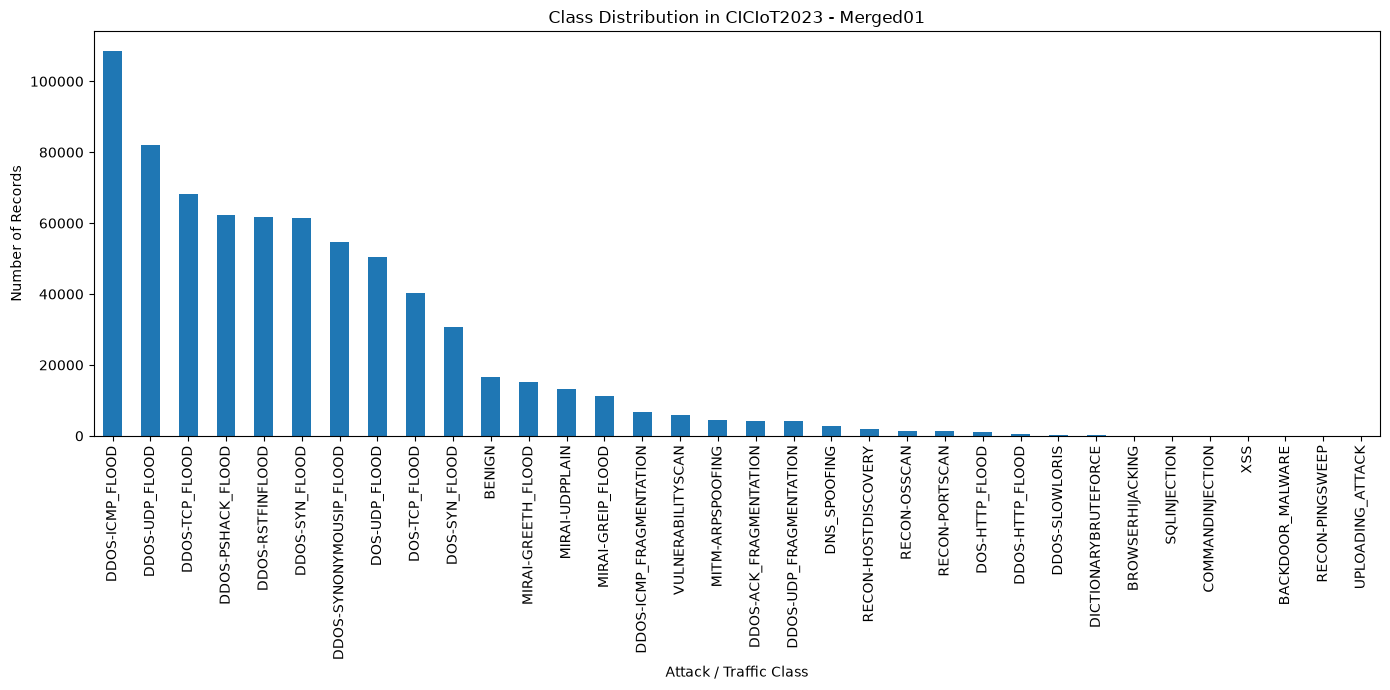

In [11]:
import matplotlib.pyplot as plt

label_counts = df["Label"].value_counts()

plt.figure(figsize=(14, 7))
label_counts.plot(kind="bar")
plt.title("Class Distribution in CICIoT2023 - Merged01")
plt.xlabel("Attack / Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
label_counts = df["Label"].value_counts()

display(label_counts.to_frame(name="Count"))

,Count
Label,
DDOS-ICMP_FLOOD,108662
DDOS-UDP_FLOOD,82011
DDOS-TCP_FLOOD,68289
DDOS-PSHACK_FLOOD,62171
DDOS-RSTFINFLOOD,61652
DDOS-SYN_FLOOD,61460
DDOS-SYNONYMOUSIP_FLOOD,54749
DOS-UDP_FLOOD,50371
DOS-TCP_FLOOD,40391


In [13]:
label_counts.to_csv("../results/class_distribution_Merged01.csv")

print("Class distribution saved successfully.")

Class distribution saved successfully.


In [14]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", round((duplicate_count / len(df)) * 100, 2), "%")

Duplicate rows: 167368
Duplicate percentage: 23.5 %


In [15]:
df_unique = df.drop_duplicates()

print("Original rows:", len(df))
print("After removing duplicates:", len(df_unique))
print("Rows removed:", len(df) - len(df_unique))

Original rows: 712311
After removing duplicates: 544943
Rows removed: 167368


In [16]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())
print("\nColumns with missing values:")
display(missing_values[missing_values > 0])

Total missing values: 22

Columns with missing values:


Std         11
Variance    11
dtype: int64

In [17]:
print("Std median:", df["Std"].median())
print("Variance median:", df["Variance"].median())

Std median: 0.0
Variance median: 0.0


In [18]:
df["Std"] = df["Std"].fillna(df["Std"].median())
df["Variance"] = df["Variance"].fillna(df["Variance"].median())

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [19]:
X = df.drop(columns=["Label"])
y = df["Label"]

print("Feature shape:", X.shape)
print("Label shape:", y.shape)
print("Number of classes:", y.nunique())

Feature shape: (712311, 39)
Label shape: (712311,)
Number of classes: 34


In [20]:
print(X.dtypes.value_counts())
print("\nNon-numeric columns:")
print(X.select_dtypes(exclude=["number"]).columns.tolist())

float64    30
int64       9
Name: count, dtype: int64

Non-numeric columns:
[]


In [21]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original labels:", y.unique()[:10])
print("\nEncoded labels:", y_encoded[:10])
print("\nNumber of classes:", len(label_encoder.classes_))

Original labels: <StringArray>
[      'DDOS-PSHACK_FLOOD',       'MIRAI-GREIP_FLOOD',
           'DOS-UDP_FLOOD',            'DNS_SPOOFING',
         'DDOS-ICMP_FLOOD',          'DDOS-TCP_FLOOD',
          'DDOS-SYN_FLOOD',          'DDOS-UDP_FLOOD',
        'MITM-ARPSPOOFING', 'DDOS-SYNONYMOUSIP_FLOOD']
Length: 10, dtype: str

Encoded labels: [ 8 23 21 17  6 13  8 12 14 25]

Number of classes: 34


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)
print("Mean of first 5 features:", X_scaled[:, :5].mean(axis=0))
print("Std of first 5 features:", X_scaled[:, :5].std(axis=0))

ValueError: Input X contains infinity or a value too large for dtype('float64').

In [26]:
import numpy as np

inf_count = np.isinf(X).sum().sum()
large_count = (np.abs(X) > 1e15).sum().sum()

print("Infinite values:", inf_count)
print("Very large values:", large_count)

Infinite values: 14
Very large values: 14


In [27]:
X = X.replace([np.inf, -np.inf], np.nan)

print("Missing values after replacing infinity:")
print(X.isnull().sum().sum())

Missing values after replacing infinity:
14


In [28]:
X = X.fillna(X.median())

print("Remaining missing values:", X.isnull().sum().sum())

Remaining missing values: 0


In [29]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)
print("Mean of first 5 features:", X_scaled[:, :5].mean(axis=0))
print("Std of first 5 features:", X_scaled[:, :5].std(axis=0))

Scaled shape: (712311, 39)
Mean of first 5 features: [-7.08636480e-17 -6.65942728e-17 -4.08263990e-16 -1.27682249e-18
 -4.18957378e-17]
Std of first 5 features: [1. 1. 1. 1. 1.]


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (569848, 39)
X_test : (142463, 39)
y_train: (569848,)
y_test : (142463,)


In [31]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 10 rows - selected columns:")
print(df[["Protocol Type", "Duration", "Rate", "Srate", "Drate", "Label"]].head(10))

Columns:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Label']

First 10 rows - selected columns:


KeyError: "['Duration', 'Srate', 'Drate'] not in index"

In [32]:
for i, col in enumerate(df.columns):
    print(i, "→", col)

0 → Header_Length
1 → Protocol Type
2 → Time_To_Live
3 → Rate
4 → fin_flag_number
5 → syn_flag_number
6 → rst_flag_number
7 → psh_flag_number
8 → ack_flag_number
9 → ece_flag_number
10 → cwr_flag_number
11 → ack_count
12 → syn_count
13 → fin_count
14 → rst_count
15 → HTTP
16 → HTTPS
17 → DNS
18 → Telnet
19 → SMTP
20 → SSH
21 → IRC
22 → TCP
23 → UDP
24 → DHCP
25 → ARP
26 → ICMP
27 → IGMP
28 → IPv
29 → LLC
30 → Tot sum
31 → Min
32 → Max
33 → AVG
34 → Std
35 → Tot size
36 → IAT
37 → Number
38 → Variance
39 → Label


In [33]:
print("First 30 consecutive labels:\n")

for i, label in enumerate(df["Label"].head(30)):
    print(i, "→", label)

First 30 consecutive labels:

0 → DDOS-PSHACK_FLOOD
1 → MIRAI-GREIP_FLOOD
2 → DOS-UDP_FLOOD
3 → DNS_SPOOFING
4 → DDOS-ICMP_FLOOD
5 → DDOS-TCP_FLOOD
6 → DDOS-PSHACK_FLOOD
7 → DDOS-SYN_FLOOD
8 → DDOS-UDP_FLOOD
9 → MITM-ARPSPOOFING
10 → DDOS-PSHACK_FLOOD
11 → DDOS-SYNONYMOUSIP_FLOOD
12 → DDOS-ICMP_FLOOD
13 → DDOS-UDP_FLOOD
14 → DDOS-SYN_FLOOD
15 → DOS-TCP_FLOOD
16 → DDOS-UDP_FLOOD
17 → DDOS-ICMP_FLOOD
18 → DDOS-TCP_FLOOD
19 → DDOS-UDP_FLOOD
20 → VULNERABILITYSCAN
21 → DOS-UDP_FLOOD
22 → DOS-SYN_FLOOD
23 → DDOS-PSHACK_FLOOD
24 → DDOS-TCP_FLOOD
25 → DDOS-PSHACK_FLOOD
26 → DDOS-SYNONYMOUSIP_FLOOD
27 → DDOS-RSTFINFLOOD
28 → DDOS-ICMP_FLOOD
29 → DDOS-TCP_FLOOD


In [34]:
import pandas as pd

train_class_counts = pd.Series(y_train).value_counts().sort_values()

print("Smallest class counts:")
print(train_class_counts.head(10))

print("\nMinimum class size:", train_class_counts.min())

Smallest class counts:
31     16
28     22
0      33
33     54
3      58
30     62
2      66
16    163
10    283
5     333
Name: count, dtype: int64

Minimum class size: 16


In [35]:
print("Classes with fewer than 20 samples:")
print(train_class_counts[train_class_counts < 20])

print("\nClasses with fewer than 50 samples:")
print(train_class_counts[train_class_counts < 50])

print("\nTotal classes with fewer than 50 samples:",
      (train_class_counts < 50).sum())

Classes with fewer than 20 samples:
31    16
Name: count, dtype: int64

Classes with fewer than 50 samples:
31    16
28    22
0     33
Name: count, dtype: int64

Total classes with fewer than 50 samples: 3


In [36]:
rare_ids = train_class_counts[train_class_counts < 50].index

for class_id in rare_ids:
    print(
        "Encoded ID:", class_id,
        "→ Label:", label_encoder.inverse_transform([class_id])[0],
        "→ Samples:", train_class_counts[class_id]
    )

Encoded ID: 31 → Label: UPLOADING_ATTACK → Samples: 16
Encoded ID: 28 → Label: RECON-PINGSWEEP → Samples: 22
Encoded ID: 0 → Label: BACKDOOR_MALWARE → Samples: 33


In [37]:
sequence_length = 5

X_sample = X_train[:20]

print("Original shape:", X_sample.shape)

test_sequences = []

for i in range(len(X_sample) - sequence_length + 1):
    test_sequences.append(X_sample[i:i + sequence_length])

test_sequences = np.array(test_sequences)

print("Sequence shape:", test_sequences.shape)

Original shape: (20, 39)
Sequence shape: (16, 5, 39)


In [39]:
sequence_length = 5

labels_sample = y_train[:100]

mixed_count = 0
pure_count = 0

for i in range(len(labels_sample) - sequence_length + 1):
    window = labels_sample[i:i + sequence_length]

    if len(np.unique(window)) == 1:
        pure_count += 1
    else:
        mixed_count += 1

print("Pure-label sequences :", pure_count)
print("Mixed-label sequences :", mixed_count)
print("Total sequences      :", pure_count + mixed_count)

Pure-label sequences : 0
Mixed-label sequences : 96
Total sequences      : 96


In [40]:
labels = y_train

run_lengths = []
current_label = labels[0]
current_length = 1

for label in labels[1:]:
    if label == current_label:
        current_length += 1
    else:
        run_lengths.append(current_length)
        current_label = label
        current_length = 1

run_lengths.append(current_length)

print("Maximum consecutive same-label rows:", max(run_lengths))
print("Average consecutive same-label rows:", np.mean(run_lengths))

Maximum consecutive same-label rows: 7
Average consecutive same-label rows: 1.094775184624488


In [41]:
print("Number of rows in Merged01:", len(df))

print("\nFirst 20 row indices:")
print(df.index[:20].tolist())

print("\nLast 20 row indices:")
print(df.index[-20:].tolist())

Number of rows in Merged01: 712311

First 20 row indices:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

Last 20 row indices:
[712291, 712292, 712293, 712294, 712295, 712296, 712297, 712298, 712299, 712300, 712301, 712302, 712303, 712304, 712305, 712306, 712307, 712308, 712309, 712310]


In [42]:
print("IAT statistics:")
print(df["IAT"].describe())

print("\nFirst 20 IAT values:")
print(df["IAT"].head(20).tolist())

IAT statistics:
count    712311.000000
mean          0.001900
std           0.883177
min           0.000000
25%           0.000027
50%           0.000041
75%           0.000089
max         741.003442
Name: IAT, dtype: float64

First 20 IAT values:
[3.861904144287109e-05, 0.0002707815170288, 5.74493408203125e-05, 0.0047659873962402, 3.455877304077148e-05, 2.1150112152099608e-05, 1.0030269622802734e-05, 3.548860549926758e-05, 2.29787826538086e-05, 3.2186508178710938e-06, 2.740144729614258e-05, 3.060817718505859e-05, 4.7669410705566406e-05, 2.2430419921875e-05, 3.2331943511962894e-05, 5.995988845825196e-05, 7.644891738891601e-05, 4.227876663208008e-05, 2.919912338256836e-05, 4.0149688720703126e-05]


In [43]:
iat = df["IAT"].values

iat_diff = np.abs(np.diff(iat))

print("Mean IAT difference:", iat_diff.mean())
print("Median IAT difference:", np.median(iat_diff))
print("Maximum IAT difference:", iat_diff.max())

print("\nFirst 20 consecutive IAT differences:")
print(iat_diff[:20])

Mean IAT difference: 0.0036954420684011586
Median IAT difference: 3.940224647521974e-05
Maximum IAT difference: 741.0033747768402

First 20 consecutive IAT differences:
[2.32162476e-04 2.13332176e-04 4.70853806e-03 4.73142862e-03
 1.34086609e-05 1.11198425e-05 2.54583359e-05 1.25098228e-05
 1.97601318e-05 2.41827965e-05 3.20672989e-06 1.70612335e-05
 2.52389908e-05 9.90152359e-06 2.76279449e-05 1.64890289e-05
 3.41701508e-05 1.30796432e-05 1.09505653e-05 3.39515209e-03]


In [44]:
threshold_99 = np.percentile(iat_diff, 99)

print("99th percentile IAT difference:", threshold_99)
print("Gaps larger than threshold:", np.sum(iat_diff > threshold_99))
print("Total consecutive pairs:", len(iat_diff))

99th percentile IAT difference: 0.02446645596027376
Gaps larger than threshold: 7124
Total consecutive pairs: 712310


In [45]:
labels = df["Label"].values

gap_positions = np.where(iat_diff > threshold_99)[0]

label_changes = 0

for pos in gap_positions:
    if labels[pos] != labels[pos + 1]:
        label_changes += 1

print("Large IAT gaps:", len(gap_positions))
print("Gaps with label change:", label_changes)
print("Percentage:", (label_changes / len(gap_positions)) * 100)

Large IAT gaps: 7124
Gaps with label change: 7081
Percentage: 99.39640651319483


In [46]:
sequence_boundaries = np.where(iat_diff > threshold_99)[0] + 1

print("Number of boundaries:", len(sequence_boundaries))
print("First 20 boundary positions:")
print(sequence_boundaries[:20])

Number of boundaries: 7124
First 20 boundary positions:
[ 182  206  207  284  285  323  324  450  451  540  541  720  722  839
  840  855  856 1122 1123 1154]


In [47]:
segment_starts = np.concatenate(([0], sequence_boundaries))
segment_ends = np.concatenate((sequence_boundaries, [len(df)]))

segment_lengths = segment_ends - segment_starts

print("Number of segments:", len(segment_lengths))
print("Minimum segment length:", segment_lengths.min())
print("Maximum segment length:", segment_lengths.max())
print("Median segment length:", np.median(segment_lengths))
print("Average segment length:", segment_lengths.mean())

print("\nSmallest 20 segment lengths:")
print(np.sort(segment_lengths)[:20])

Number of segments: 7125
Minimum segment length: 1
Maximum segment length: 1496
Median segment length: 5.0
Average segment length: 99.97347368421053

Smallest 20 segment lengths:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [48]:
for min_len in [5, 10, 20]:
    usable = np.sum(segment_lengths >= min_len)
    percentage = (usable / len(segment_lengths)) * 100
    
    print(
        f"Minimum length {min_len}: "
        f"{usable} segments ({percentage:.2f}%)"
    )

Minimum length 5: 3566 segments (50.05%)
Minimum length 10: 3490 segments (48.98%)
Minimum length 20: 3329 segments (46.72%)


In [49]:
percentiles = [25, 50, 75, 90, 95, 99]

print("Segment length percentiles:")

for p in percentiles:
    print(f"{p}th percentile:", np.percentile(segment_lengths, p))



Segment length percentiles:
25th percentile: 1.0
50th percentile: 5.0
75th percentile: 140.0
90th percentile: 319.60000000000036
95th percentile: 453.0
99th percentile: 753.7600000000002


In [50]:
segment_label_purity = []

for start, end in zip(segment_starts, segment_ends):
    labels_in_segment = df["Label"].iloc[start:end]
    
    most_common_count = labels_in_segment.value_counts().iloc[0]
    purity = most_common_count / len(labels_in_segment)
    
    segment_label_purity.append(purity)

segment_label_purity = np.array(segment_label_purity)

print("Mean label purity:", segment_label_purity.mean())
print("Median label purity:", np.median(segment_label_purity))
print("Segments with 100% same label:",
      np.sum(segment_label_purity == 1.0))
print("Total segments:", len(segment_label_purity))

Mean label purity: 0.5801066930606552
Median label purity: 0.375
Segments with 100% same label: 3496
Total segments: 7125


In [51]:
pure_mask = segment_label_purity == 1.0

pure_lengths = segment_lengths[pure_mask]

print("Pure segments:", len(pure_lengths))
print("Minimum length:", pure_lengths.min())
print("Maximum length:", pure_lengths.max())
print("Median length:", np.median(pure_lengths))

for min_len in [5, 10, 20]:
    count = np.sum(pure_lengths >= min_len)
    print(f"Pure segments with length >= {min_len}: {count}")

Pure segments: 3496
Minimum length: 1
Maximum length: 2
Median length: 1.0
Pure segments with length >= 5: 0
Pure segments with length >= 10: 0
Pure segments with length >= 20: 0


In [52]:
labels_10k = df["Label"].head(10000).values

transitions = np.sum(labels_10k[1:] != labels_10k[:-1])

print("Rows checked:", len(labels_10k))
print("Label transitions:", transitions)
print("Transition rate:", transitions / (len(labels_10k) - 1))

Rows checked: 10000
Label transitions: 9170
Transition rate: 0.9170917091709171


In [53]:
window_size = 20
labels_10k = df["Label"].head(10000).values

window_purities = []

for i in range(len(labels_10k) - window_size + 1):
    window = labels_10k[i:i + window_size]
    counts = np.bincount(
        label_encoder.transform(window),
        minlength=len(label_encoder.classes_)
    )
    
    purity = counts.max() / window_size
    window_purities.append(purity)

window_purities = np.array(window_purities)

print("Windows checked:", len(window_purities))
print("Mean purity:", window_purities.mean())
print("Median purity:", np.median(window_purities))
print("Windows with >= 80% purity:",
      np.sum(window_purities >= 0.80))
print("Percentage >= 80%:",
      np.mean(window_purities >= 0.80) * 100)

Windows checked: 9981
Mean purity: 0.2187756737801824
Median purity: 0.2
Windows with >= 80% purity: 0
Percentage >= 80%: 0.0


In [54]:
class_counts = df["Label"].value_counts()

print("Total classes:", len(class_counts))
print("\nClass count statistics:")
print(class_counts.describe())

print("\nClasses with fewer than 100 samples:")
print(class_counts[class_counts < 100])

Total classes: 34

Class count statistics:
count        34.000000
mean      20950.323529
std       29532.812617
min          20.000000
25%         369.500000
50%        4449.000000
75%       37948.250000
max      108662.000000
Name: count, dtype: float64

Classes with fewer than 100 samples:
Label
BROWSERHIJACKING    83
SQLINJECTION        77
COMMANDINJECTION    73
XSS                 67
BACKDOOR_MALWARE    41
RECON-PINGSWEEP     28
UPLOADING_ATTACK    20
Name: count, dtype: int64


In [55]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)

X_train_scaled: (569848, 39)
X_test_scaled : (142463, 39)


In [56]:
split_point = int(len(X_scaled) * 0.8)

X_train_seq = X_scaled[:split_point]
X_test_seq = X_scaled[split_point:]

y_train_seq = y_encoded[:split_point]
y_test_seq = y_encoded[split_point:]

print("Training data:", X_train_seq.shape)
print("Testing data :", X_test_seq.shape)

print("\nTraining labels:", y_train_seq.shape)
print("Testing labels :", y_test_seq.shape)

Training data: (569848, 39)
Testing data : (142463, 39)

Training labels: (569848,)
Testing labels : (142463,)


In [57]:
sequence_length = 5

X_demo = X_train_seq[:100]
y_demo = y_train_seq[:100]

demo_sequences = []
demo_labels = []

for i in range(len(X_demo) - sequence_length):
    demo_sequences.append(X_demo[i:i + sequence_length])
    demo_labels.append(y_demo[i + sequence_length])

demo_sequences = np.array(demo_sequences)
demo_labels = np.array(demo_labels)

print("Sequence shape:", demo_sequences.shape)
print("Label shape:", demo_labels.shape)

Sequence shape: (95, 5, 39)
Label shape: (95,)


In [77]:
sequence_length = 5
X_train_sequences = []
y_train_sequences = []

for i in range(len(X_train_seq) - sequence_length+1):
    X_train_sequences.append(
        X_train_seq[i:i + sequence_length]
    )
    y_train_sequences.append(
        y_train_seq[i + sequence_length-1]
    )

X_train_sequences = np.array(X_train_sequences, dtype=np.float32)
y_train_sequences = np.array(y_train_sequences)

print("Training sequences:", X_train_sequences.shape)
print("Training labels:", y_train_sequences.shape)

Training sequences: (569844, 5, 39)
Training labels: (569844,)


In [78]:
X_test_sequences = []
y_test_sequences = []

for i in range(len(X_test_seq) - sequence_length + 1):

    X_test_sequences.append(
        X_test_seq[i:i + sequence_length]
    )

    y_test_sequences.append(
        y_test_seq[i + sequence_length - 1]
    )

X_test_sequences = np.array(
    X_test_sequences,
    dtype=np.float32
)

y_test_sequences = np.array(y_test_sequences)

print("Testing sequences:", X_test_sequences.shape)
print("Testing labels:", y_test_sequences.shape)

Testing sequences: (142459, 5, 39)
Testing labels: (142459,)


In [60]:
print("Training sequence classes:", len(np.unique(y_train_sequences)))
print("Testing sequence classes :", len(np.unique(y_test_sequences)))

print("\nTraining class distribution:")
print(pd.Series(y_train_sequences).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test_sequences).value_counts().sort_index())

Training sequence classes: 34
Testing sequence classes : 34

Training class distribution:
0        32
1     13308
2        65
3        56
4      3449
5       324
6     86719
7      5481
8     49827
9     49301
10      289
11    43540
12    49085
13    54719
14    65647
15     3442
16      160
17     2184
18      885
19    24588
20    32384
21    40368
22    12141
23     8940
24    10650
25     3682
26     1617
27     1163
28       26
29     1025
30       60
31       13
32     4623
33       50
Name: count, dtype: int64

Testing class distribution:
0         9
1      3269
2        18
3        17
4       859
5        92
6     21941
7      1303
8     12343
9     12350
10       65
11    11209
12    12375
13    13570
14    16363
15      822
16       44
17      553
18      228
19     6032
20     8006
21    10002
22     2994
23     2246
24     2692
25      907
26      428
27      270
28        2
29      226
30       17
31        7
32     1182
33       17
Name: count, dtype: int64


In [74]:
import numpy as np

capped_class_weight_dict = {
    class_id: min(weight, 10.0)
    for class_id, weight in class_weight_dict.items()
}

print("Capped class weights:")
for class_id, weight in capped_class_weight_dict.items():
    print(class_id, "->", round(weight, 2))

Capped class weights:
0 -> 10.0
1 -> 1.26
2 -> 10.0
3 -> 10.0
4 -> 4.86
5 -> 10.0
6 -> 0.19
7 -> 3.06
8 -> 0.34
9 -> 0.34
10 -> 10.0
11 -> 0.38
12 -> 0.34
13 -> 0.31
14 -> 0.26
15 -> 4.87
16 -> 10.0
17 -> 7.67
18 -> 10.0
19 -> 0.68
20 -> 0.52
21 -> 0.42
22 -> 1.38
23 -> 1.87
24 -> 1.57
25 -> 4.55
26 -> 10.0
27 -> 10.0
28 -> 10.0
29 -> 10.0
30 -> 10.0
31 -> 10.0
32 -> 3.63
33 -> 10.0


In [61]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_sequences)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_sequences
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights:")
for class_id, weight in class_weight_dict.items():
    print(
        class_id,
        "→",
        label_encoder.inverse_transform([class_id])[0],
        "→",
        round(weight, 2)
    )

Class weights:
0 → BACKDOOR_MALWARE → 523.75
1 → BENIGN → 1.26
2 → BROWSERHIJACKING → 257.85
3 → COMMANDINJECTION → 299.29
4 → DDOS-ACK_FRAGMENTATION → 4.86
5 → DDOS-HTTP_FLOOD → 51.73
6 → DDOS-ICMP_FLOOD → 0.19
7 → DDOS-ICMP_FRAGMENTATION → 3.06
8 → DDOS-PSHACK_FLOOD → 0.34
9 → DDOS-RSTFINFLOOD → 0.34
10 → DDOS-SLOWLORIS → 57.99
11 → DDOS-SYNONYMOUSIP_FLOOD → 0.38
12 → DDOS-SYN_FLOOD → 0.34
13 → DDOS-TCP_FLOOD → 0.31
14 → DDOS-UDP_FLOOD → 0.26
15 → DDOS-UDP_FRAGMENTATION → 4.87
16 → DICTIONARYBRUTEFORCE → 104.75
17 → DNS_SPOOFING → 7.67
18 → DOS-HTTP_FLOOD → 18.94
19 → DOS-SYN_FLOOD → 0.68
20 → DOS-TCP_FLOOD → 0.52
21 → DOS-UDP_FLOOD → 0.42
22 → MIRAI-GREETH_FLOOD → 1.38
23 → MIRAI-GREIP_FLOOD → 1.87
24 → MIRAI-UDPPLAIN → 1.57
25 → MITM-ARPSPOOFING → 4.55
26 → RECON-HOSTDISCOVERY → 10.36
27 → RECON-OSSCAN → 14.41
28 → RECON-PINGSWEEP → 644.62
29 → RECON-PORTSCAN → 16.35
30 → SQLINJECTION → 279.33
31 → UPLOADING_ATTACK → 1289.24
32 → VULNERABILITYSCAN → 3.63
33 → XSS → 335.2


In [62]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout,
    Layer
)

num_classes = len(label_encoder.classes_)
timesteps = X_train_sequences.shape[1]
num_features = X_train_sequences.shape[2]

print("Timesteps:", timesteps)
print("Features:", num_features)
print("Classes:", num_classes)

Timesteps: 5
Features: 39
Classes: 34


In [63]:
class Attention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):
        scores = tf.nn.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        weights = tf.nn.softmax(scores, axis=1)

        context = tf.reduce_sum(
            inputs * weights,
            axis=1
        )

        return context


print("Attention layer created successfully.")

Attention layer created successfully.


In [64]:
inputs = Input(shape=(timesteps, num_features))

# CNN: local traffic patterns learn chestundi
x = Conv1D(
    filters=64,
    kernel_size=3,
    activation="relu",
    padding="same"
)(inputs)

# LSTM: sequence relationships learn chestundi
x = LSTM(
    64,
    return_sequences=True
)(x)

# Attention: important timesteps ni focus chestundi
x = Attention()(x)

# Classification layers
x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(
    num_classes,
    activation="softmax"
)(x)

model = Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5, 39)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 5, 64)          │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 5, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (Attention)           │ (None, 64)             │            69 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 34)             │         2,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,015 (183.65 KB)

 Trainable params: 47,015 (183.65 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [76]:
history = model.fit(
    X_train_sequences,
    y_train_sequences,
    epochs=15,
    batch_size=512,
    validation_split=0.1,
    class_weight=capped_class_weight_dict,
    shuffle=False,
    verbose=1
)

Epoch 1/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.0165 - loss: 2.1972 - val_accuracy: 0.0134 - val_loss: 3.1692
Epoch 2/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.0170 - loss: 2.1789 - val_accuracy: 0.0132 - val_loss: 3.1682
Epoch 3/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.0169 - loss: 2.1724 - val_accuracy: 0.0124 - val_loss: 3.1674
Epoch 4/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.0164 - loss: 2.1668 - val_accuracy: 0.0115 - val_loss: 3.1616
Epoch 5/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.0161 - loss: 2.1644 - val_accuracy: 0.0102 - val_loss: 3.1660
Epoch 6/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.0162 - loss: 2.1621 - val_accuracy: 0.0120 - val_loss: 3.1639
Epoch 7/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 19s 19ms/step - accuracy: 0.0149 - loss: 2.1604 - val_accuracy: 0.0118 - val_loss: 3.1666
Epoch 8/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 19s 19ms/step - accuracy: 0.0153 -

In [68]:
print("Shape:", X_train_sequences.shape)
print("Min:", np.min(X_train_sequences))
print("Max:", np.max(X_train_sequences))
print("Mean:", np.mean(X_train_sequences))
print("Std:", np.std(X_train_sequences))

Shape: (569843, 5, 39)
Min: -52.89862
Max: 839.0192
Mean: -4.2669137e-05
Std: 0.99685097


In [69]:
print("Number of classes:", len(np.unique(y_train_sequences)))
print("Class IDs:", np.unique(y_train_sequences))
print("Minimum label:", np.min(y_train_sequences))
print("Maximum label:", np.max(y_train_sequences))

Number of classes: 34
Class IDs: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33]
Minimum label: 0
Maximum label: 33


In [71]:
for c, w in class_weight_dict.items():
    print(c, "->", w)

0 -> 523.7527573529412
1 -> 1.259399476652699
2 -> 257.8475113122172
3 -> 299.28728991596637
4 -> 4.859405113161531
5 -> 51.72866739288308
6 -> 0.19326892878485818
7 -> 3.0578522596778175
8 -> 0.3363655896460577
9 -> 0.3399543261859621
10 -> 57.99338489721148
11 -> 0.38493542111378315
12 -> 0.3414503052927395
13 -> 0.30629375966838057
14 -> 0.2553062323532548
15 -> 4.869287691834433
16 -> 104.75055147058823
17 -> 7.674033074768369
18 -> 18.937952808241942
19 -> 0.6816369056163217
20 -> 0.5175422503487561
21 -> 0.4151825266372899
22 -> 1.380453688764856
23 -> 1.8747302276615345
24 -> 1.573717205191936
25 -> 4.5518979454899835
26 -> 10.364927789297537
27 -> 14.411081887613172
28 -> 644.618778280543
29 -> 16.351305595408895
30 -> 279.3348039215686
31 -> 1289.237556561086
32 -> 3.6253705895077046
33 -> 335.20176470588234


In [70]:
unique, counts = np.unique(y_train_sequences, return_counts=True)

for c, n in zip(unique, counts):
    print(c, "->", n)

0 -> 32
1 -> 13308
2 -> 65
3 -> 56
4 -> 3449
5 -> 324
6 -> 86719
7 -> 5481
8 -> 49827
9 -> 49301
10 -> 289
11 -> 43540
12 -> 49085
13 -> 54719
14 -> 65647
15 -> 3442
16 -> 160
17 -> 2184
18 -> 885
19 -> 24588
20 -> 32384
21 -> 40368
22 -> 12141
23 -> 8940
24 -> 10650
25 -> 3682
26 -> 1617
27 -> 1163
28 -> 26
29 -> 1025
30 -> 60
31 -> 13
32 -> 4623
33 -> 50


In [61]:
sample_size = 10000

pred_probs = model.predict(
    X_test_sequences[:sample_size],
    verbose=0
)

pred_labels = np.argmax(pred_probs, axis=1)

print("Predicted classes:")
print(pd.Series(pred_labels).value_counts().sort_index())

print("\nActual classes:")
print(pd.Series(y_test_sequences[:sample_size]).value_counts().sort_index())

Predicted classes:
0      252
1        7
2     1806
3     1648
6        1
9      194
13     803
14     161
15     324
17      23
20      22
21       1
22     485
25      28
26      45
28    1576
31    1190
32     620
33     814
Name: count, dtype: int64

Actual classes:
0        1
1      222
2        1
3        1
4       64
5       11
6     1549
7      103
8      900
9      887
10       4
11     802
12     850
13     981
14    1148
15      56
16       2
17      43
18      17
19     387
20     583
21     709
22     198
23     131
24     176
25      52
26      22
27      20
29      10
30       3
31       2
32      65
Name: count, dtype: int64


In [62]:
max_confidence = np.max(pred_probs, axis=1)

print("Average prediction confidence:",
      max_confidence.mean())

print("Median prediction confidence:",
      np.median(max_confidence))

print("Minimum confidence:",
      max_confidence.min())

print("Maximum confidence:",
      max_confidence.max())

Average prediction confidence: 0.034211714
Median prediction confidence: 0.03388983
Minimum confidence: 0.030770654
Maximum confidence: 0.04401206


In [63]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

baseline_size = 50000

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf.fit(
    X_train_scaled[:baseline_size],
    y_train_seq[:baseline_size]
)

rf_pred = rf.predict(X_test_seq[:10000])

print("Random Forest baseline accuracy:",
      accuracy_score(y_test_seq[:10000], rf_pred))

Random Forest baseline accuracy: 0.1436


In [64]:
split_point = int(len(X) * 0.8)

X_ordered_train = X.iloc[:split_point]
X_ordered_test = X.iloc[split_point:]

y_ordered_train = y_encoded[:split_point]
y_ordered_test = y_encoded[split_point:]

ordered_scaler = StandardScaler()

X_ordered_train_scaled = ordered_scaler.fit_transform(X_ordered_train)
X_ordered_test_scaled = ordered_scaler.transform(X_ordered_test)

print("Train:", X_ordered_train_scaled.shape)
print("Test :", X_ordered_test_scaled.shape)

Train: (569848, 39)
Test : (142463, 39)


In [65]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf.fit(
    X_ordered_train_scaled[:50000],
    y_ordered_train[:50000]
)

rf_pred = rf.predict(
    X_ordered_test_scaled[:10000]
)

rf_accuracy = accuracy_score(
    y_ordered_test[:10000],
    rf_pred
)

print("Correct Random Forest baseline accuracy:",
      rf_accuracy)

Correct Random Forest baseline accuracy: 0.7568


In [66]:
sequence_length = 5

X_demo = X_ordered_train_scaled[:100]
y_demo = y_ordered_train[:100]

demo_sequences = []
demo_labels = []

for i in range(len(X_demo) - sequence_length + 1):
    demo_sequences.append(
        X_demo[i:i + sequence_length]
    )
    demo_labels.append(
        y_demo[i + sequence_length - 1]
    )

demo_sequences = np.array(demo_sequences, dtype=np.float32)
demo_labels = np.array(demo_labels)

print("Sequence shape:", demo_sequences.shape)
print("Label shape:", demo_labels.shape)

Sequence shape: (96, 5, 39)
Label shape: (96,)


In [67]:
print("Number of classes:", len(np.unique(demo_labels)))

print("\nClass distribution:")
print(pd.Series(demo_labels).value_counts().sort_index())

Number of classes: 17

Class distribution:
1      3
6     20
7      1
8      9
9      8
10     1
11     9
12     7
13     9
14    12
17     1
19     2
20     4
21     6
22     1
25     1
32     2
Name: count, dtype: int64


In [84]:
sequence_length = 5

X_train_sequences = []
y_train_sequences = []

for i in range(len(X_train_seq) - sequence_length + 1):
    X_train_sequences.append(
        X_train_seq[i:i + sequence_length]
    )
    y_train_sequences.append(
        y_train_seq[i + sequence_length - 1]
    )

X_train_sequences = np.array(X_train_sequences, dtype=np.float32)
y_train_sequences = np.array(y_train_sequences)

print("Training sequences:", X_train_sequences.shape)
print("Training labels:", y_train_sequences.shape)

Training sequences: (569844, 5, 39)
Training labels: (569844,)


In [85]:
sequence_length = 5

X_test_sequences = []
y_test_sequences = []

for i in range(len(X_test_seq) - sequence_length + 1):
    X_test_sequences.append(
        X_test_seq[i:i + sequence_length]
    )
    y_test_sequences.append(
        y_test_seq[i + sequence_length - 1]
    )

X_test_sequences = np.array(X_test_sequences, dtype=np.float32)
y_test_sequences = np.array(y_test_sequences)

print("Testing sequences:", X_test_sequences.shape)
print("Testing labels:", y_test_sequences.shape)

Testing sequences: (142459, 5, 39)
Testing labels: (142459,)


In [87]:
# Check how consistent the labels are inside each sequence

same_count = 0
total_pairs = 0

for i in range(len(y_train_seq) - 1):
    if y_train_seq[i] == y_train_seq[i + 1]:
        same_count += 1
    total_pairs += 1

adjacent_consistency = same_count / total_pairs

print("Adjacent label consistency:", adjacent_consistency)


# Check purity of the first 10,000 sequences

purities = []

for i in range(min(10000, len(y_train_sequences))):

    last_label = y_train_sequences[i]

    purity = np.mean(
        y_train_seq[i:i + sequence_length] == last_label
    )

    purities.append(purity)


print("Average sequence purity:", np.mean(purities))
print("Pure sequences:", np.mean(np.array(purities) == 1.0))

Adjacent label consistency: 0.0860055418384233
Average sequence purity: 0.2708
Pure sequences: 0.0001


In [88]:
print("Available columns:")

for i, col in enumerate(df.columns):
    print(i, ":", col)

Available columns:
0 : Header_Length
1 : Protocol Type
2 : Time_To_Live
3 : Rate
4 : fin_flag_number
5 : syn_flag_number
6 : rst_flag_number
7 : psh_flag_number
8 : ack_flag_number
9 : ece_flag_number
10 : cwr_flag_number
11 : ack_count
12 : syn_count
13 : fin_count
14 : rst_count
15 : HTTP
16 : HTTPS
17 : DNS
18 : Telnet
19 : SMTP
20 : SSH
21 : IRC
22 : TCP
23 : UDP
24 : DHCP
25 : ARP
26 : ICMP
27 : IGMP
28 : IPv
29 : LLC
30 : Tot sum
31 : Min
32 : Max
33 : AVG
34 : Std
35 : Tot size
36 : IAT
37 : Number
38 : Variance
39 : Label


In [89]:
# Check the lengths of consecutive same-label blocks

block_lengths = []
current_length = 1

for i in range(1, len(y_train_seq)):

    if y_train_seq[i] == y_train_seq[i - 1]:
        current_length += 1
    else:
        block_lengths.append(current_length)
        current_length = 1

block_lengths.append(current_length)

print("Total label blocks:", len(block_lengths))
print("Average block length:", np.mean(block_lengths))
print("Maximum block length:", np.max(block_lengths))

print("Blocks with at least 5 records:",
      np.sum(np.array(block_lengths) >= 5))

print("Percentage of blocks with at least 5 records:",
      np.mean(np.array(block_lengths) >= 5) * 100)

Total label blocks: 520838
Average block length: 1.0940983568787224
Maximum block length: 7
Blocks with at least 5 records: 66
Percentage of blocks with at least 5 records: 0.01267188645989732


In [90]:
# Check the distribution of labels in the sequence targets

unique_labels, label_counts = np.unique(
    y_train_sequences,
    return_counts=True
)

print("Number of classes:", len(unique_labels))
print("\nSequence target distribution:")

for label, count in zip(unique_labels, label_counts):
    print(
        "Class", label,
        ":", count,
        "(", round(count / len(y_train_sequences) * 100, 2), "%)"
    )

Number of classes: 34

Sequence target distribution:
Class 0 : 32 ( 0.01 %)
Class 1 : 13308 ( 2.34 %)
Class 2 : 65 ( 0.01 %)
Class 3 : 56 ( 0.01 %)
Class 4 : 3449 ( 0.61 %)
Class 5 : 324 ( 0.06 %)
Class 6 : 86720 ( 15.22 %)
Class 7 : 5481 ( 0.96 %)
Class 8 : 49827 ( 8.74 %)
Class 9 : 49301 ( 8.65 %)
Class 10 : 289 ( 0.05 %)
Class 11 : 43540 ( 7.64 %)
Class 12 : 49085 ( 8.61 %)
Class 13 : 54719 ( 9.6 %)
Class 14 : 65647 ( 11.52 %)
Class 15 : 3442 ( 0.6 %)
Class 16 : 160 ( 0.03 %)
Class 17 : 2184 ( 0.38 %)
Class 18 : 885 ( 0.16 %)
Class 19 : 24588 ( 4.31 %)
Class 20 : 32384 ( 5.68 %)
Class 21 : 40368 ( 7.08 %)
Class 22 : 12141 ( 2.13 %)
Class 23 : 8940 ( 1.57 %)
Class 24 : 10650 ( 1.87 %)
Class 25 : 3682 ( 0.65 %)
Class 26 : 1617 ( 0.28 %)
Class 27 : 1163 ( 0.2 %)
Class 28 : 26 ( 0.0 %)
Class 29 : 1025 ( 0.18 %)
Class 30 : 60 ( 0.01 %)
Class 31 : 13 ( 0.0 %)
Class 32 : 4623 ( 0.81 %)
Class 33 : 50 ( 0.01 %)


In [91]:
print("TRAIN vs TEST class distribution")
print("-" * 45)

train_labels, train_counts = np.unique(
    y_train_sequences,
    return_counts=True
)

test_labels, test_counts = np.unique(
    y_test_sequences,
    return_counts=True
)

for label in range(34):

    train_count = train_counts[train_labels.tolist().index(label)] \
        if label in train_labels else 0

    test_count = test_counts[test_labels.tolist().index(label)] \
        if label in test_labels else 0

    train_percent = train_count / len(y_train_sequences) * 100
    test_percent = test_count / len(y_test_sequences) * 100

    print(
        f"Class {label:2d} | "
        f"Train: {train_percent:6.2f}% | "
        f"Test: {test_percent:6.2f}%"
    )

TRAIN vs TEST class distribution
---------------------------------------------
Class  0 | Train:   0.01% | Test:   0.01%
Class  1 | Train:   2.34% | Test:   2.29%
Class  2 | Train:   0.01% | Test:   0.01%
Class  3 | Train:   0.01% | Test:   0.01%
Class  4 | Train:   0.61% | Test:   0.60%
Class  5 | Train:   0.06% | Test:   0.06%
Class  6 | Train:  15.22% | Test:  15.40%
Class  7 | Train:   0.96% | Test:   0.91%
Class  8 | Train:   8.74% | Test:   8.66%
Class  9 | Train:   8.65% | Test:   8.67%
Class 10 | Train:   0.05% | Test:   0.05%
Class 11 | Train:   7.64% | Test:   7.87%
Class 12 | Train:   8.61% | Test:   8.69%
Class 13 | Train:   9.60% | Test:   9.53%
Class 14 | Train:  11.52% | Test:  11.49%
Class 15 | Train:   0.60% | Test:   0.58%
Class 16 | Train:   0.03% | Test:   0.03%
Class 17 | Train:   0.38% | Test:   0.39%
Class 18 | Train:   0.16% | Test:   0.16%
Class 19 | Train:   4.31% | Test:   4.23%
Class 20 | Train:   5.68% | Test:   5.62%
Class 21 | Train:   7.08% | Test:   7.0

In [92]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Use the last record of each sequence
X_train_single = X_train_sequences[:, -1, :]
X_test_single = X_test_sequences[:, -1, :]

print("Training baseline model...")

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_single, y_train_sequences)

rf_pred = rf.predict(X_test_single)

rf_accuracy = accuracy_score(
    y_test_sequences,
    rf_pred
)

print("Random Forest baseline accuracy:",
      round(rf_accuracy * 100, 2), "%")

Training baseline model...
Random Forest baseline accuracy: 77.64 %


In [93]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Use all 5 records in each sequence
X_train_flat = X_train_sequences.reshape(
    X_train_sequences.shape[0], -1
)

X_test_flat = X_test_sequences.reshape(
    X_test_sequences.shape[0], -1
)

print("Training Random Forest with all 5 records...")

rf_all = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_all.fit(X_train_flat, y_train_sequences)

rf_all_pred = rf_all.predict(X_test_flat)

rf_all_accuracy = accuracy_score(
    y_test_sequences,
    rf_all_pred
)

print(
    "Random Forest (all 5 records) accuracy:",
    round(rf_all_accuracy * 100, 2),
    "%"
)


Training Random Forest with all 5 records...
Random Forest (all 5 records) accuracy: 77.7 %


In [94]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Use the last record because it is the target record
X_train_dense = X_train_sequences[:, -1, :]
X_test_dense = X_test_sequences[:, -1, :]

dense_model = Sequential([
    Dense(128, activation="relu", input_shape=(39,)),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(34, activation="softmax")
])

dense_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training Dense baseline...")

dense_history = dense_model.fit(
    X_train_dense,
    y_train_sequences,
    validation_split=0.1,
    epochs=5,
    batch_size=512,
    shuffle=True,
    verbose=1
)

dense_loss, dense_accuracy = dense_model.evaluate(
    X_test_dense,
    y_test_sequences,
    verbose=0
)

print(
    "Dense baseline test accuracy:",
    round(dense_accuracy * 100, 2),
    "%"
)

c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training Dense baseline...
Epoch 1/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7143 - loss: 0.6550 - val_accuracy: 0.7477 - val_loss: 0.5006
Epoch 2/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7405 - loss: 0.5123 - val_accuracy: 0.7497 - val_loss: 0.4873
Epoch 3/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7447 - loss: 0.4984 - val_accuracy: 0.7523 - val_loss: 0.4800
Epoch 4/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7479 - loss: 0.4905 - val_accuracy: 0.7538 - val_loss: 0.4745
Epoch 5/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7497 - loss: 0.4855 - val_accuracy: 0.7539 - val_loss: 0.4722
Dense baseline test accuracy: 75.39 %


In [95]:
# Compare different sequence lengths

for seq_len in [2, 3, 5, 10]:

    X_temp = []
    y_temp = []

    for i in range(len(X_train_seq) - seq_len + 1):
        X_temp.append(X_train_seq[i:i + seq_len])
        y_temp.append(y_train_seq[i + seq_len - 1])

    X_temp = np.array(X_temp, dtype=np.float32)
    y_temp = np.array(y_temp)

    # Check how many records in each window match the target label
    purity = []

    for i in range(min(5000, len(X_temp))):
        purity.append(
            np.mean(y_train_seq[i:i + seq_len] == y_temp[i])
        )

    print(
        f"Sequence length {seq_len}: "
        f"Average purity = {np.mean(purity):.4f}"
    )

Sequence length 2: Average purity = 0.5401
Sequence length 3: Average purity = 0.3914
Sequence length 5: Average purity = 0.2701
Sequence length 10: Average purity = 0.1780


In [96]:
sequence_length = 2

X_train_seq2 = []
y_train_seq2 = []

for i in range(len(X_train_seq) - sequence_length + 1):
    X_train_seq2.append(
        X_train_seq[i:i + sequence_length]
    )
    y_train_seq2.append(
        y_train_seq[i + sequence_length - 1]
    )

X_test_seq2 = []
y_test_seq2 = []

for i in range(len(X_test_seq) - sequence_length + 1):
    X_test_seq2.append(
        X_test_seq[i:i + sequence_length]
    )
    y_test_seq2.append(
        y_test_seq[i + sequence_length - 1]
    )

X_train_seq2 = np.array(X_train_seq2, dtype=np.float32)
y_train_seq2 = np.array(y_train_seq2)

X_test_seq2 = np.array(X_test_seq2, dtype=np.float32)
y_test_seq2 = np.array(y_test_seq2)

print("Training sequences:", X_train_seq2.shape)
print("Training labels:", y_train_seq2.shape)

print("Testing sequences:", X_test_seq2.shape)
print("Testing labels:", y_test_seq2.shape)

Training sequences: (569847, 2, 39)
Training labels: (569847,)
Testing sequences: (142462, 2, 39)
Testing labels: (142462,)


In [97]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv1D, LSTM, Dense, Dropout,
    Layer, Softmax
)
from tensorflow.keras.models import Model


class Attention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        scores = tf.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        attention_weights = tf.nn.softmax(
            scores,
            axis=1
        )

        context = tf.reduce_sum(
            inputs * attention_weights,
            axis=1
        )

        return context


inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

outputs = Dense(
    34,
    activation="softmax"
)(x)

seq2_model = Model(
    inputs=inputs,
    outputs=outputs
)

seq2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

seq2_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 2, 39)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2, 64)          │         5,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 2, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_1 (Attention)         │ (None, 64)             │            66 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 34)             │         2,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,516 (173.89 KB)

 Trainable params: 44,516 (173.89 KB)

 Non-trainable params: 0 (0.00 B)

In [98]:
print("Training CNN-LSTM-Attention with sequence length 2...")

history_seq2 = seq2_model.fit(
    X_train_seq2,
    y_train_seq2,
    validation_split=0.1,
    epochs=5,
    batch_size=512,
    shuffle=True,
    verbose=1
)

seq2_loss, seq2_accuracy = seq2_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=0
)

print(
    "Sequence length 2 test accuracy:",
    round(seq2_accuracy * 100, 2),
    "%"
)

Training CNN-LSTM-Attention with sequence length 2...
Epoch 1/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.7012 - loss: 0.6801 - val_accuracy: 0.7456 - val_loss: 0.4975
Epoch 2/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7424 - loss: 0.5022 - val_accuracy: 0.7511 - val_loss: 0.4851
Epoch 3/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7482 - loss: 0.4895 - val_accuracy: 0.7530 - val_loss: 0.4776
Epoch 4/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7521 - loss: 0.4824 - val_accuracy: 0.7555 - val_loss: 0.4749
Epoch 5/5
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7574 - loss: 0.4745 - val_accuracy: 0.7588 - val_loss: 0.4663
Sequence length 2 test accuracy: 76.03 %


In [99]:
print("Continuing CNN-LSTM-Attention training...")

history_seq2_more = seq2_model.fit(
    X_train_seq2,
    y_train_seq2,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=True,
    verbose=1
)

seq2_loss, seq2_accuracy = seq2_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=0
)

print(
    "Updated sequence length 2 test accuracy:",
    round(seq2_accuracy * 100, 2),
    "%"
)

Continuing CNN-LSTM-Attention training...
Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7629 - loss: 0.4653 - val_accuracy: 0.7570 - val_loss: 0.4698
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7656 - loss: 0.4588 - val_accuracy: 0.7683 - val_loss: 0.4505
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7673 - loss: 0.4552 - val_accuracy: 0.7692 - val_loss: 0.4467
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7680 - loss: 0.4533 - val_accuracy: 0.7698 - val_loss: 0.4485
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7679 - loss: 0.4532 - val_accuracy: 0.7697 - val_loss: 0.4467
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7690 - loss: 0.4504 - val_accuracy: 0.7696 - val_loss: 0.4444
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7701 - loss: 0.4482 - val_accuracy: 0.7697 - val_loss: 0.4488
Epoch 8/10
1002/1002 ━━━━━━━━━━━━━

In [100]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

print("Training with adaptive learning rate...")

history_seq2_tuned = seq2_model.fit(
    X_train_seq2,
    y_train_seq2,
    validation_split=0.1,
    epochs=15,
    batch_size=512,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

seq2_loss, seq2_accuracy = seq2_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=0
)

print(
    "Tuned sequence length 2 test accuracy:",
    round(seq2_accuracy * 100, 2),
    "%"
)

Training with adaptive learning rate...
Epoch 1/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7717 - loss: 0.4442 - val_accuracy: 0.7697 - val_loss: 0.4455 - learning_rate: 0.0010
Epoch 2/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7720 - loss: 0.4434 - val_accuracy: 0.7632 - val_loss: 0.4579 - learning_rate: 0.0010
Epoch 3/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7724 - loss: 0.4426 - val_accuracy: 0.7725 - val_loss: 0.4417 - learning_rate: 0.0010
Epoch 4/15
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7728 - loss: 0.4413 - val_accuracy: 0.7730 - val_loss: 0.4420 - learning_rate: 0.0010
Epoch 5/15
 999/1002 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7731 - loss: 0.4416
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7731 - loss: 0.4417 - val_accuracy: 0.7666 - val_loss: 0.4569 - learning_rate: 0.0010
Epoch 6/15
1002/1002 ━━━━━

In [101]:
seq2_loss, seq2_accuracy = seq2_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=1
)

print(
    "Tuned sequence length 2 test accuracy:",
    round(seq2_accuracy * 100, 2),
    "%"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.7767 - loss: 0.4362
Tuned sequence length 2 test accuracy: 77.67 %


In [102]:
from sklearn.metrics import classification_report

# Get predictions from the best sequence-2 model
y_pred_seq2 = np.argmax(
    seq2_model.predict(
        X_test_seq2,
        batch_size=512,
        verbose=1
    ),
    axis=1
)

print(
    classification_report(
        y_test_seq2,
        y_pred_seq2,
        digits=4,
        zero_division=0
    )
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000         9
           1     0.7171    0.8880    0.7935      3269
           2     1.0000    0.1667    0.2857        18
           3     0.0000    0.0000    0.0000        17
           4     0.9941    0.9849    0.9895       859
           5     0.8429    0.6413    0.7284        92
           6     0.9988    0.9990    0.9989     21942
           7     0.9734    0.9816    0.9775      1303
           8     0.9994    0.9985    0.9989     12343
           9     1.0000    0.9989    0.9995     12351
          10     0.5714    0.7385    0.6443        65
          11     0.4731    0.6310    0.5408     11209
          12     0.4821    0.4981    0.4900     12375
          13     0.6628    0.9353    0.7758     13570
          14     0.7285    0.9415    0.8214     16364
          15     0.9951    0.9842    0.9896       822
          16     0.9000    0.2045    0.3

In [103]:
report = classification_report(
    y_test_seq2,
    y_pred_seq2,
    digits=4,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print(report_df.to_string())

              precision    recall  f1-score       support
0              0.000000  0.000000  0.000000       9.00000
1              0.717144  0.888039  0.793495    3269.00000
2              1.000000  0.166667  0.285714      18.00000
3              0.000000  0.000000  0.000000      17.00000
4              0.994125  0.984866  0.989474     859.00000
5              0.842857  0.641304  0.728395      92.00000
6              0.998815  0.999043  0.998929   21942.00000
7              0.973364  0.981581  0.977455    1303.00000
8              0.999351  0.998461  0.998906   12343.00000
9              1.000000  0.998947  0.999473   12351.00000
10             0.571429  0.738462  0.644295      65.00000
11             0.473142  0.631011  0.540791   11209.00000
12             0.482090  0.498101  0.489965   12375.00000
13             0.662768  0.935298  0.775795   13570.00000
14             0.728463  0.941518  0.821400   16364.00000
15             0.995080  0.984185  0.989602     822.00000
16            

In [104]:
print("Class ID → Attack Name → F1 → Support")
print("-" * 65)

for class_id in range(34):

    attack_name = label_encoder.inverse_transform([class_id])[0]

    f1 = report_df.loc[str(class_id), "f1-score"]
    support = int(report_df.loc[str(class_id), "support"])

    print(
        f"{class_id:2d} → "
        f"{attack_name:30s} → "
        f"F1: {f1:.4f} → "
        f"Support: {support}"
    )

Class ID → Attack Name → F1 → Support
-----------------------------------------------------------------
 0 → BACKDOOR_MALWARE               → F1: 0.0000 → Support: 9
 1 → BENIGN                         → F1: 0.7935 → Support: 3269
 2 → BROWSERHIJACKING               → F1: 0.2857 → Support: 18
 3 → COMMANDINJECTION               → F1: 0.0000 → Support: 17
 4 → DDOS-ACK_FRAGMENTATION         → F1: 0.9895 → Support: 859
 5 → DDOS-HTTP_FLOOD                → F1: 0.7284 → Support: 92
 6 → DDOS-ICMP_FLOOD                → F1: 0.9989 → Support: 21942
 7 → DDOS-ICMP_FRAGMENTATION        → F1: 0.9775 → Support: 1303
 8 → DDOS-PSHACK_FLOOD              → F1: 0.9989 → Support: 12343
 9 → DDOS-RSTFINFLOOD               → F1: 0.9995 → Support: 12351
10 → DDOS-SLOWLORIS                 → F1: 0.6443 → Support: 65
11 → DDOS-SYNONYMOUSIP_FLOOD        → F1: 0.5408 → Support: 11209
12 → DDOS-SYN_FLOOD                 → F1: 0.4900 → Support: 12375
13 → DDOS-TCP_FLOOD                 → F1: 0.7758 → Support

In [105]:
classes, counts = np.unique(
    y_train_seq2,
    return_counts=True
)

total_samples = len(y_train_seq2)
num_classes = len(classes)

# Square-root balanced weights
moderate_class_weight = {
    int(cls): np.sqrt(
        total_samples / (num_classes * count)
    )
    for cls, count in zip(classes, counts)
}

print("Moderate class weights:")
print("-" * 40)

for cls in classes:
    print(
        f"Class {cls:2d} : "
        f"{moderate_class_weight[int(cls)]:.3f}"
    )

print(
    "\nMinimum weight:",
    round(min(moderate_class_weight.values()), 3)
)

print(
    "Maximum weight:",
    round(max(moderate_class_weight.values()), 3)
)

Moderate class weights:
----------------------------------------
Class  0 : 22.886
Class  1 : 1.122
Class  2 : 16.058
Class  3 : 17.300
Class  4 : 2.204
Class  5 : 7.192
Class  6 : 0.440
Class  7 : 1.749
Class  8 : 0.580
Class  9 : 0.583
Class 10 : 7.615
Class 11 : 0.620
Class 12 : 0.584
Class 13 : 0.553
Class 14 : 0.505
Class 15 : 2.207
Class 16 : 10.235
Class 17 : 2.770
Class 18 : 4.352
Class 19 : 0.826
Class 20 : 0.719
Class 21 : 0.644
Class 22 : 1.175
Class 23 : 1.369
Class 24 : 1.254
Class 25 : 2.134
Class 26 : 3.219
Class 27 : 3.796
Class 28 : 25.389
Class 29 : 4.044
Class 30 : 16.713
Class 31 : 35.906
Class 32 : 1.904
Class 33 : 18.309

Minimum weight: 0.44
Maximum weight: 35.906


In [106]:
capped_class_weight = {
    cls: min(weight, 5.0)
    for cls, weight in moderate_class_weight.items()
}

print("Capped class weights:")
print("-" * 40)

for cls in sorted(capped_class_weight):
    print(
        f"Class {cls:2d} : "
        f"{capped_class_weight[cls]:.3f}"
    )

print("\nMinimum weight:",
      round(min(capped_class_weight.values()), 3))

print("Maximum weight:",
      round(max(capped_class_weight.values()), 3))

Capped class weights:
----------------------------------------
Class  0 : 5.000
Class  1 : 1.122
Class  2 : 5.000
Class  3 : 5.000
Class  4 : 2.204
Class  5 : 5.000
Class  6 : 0.440
Class  7 : 1.749
Class  8 : 0.580
Class  9 : 0.583
Class 10 : 5.000
Class 11 : 0.620
Class 12 : 0.584
Class 13 : 0.553
Class 14 : 0.505
Class 15 : 2.207
Class 16 : 5.000
Class 17 : 2.770
Class 18 : 4.352
Class 19 : 0.826
Class 20 : 0.719
Class 21 : 0.644
Class 22 : 1.175
Class 23 : 1.369
Class 24 : 1.254
Class 25 : 2.134
Class 26 : 3.219
Class 27 : 3.796
Class 28 : 5.000
Class 29 : 4.044
Class 30 : 5.000
Class 31 : 5.000
Class 32 : 1.904
Class 33 : 5.000

Minimum weight: 0.44
Maximum weight: 5.0


In [107]:
# Build a fresh model so this experiment starts from scratch

weighted_model = tf.keras.models.clone_model(seq2_model)

weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training weighted CNN-LSTM-Attention model...")

weighted_history = weighted_model.fit(
    X_train_seq2,
    y_train_seq2,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=True,
    class_weight=capped_class_weight,
    callbacks=callbacks,
    verbose=1
)

weighted_loss, weighted_accuracy = weighted_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=0
)

print(
    "Weighted model test accuracy:",
    round(weighted_accuracy * 100, 2),
    "%"
)

Training weighted CNN-LSTM-Attention model...
Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.6899 - loss: 0.6248 - val_accuracy: 0.7355 - val_loss: 0.5099 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7330 - loss: 0.4610 - val_accuracy: 0.7453 - val_loss: 0.4959 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7402 - loss: 0.4450 - val_accuracy: 0.7413 - val_loss: 0.4920 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7447 - loss: 0.4350 - val_accuracy: 0.7491 - val_loss: 0.4781 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7519 - loss: 0.4215 - val_accuracy: 0.7611 - val_loss: 0.4695 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7574 - loss: 0.4074 - val_accuracy: 0.7633 - val_loss: 0.4607 - learning_rate: 0.0010
Epoch 7/10
1002/10

In [108]:
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout
from tensorflow.keras.models import Model

inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=128,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = LSTM(
    128,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.25)(x)

outputs = Dense(
    34,
    activation="softmax"
)(x)

strong_model = Model(
    inputs=inputs,
    outputs=outputs
)

strong_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training stronger CNN-LSTM-Attention model...")

strong_history = strong_model.fit(
    X_train_seq2,
    y_train_seq2,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

strong_loss, strong_accuracy = strong_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=0
)

print(
    "Stronger model test accuracy:",
    round(strong_accuracy * 100, 2),
    "%"
)

Training stronger CNN-LSTM-Attention model...
Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.7190 - loss: 0.6063 - val_accuracy: 0.7463 - val_loss: 0.4892 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.7463 - loss: 0.4886 - val_accuracy: 0.7500 - val_loss: 0.4790 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.7520 - loss: 0.4788 - val_accuracy: 0.7579 - val_loss: 0.4701 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.7574 - loss: 0.4713 - val_accuracy: 0.7631 - val_loss: 0.4654 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.7641 - loss: 0.4605 - val_accuracy: 0.7683 - val_loss: 0.4505 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.7678 - loss: 0.4524 - val_accuracy: 0.7702 - val_loss: 0.4470 - learning_rate: 0.0010
Epoch 7/10
1002/10

In [109]:
strong_loss, strong_accuracy = strong_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=1
)

print(
    "Stronger model test accuracy:",
    round(strong_accuracy * 100, 2),
    "%"
)

4452/4452 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.7732 - loss: 0.4419
Stronger model test accuracy: 77.32 %


In [110]:
from tensorflow.keras.layers import (
    Input, Conv1D, LSTM, Bidirectional,
    Dense, Dropout
)
from tensorflow.keras.models import Model

inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(inputs)

x = Bidirectional(
    LSTM(64, return_sequences=True)
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

outputs = Dense(
    34,
    activation="softmax"
)(x)

bilstm_model = Model(
    inputs=inputs,
    outputs=outputs
)

bilstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training CNN-BiLSTM-Attention model...")

bilstm_history = bilstm_model.fit(
    X_train_seq2,
    y_train_seq2,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

bilstm_loss, bilstm_accuracy = bilstm_model.evaluate(
    X_test_seq2,
    y_test_seq2,
    verbose=0
)

print(
    "CNN-BiLSTM-Attention test accuracy:",
    round(bilstm_accuracy * 100, 2),
    "%"
)

Training CNN-BiLSTM-Attention model...
Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.7134 - loss: 0.6476 - val_accuracy: 0.7458 - val_loss: 0.4945 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7459 - loss: 0.4975 - val_accuracy: 0.7523 - val_loss: 0.4780 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7545 - loss: 0.4831 - val_accuracy: 0.7555 - val_loss: 0.4707 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7632 - loss: 0.4669 - val_accuracy: 0.7703 - val_loss: 0.4506 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7674 - loss: 0.4564 - val_accuracy: 0.7667 - val_loss: 0.4506 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7686 - loss: 0.4533 - val_accuracy: 0.7707 - val_loss: 0.4477 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━

In [111]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score

# Use the target record from each sequence
X_train_extra = X_train_seq2[:, -1, :]
X_test_extra = X_test_seq2[:, -1, :]

print("Training Extra Trees baseline...")

extra_model = ExtraTreesClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

extra_model.fit(
    X_train_extra,
    y_train_seq2
)

extra_pred = extra_model.predict(X_test_extra)

extra_accuracy = accuracy_score(
    y_test_seq2,
    extra_pred
)

print(
    "Extra Trees test accuracy:",
    round(extra_accuracy * 100, 2),
    "%"
)

Training Extra Trees baseline...
Extra Trees test accuracy: 75.6 %


In [112]:
from sklearn.model_selection import train_test_split

# Stratified split of the original individual records
X_train_rand, X_test_rand, y_train_rand, y_test_rand = train_test_split(
    X_scaled,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Random stratified split:")
print("Train:", X_train_rand.shape)
print("Test :", X_test_rand.shape)

print(
    "Train classes:",
    len(np.unique(y_train_rand))
)

print(
    "Test classes:",
    len(np.unique(y_test_rand))
)

Random stratified split:
Train: (569848, 39)
Test : (142463, 39)
Train classes: 34
Test classes: 34


In [113]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

print("Training Random Forest on stratified split...")

rf_random = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_random.fit(
    X_train_rand,
    y_train_rand
)

rf_random_pred = rf_random.predict(X_test_rand)

rf_random_accuracy = accuracy_score(
    y_test_rand,
    rf_random_pred
)

print(
    "Random Forest stratified-split accuracy:",
    round(rf_random_accuracy * 100, 2),
    "%"
)

Training Random Forest on stratified split...
Random Forest stratified-split accuracy: 77.65 %


In [114]:
print("34-class labels and possible broad categories")
print("-" * 60)

for class_id in range(34):

    attack_name = label_encoder.inverse_transform([class_id])[0]

    name = attack_name.upper()

    if name == "BENIGN":
        category = "BENIGN"
    elif name.startswith("DDOS"):
        category = "DDoS"
    elif name.startswith("DOS"):
        category = "DoS"
    elif name.startswith("RECON"):
        category = "Recon"
    elif "BRUTEFORCE" in name or "BRUTE_FORCE" in name:
        category = "Brute Force"
    elif "SPOOFING" in name:
        category = "Spoofing"
    elif name.startswith("MIRAI"):
        category = "Mirai"
    elif (
        "XSS" in name
        or "SQLINJECTION" in name
        or "COMMANDINJECTION" in name
        or "BROWSERHIJACKING" in name
        or "UPLOADING" in name
    ):
        category = "Web-based"
    else:
        category = "UNKNOWN"

    print(
        f"{class_id:2d} → "
        f"{attack_name:30s} → "
        f"{category}"
    )

34-class labels and possible broad categories
------------------------------------------------------------
 0 → BACKDOOR_MALWARE               → UNKNOWN
 1 → BENIGN                         → BENIGN
 2 → BROWSERHIJACKING               → Web-based
 3 → COMMANDINJECTION               → Web-based
 4 → DDOS-ACK_FRAGMENTATION         → DDoS
 5 → DDOS-HTTP_FLOOD                → DDoS
 6 → DDOS-ICMP_FLOOD                → DDoS
 7 → DDOS-ICMP_FRAGMENTATION        → DDoS
 8 → DDOS-PSHACK_FLOOD              → DDoS
 9 → DDOS-RSTFINFLOOD               → DDoS
10 → DDOS-SLOWLORIS                 → DDoS
11 → DDOS-SYNONYMOUSIP_FLOOD        → DDoS
12 → DDOS-SYN_FLOOD                 → DDoS
13 → DDOS-TCP_FLOOD                 → DDoS
14 → DDOS-UDP_FLOOD                 → DDoS
15 → DDOS-UDP_FRAGMENTATION         → DDoS
16 → DICTIONARYBRUTEFORCE           → Brute Force
17 → DNS_SPOOFING                   → Spoofing
18 → DOS-HTTP_FLOOD                 → DoS
19 → DOS-SYN_FLOOD                  → DoS
20 → DOS-

In [115]:
category_mapping = {}

for class_id in range(34):

    attack_name = label_encoder.inverse_transform([class_id])[0]
    name = attack_name.upper()

    if name == "BENIGN":
        category = "BENIGN"

    elif name.startswith("DDOS"):
        category = "DDoS"

    elif name.startswith("DOS"):
        category = "DoS"

    elif name.startswith("RECON"):
        category = "Recon"

    elif "BRUTEFORCE" in name or "BRUTE_FORCE" in name:
        category = "Brute Force"

    elif "SPOOFING" in name:
        category = "Spoofing"

    elif name.startswith("MIRAI"):
        category = "Mirai"

    elif (
        "XSS" in name
        or "SQLINJECTION" in name
        or "COMMANDINJECTION" in name
        or "BROWSERHIJACKING" in name
        or "UPLOADING" in name
    ):
        category = "Web-based"

    else:
        category = "UNKNOWN"

    category_mapping[class_id] = category


category_df = pd.DataFrame({
    "Class_ID": range(34),
    "Attack_Name": [
        label_encoder.inverse_transform([i])[0]
        for i in range(34)
    ],
    "Broad_Category": [
        category_mapping[i]
        for i in range(34)
    ]
})

print(category_df.to_string(index=False))

 Class_ID             Attack_Name Broad_Category
        0        BACKDOOR_MALWARE        UNKNOWN
        1                  BENIGN         BENIGN
        2        BROWSERHIJACKING      Web-based
        3        COMMANDINJECTION      Web-based
        4  DDOS-ACK_FRAGMENTATION           DDoS
        5         DDOS-HTTP_FLOOD           DDoS
        6         DDOS-ICMP_FLOOD           DDoS
        7 DDOS-ICMP_FRAGMENTATION           DDoS
        8       DDOS-PSHACK_FLOOD           DDoS
        9        DDOS-RSTFINFLOOD           DDoS
       10          DDOS-SLOWLORIS           DDoS
       11 DDOS-SYNONYMOUSIP_FLOOD           DDoS
       12          DDOS-SYN_FLOOD           DDoS
       13          DDOS-TCP_FLOOD           DDoS
       14          DDOS-UDP_FLOOD           DDoS
       15  DDOS-UDP_FRAGMENTATION           DDoS
       16    DICTIONARYBRUTEFORCE    Brute Force
       17            DNS_SPOOFING       Spoofing
       18          DOS-HTTP_FLOOD            DoS
       19           

In [116]:
unknown_classes = category_df[
    category_df["Broad_Category"] == "UNKNOWN"
]

print("Unknown classes:")
print(unknown_classes.to_string(index=False))

print("\nTraining samples:")
for class_id in unknown_classes["Class_ID"]:
    count = np.sum(y_train_seq2 == class_id)
    print(
        f"Class {class_id}: "
        f"{label_encoder.inverse_transform([class_id])[0]} "
        f"-> {count} samples"
    )

Unknown classes:
 Class_ID       Attack_Name Broad_Category
        0  BACKDOOR_MALWARE        UNKNOWN
       32 VULNERABILITYSCAN        UNKNOWN

Training samples:
Class 0: BACKDOOR_MALWARE -> 32 samples
Class 32: VULNERABILITYSCAN -> 4623 samples


In [117]:
# Fix the two previously unknown CICIoT2023 categories

category_mapping[0] = "Web-based"       # BACKDOOR_MALWARE
category_mapping[32] = "Recon"          # VULNERABILITYSCAN

# Update the mapping table
category_df["Broad_Category"] = category_df["Class_ID"].map(
    category_mapping
)

print(category_df.to_string(index=False))

print("\nCategory counts:")
print(
    category_df["Broad_Category"].value_counts()
)

 Class_ID             Attack_Name Broad_Category
        0        BACKDOOR_MALWARE      Web-based
        1                  BENIGN         BENIGN
        2        BROWSERHIJACKING      Web-based
        3        COMMANDINJECTION      Web-based
        4  DDOS-ACK_FRAGMENTATION           DDoS
        5         DDOS-HTTP_FLOOD           DDoS
        6         DDOS-ICMP_FLOOD           DDoS
        7 DDOS-ICMP_FRAGMENTATION           DDoS
        8       DDOS-PSHACK_FLOOD           DDoS
        9        DDOS-RSTFINFLOOD           DDoS
       10          DDOS-SLOWLORIS           DDoS
       11 DDOS-SYNONYMOUSIP_FLOOD           DDoS
       12          DDOS-SYN_FLOOD           DDoS
       13          DDOS-TCP_FLOOD           DDoS
       14          DDOS-UDP_FLOOD           DDoS
       15  DDOS-UDP_FRAGMENTATION           DDoS
       16    DICTIONARYBRUTEFORCE    Brute Force
       17            DNS_SPOOFING       Spoofing
       18          DOS-HTTP_FLOOD            DoS
       19           

In [118]:
# Convert fine-grained class IDs into broad attack categories

y_test_broad = np.array([
    category_mapping[int(label)]
    for label in y_test_seq2
])

y_pred_broad = np.array([
    category_mapping[int(label)]
    for label in y_pred_seq2
])

broad_accuracy = accuracy_score(
    y_test_broad,
    y_pred_broad
)

print(
    "Broad-category accuracy:",
    round(broad_accuracy * 100, 2),
    "%"
)

print("\nBroad-category classification report:\n")

print(
    classification_report(
        y_test_broad,
        y_pred_broad,
        digits=4,
        zero_division=0
    )
)

Broad-category accuracy: 84.97 %

Broad-category classification report:

              precision    recall  f1-score   support

      BENIGN     0.7171    0.8880    0.7935      3269
 Brute Force     0.9000    0.2045    0.3333        44
        DDoS     0.8552    0.9752    0.9113    103295
         DoS     0.7394    0.2978    0.4246     24269
       Mirai     0.9966    0.9967    0.9967      7932
       Recon     0.7510    0.6494    0.6965      2108
    Spoofing     0.8276    0.6151    0.7057      1460
   Web-based     1.0000    0.0353    0.0682        85

    accuracy                         0.8497    142462
   macro avg     0.8484    0.5828    0.6162    142462
weighted avg     0.8385    0.8497    0.8245    142462



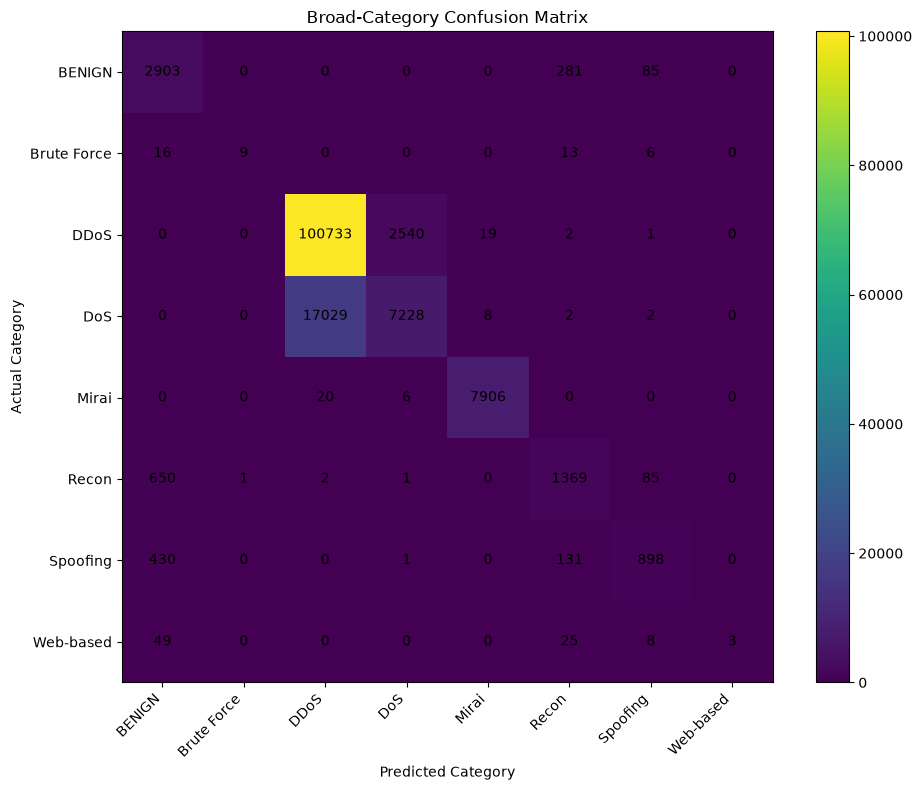

In [119]:
# Broad-category confusion matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

broad_labels = [
    "BENIGN",
    "Brute Force",
    "DDoS",
    "DoS",
    "Mirai",
    "Recon",
    "Spoofing",
    "Web-based"
]

cm_broad = confusion_matrix(
    y_test_broad,
    y_pred_broad,
    labels=broad_labels
)

plt.figure(figsize=(10, 8))
plt.imshow(cm_broad)

plt.xticks(
    range(len(broad_labels)),
    broad_labels,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(broad_labels)),
    broad_labels
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Broad-Category Confusion Matrix")

for i in range(len(broad_labels)):
    for j in range(len(broad_labels)):
        plt.text(
            j,
            i,
            cm_broad[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [120]:
# Check broad-category distribution in train and test data

y_train_broad = np.array([
    category_mapping[int(label)]
    for label in y_train_seq2
])

y_test_broad = np.array([
    category_mapping[int(label)]
    for label in y_test_seq2
])

print("Training broad-category distribution:")
print(
    pd.Series(y_train_broad).value_counts()
)

print("\nTest broad-category distribution:")
print(
    pd.Series(y_test_broad).value_counts()
)

print("\nTraining percentages:")
print(
    (pd.Series(y_train_broad).value_counts(normalize=True) * 100)
    .round(2)
)

print("\nTest percentages:")
print(
    (pd.Series(y_test_broad).value_counts(normalize=True) * 100)
    .round(2)
)

Training broad-category distribution:
DDoS           411824
DoS             98226
Mirai           31732
BENIGN          13308
Recon            8454
Spoofing         5867
Web-based         276
Brute Force       160
Name: count, dtype: int64

Test broad-category distribution:
DDoS           103295
DoS             24269
Mirai            7932
BENIGN           3269
Recon            2108
Spoofing         1460
Web-based          85
Brute Force        44
Name: count, dtype: int64

Training percentages:
DDoS           72.27
DoS            17.24
Mirai           5.57
BENIGN          2.34
Recon           1.48
Spoofing        1.03
Web-based       0.05
Brute Force     0.03
Name: proportion, dtype: float64

Test percentages:
DDoS           72.51
DoS            17.04
Mirai           5.57
BENIGN          2.29
Recon           1.48
Spoofing        1.02
Web-based       0.06
Brute Force     0.03
Name: proportion, dtype: float64


In [121]:
from sklearn.utils.class_weight import compute_class_weight

# Get the broad-category classes
broad_classes = np.unique(y_train_broad)

# Calculate balanced class weights
broad_weights = compute_class_weight(
    class_weight="balanced",
    classes=broad_classes,
    y=y_train_broad
)

broad_class_weight_dict = dict(
    zip(broad_classes, broad_weights)
)

print("Broad-category class weights:\n")

for category, weight in broad_class_weight_dict.items():
    print(f"{category:15s} -> {weight:.2f}")

Broad-category class weights:

BENIGN          -> 5.35
Brute Force     -> 445.19
DDoS            -> 0.17
DoS             -> 0.73
Mirai           -> 2.24
Recon           -> 8.43
Spoofing        -> 12.14
Web-based       -> 258.08


In [122]:
# Softer class weighting using square-root of balanced weights

sqrt_class_weights = {
    category: np.sqrt(weight)
    for category, weight in broad_class_weight_dict.items()
}

print("Softer broad-category class weights:\n")

for category, weight in sqrt_class_weights.items():
    print(f"{category:15s} -> {weight:.2f}")

Softer broad-category class weights:

BENIGN          -> 2.31
Brute Force     -> 21.10
DDoS            -> 0.42
DoS             -> 0.85
Mirai           -> 1.50
Recon           -> 2.90
Spoofing        -> 3.48
Web-based       -> 16.06


In [123]:
# Convert broad-category names into numeric class IDs

broad_label_encoder = LabelEncoder()

y_train_broad_encoded = broad_label_encoder.fit_transform(
    y_train_broad
)

y_test_broad_encoded = broad_label_encoder.transform(
    y_test_broad
)

print("Broad-category label mapping:\n")

for class_id, category in enumerate(broad_label_encoder.classes_):
    print(f"{class_id} -> {category}")

print("\nTraining shape:", y_train_broad_encoded.shape)
print("Test shape:", y_test_broad_encoded.shape)

Broad-category label mapping:

0 -> BENIGN
1 -> Brute Force
2 -> DDoS
3 -> DoS
4 -> Mirai
5 -> Recon
6 -> Spoofing
7 -> Web-based

Training shape: (569847,)
Test shape: (142462,)


In [124]:
# 8-class CNN-LSTM-Attention model

broad_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(broad_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

broad_outputs = Dense(
    8,
    activation="softmax"
)(x)

broad_model = Model(
    inputs=broad_inputs,
    outputs=broad_outputs
)

broad_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

broad_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 2, 39)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 2, 64)          │         5,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 2, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_4 (Attention)         │ (None, 64)             │            66 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,826 (167.29 KB)

 Trainable params: 42,826 (167.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the 8-class CNN-LSTM-Attention model

broad_class_weight_dict_sqrt = {
    broad_label_encoder.transform([category])[0]: weight
    for category, weight in sqrt_class_weights.items()
}

broad_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

broad_history = broad_model.fit(
    X_train_seq2,
    y_train_broad_encoded,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    class_weight=broad_class_weight_dict_sqrt,
    shuffle=False,
    callbacks=broad_callbacks,
    verbose=1
)F

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.7840 - loss: 0.4000 - val_accuracy: 0.8079 - val_loss: 0.3568 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8012 - loss: 0.3273 - val_accuracy: 0.8114 - val_loss: 0.3475 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8053 - loss: 0.3176 - val_accuracy: 0.8114 - val_loss: 0.3447 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8063 - loss: 0.3112 - val_accuracy: 0.8126 - val_loss: 0.3409 - learning_rate: 0.0010
Epoch 5/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.8077 - loss: 0.3081 - val_accuracy: 0.8177 - val_loss: 0.3374 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8082 - loss: 0.3045 - val_accuracy: 0.8118 - val_loss: 0.3398 - learning_rate: 0.0010
Epoch 7/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accurac

In [126]:
# Evaluate the trained 8-class model on the unseen test set

test_loss, test_accuracy = broad_model.evaluate(
    X_test_seq2,
    y_test_broad_encoded,
    batch_size=512,
    verbose=1
)

print("\n8-Class Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("8-Class Test Loss:", round(test_loss, 4))

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8152 - loss: 0.3322

8-Class Test Accuracy: 81.52 %
8-Class Test Loss: 0.3322


In [127]:
# Detailed classification report for the new 8-class model

y_pred_broad_model = np.argmax(
    broad_model.predict(
        X_test_seq2,
        batch_size=512,
        verbose=1
    ),
    axis=1
)

print("8-Class CNN-LSTM-Attention Classification Report:\n")

print(
    classification_report(
        y_test_broad_encoded,
        y_pred_broad_model,
        target_names=broad_label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
8-Class CNN-LSTM-Attention Classification Report:

              precision    recall  f1-score   support

      BENIGN     0.7413    0.8311    0.7837      3269
 Brute Force     0.5909    0.2955    0.3939        44
        DDoS     0.9249    0.8310    0.8754    103295
         DoS     0.4980    0.7128    0.5863     24269
       Mirai     0.9958    0.9963    0.9961      7932
       Recon     0.7191    0.6727    0.6951      2108
    Spoofing     0.7264    0.6438    0.6826      1460
   Web-based     0.1923    0.0588    0.0901        85

    accuracy                         0.8152    142462
   macro avg     0.6736    0.6303    0.6379    142462
weighted avg     0.8463    0.8152    0.8255    142462



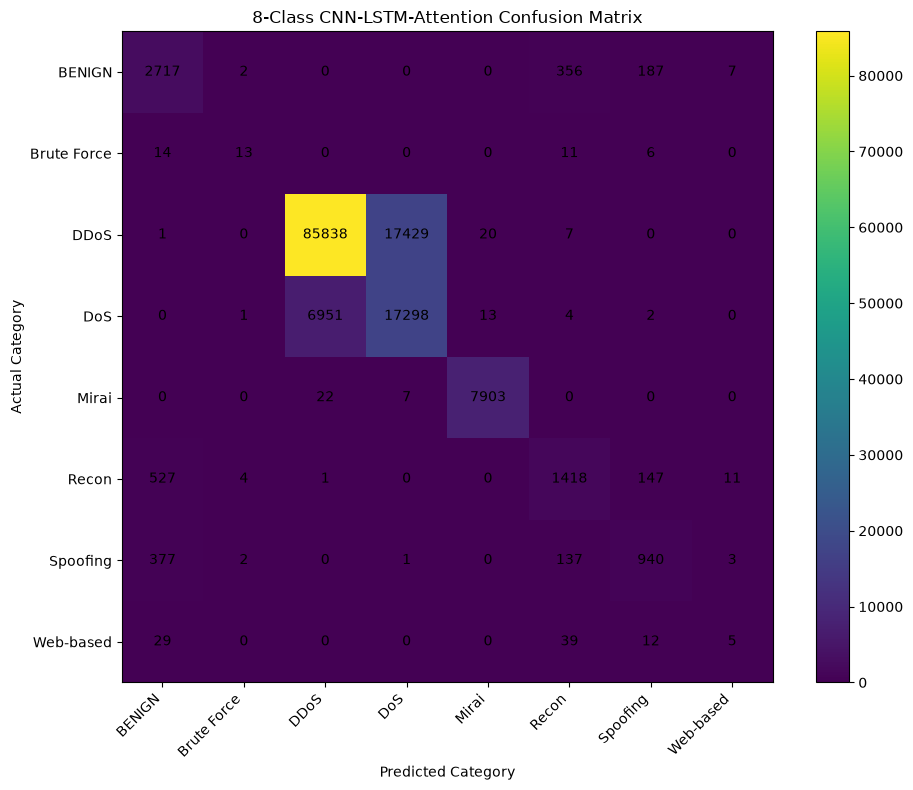

In [128]:
# Confusion matrix for the newly trained 8-class model

cm_broad_model = confusion_matrix(
    y_test_broad_encoded,
    y_pred_broad_model
)

plt.figure(figsize=(10, 8))

plt.imshow(cm_broad_model)

plt.xticks(
    range(len(broad_label_encoder.classes_)),
    broad_label_encoder.classes_,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(broad_label_encoder.classes_)),
    broad_label_encoder.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("8-Class CNN-LSTM-Attention Confusion Matrix")

for i in range(len(broad_label_encoder.classes_)):
    for j in range(len(broad_label_encoder.classes_)):
        plt.text(
            j,
            i,
            cm_broad_model[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [129]:
# Normalize confusion matrix row-wise to percentages

cm_percent = (
    cm_broad_model
    / cm_broad_model.sum(axis=1, keepdims=True)
) * 100

print("Row-wise confusion matrix percentages:\n")

for i, category in enumerate(broad_label_encoder.classes_):
    print(f"\n{category}:")
    
    for j, predicted_category in enumerate(broad_label_encoder.classes_):
        if cm_percent[i, j] >= 1:
            print(
                f"  -> {predicted_category}: "
                f"{cm_percent[i, j]:.2f}%"
            )

Row-wise confusion matrix percentages:


BENIGN:
  -> BENIGN: 83.11%
  -> Recon: 10.89%
  -> Spoofing: 5.72%

Brute Force:
  -> BENIGN: 31.82%
  -> Brute Force: 29.55%
  -> Recon: 25.00%
  -> Spoofing: 13.64%

DDoS:
  -> DDoS: 83.10%
  -> DoS: 16.87%

DoS:
  -> DDoS: 28.64%
  -> DoS: 71.28%

Mirai:
  -> Mirai: 99.63%

Recon:
  -> BENIGN: 25.00%
  -> Recon: 67.27%
  -> Spoofing: 6.97%

Spoofing:
  -> BENIGN: 25.82%
  -> Recon: 9.38%
  -> Spoofing: 64.38%

Web-based:
  -> BENIGN: 34.12%
  -> Recon: 45.88%
  -> Spoofing: 14.12%
  -> Web-based: 5.88%


In [130]:
# Detailed confusion percentages for minority categories

minority_categories = [
    "Brute Force",
    "Recon",
    "Spoofing",
    "Web-based"
]

print("Minority-category confusion percentages:\n")

for category in minority_categories:
    i = list(broad_label_encoder.classes_).index(category)

    print(f"{category}:")
    
    for j, predicted_category in enumerate(broad_label_encoder.classes_):
        print(
            f"  -> {predicted_category}: "
            f"{cm_percent[i, j]:.2f}%"
        )
    
    print()

Minority-category confusion percentages:

Brute Force:
  -> BENIGN: 31.82%
  -> Brute Force: 29.55%
  -> DDoS: 0.00%
  -> DoS: 0.00%
  -> Mirai: 0.00%
  -> Recon: 25.00%
  -> Spoofing: 13.64%
  -> Web-based: 0.00%

Recon:
  -> BENIGN: 25.00%
  -> Brute Force: 0.19%
  -> DDoS: 0.05%
  -> DoS: 0.00%
  -> Mirai: 0.00%
  -> Recon: 67.27%
  -> Spoofing: 6.97%
  -> Web-based: 0.52%

Spoofing:
  -> BENIGN: 25.82%
  -> Brute Force: 0.14%
  -> DDoS: 0.00%
  -> DoS: 0.07%
  -> Mirai: 0.00%
  -> Recon: 9.38%
  -> Spoofing: 64.38%
  -> Web-based: 0.21%

Web-based:
  -> BENIGN: 34.12%
  -> Brute Force: 0.00%
  -> DDoS: 0.00%
  -> DoS: 0.00%
  -> Mirai: 0.00%
  -> Recon: 45.88%
  -> Spoofing: 14.12%
  -> Web-based: 5.88%



In [131]:
# Complete confusion percentages for Web-based category

web_index = list(
    broad_label_encoder.classes_
).index("Web-based")

print("Web-based confusion percentages:\n")

for j, predicted_category in enumerate(
    broad_label_encoder.classes_
):
    print(
        f"Web-based -> {predicted_category}: "
        f"{cm_percent[web_index, j]:.2f}%"
    )

Web-based confusion percentages:

Web-based -> BENIGN: 34.12%
Web-based -> Brute Force: 0.00%
Web-based -> DDoS: 0.00%
Web-based -> DoS: 0.00%
Web-based -> Mirai: 0.00%
Web-based -> Recon: 45.88%
Web-based -> Spoofing: 14.12%
Web-based -> Web-based: 5.88%


In [3]:
# Restore the required imports after kernel restart

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Required imports restored successfully.")

Required imports restored successfully.


In [2]:
# Unweighted 8-class CNN-LSTM-Attention model

unweighted_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(unweighted_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

unweighted_outputs = Dense(
    8,
    activation="softmax"
)(x)

unweighted_model = Model(
    inputs=unweighted_inputs,
    outputs=unweighted_outputs
)

unweighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

unweighted_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

unweighted_history = unweighted_model.fit(
    X_train_seq2,
    y_train_broad_encoded,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=unweighted_callbacks,
    verbose=1
)

NameError: name 'Input' is not defined

In [4]:
# Restore the custom Attention layer after kernel restart

from tensorflow.keras.layers import Layer


class Attention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):

        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        scores = tf.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        attention_weights = tf.nn.softmax(
            scores,
            axis=1
        )

        context = tf.reduce_sum(
            inputs * attention_weights,
            axis=1
        )

        return context


print("Attention layer restored successfully.")

Attention layer restored successfully.


In [6]:
# Restore the saved sequence arrays after kernel restart

X_train_sequences = np.load(
    "data/CICIoT2023/processed/X_train_sequences.npy"
)

y_train_sequences = np.load(
    "data/CICIoT2023/processed/y_train_sequences.npy"
)

X_test_sequences = np.load(
    "data/CICIoT2023/processed/X_test_sequences.npy"
)

y_test_sequences = np.load(
    "data/CICIoT2023/processed/y_test_sequences.npy"
)

print("Saved sequence arrays restored.")

print("X_train_sequences:", X_train_sequences.shape)
print("y_train_sequences:", y_train_sequences.shape)
print("X_test_sequences:", X_test_sequences.shape)
print("y_test_sequences:", y_test_sequences.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'data/CICIoT2023/processed/X_train_sequences.npy'

In [7]:
import os

print(os.getcwd())

c:\Users\pranu1234\Documents\IoT-IDS\notebooks


In [8]:
import os

print(
    os.path.exists(
        "../data/CICIoT2023/processed"
    )
)

print(
    os.listdir(
        "../data/CICIoT2023/processed"
    )
)

True
['X_test_sequences.npy', 'X_train_sequences.npy', 'y_test_sequences.npy', 'y_train_sequences.npy']


In [9]:
X_train_sequences = np.load(
    "../data/CICIoT2023/processed/X_train_sequences.npy"
)

y_train_sequences = np.load(
    "../data/CICIoT2023/processed/y_train_sequences.npy"
)

X_test_sequences = np.load(
    "../data/CICIoT2023/processed/X_test_sequences.npy"
)

y_test_sequences = np.load(
    "../data/CICIoT2023/processed/y_test_sequences.npy"
)

print("Sequence arrays restored successfully.")

print("X_train:", X_train_sequences.shape)
print("y_train:", y_train_sequences.shape)
print("X_test:", X_test_sequences.shape)
print("y_test:", y_test_sequences.shape)

Sequence arrays restored successfully.
X_train: (569844, 5, 39)
y_train: (569844,)
X_test: (142459, 5, 39)
y_test: (142459,)


In [10]:
# Recreate the exact 2-record sequences used in Step 50

sequence_length = 2

X_train_seq2 = []
y_train_seq2 = []

for i in range(len(X_train_sequences) - sequence_length + 1):
    X_train_seq2.append(
        X_train_sequences[i:i + sequence_length]
    )
    y_train_seq2.append(
        y_train_sequences[i + sequence_length - 1]
    )

X_test_seq2 = []
y_test_seq2 = []

for i in range(len(X_test_sequences) - sequence_length + 1):
    X_test_seq2.append(
        X_test_sequences[i:i + sequence_length]
    )
    y_test_seq2.append(
        y_test_sequences[i + sequence_length - 1]
    )

X_train_seq2 = np.array(X_train_seq2)
y_train_seq2 = np.array(y_train_seq2)

X_test_seq2 = np.array(X_test_seq2)
y_test_seq2 = np.array(y_test_seq2)

print("2-record sequences recreated successfully.")

print("X_train_seq2:", X_train_seq2.shape)
print("y_train_seq2:", y_train_seq2.shape)
print("X_test_seq2:", X_test_seq2.shape)
print("y_test_seq2:", y_test_seq2.shape)

2-record sequences recreated successfully.
X_train_seq2: (569843, 2, 5, 39)
y_train_seq2: (569843,)
X_test_seq2: (142458, 2, 5, 39)
y_test_seq2: (142458,)


In [11]:
# Reconstruct the correct 2-record sequences
# from the saved 5-record sequences

X_train_seq2 = X_train_sequences[:, :2, :]
y_train_seq2 = y_train_sequences

X_test_seq2 = X_test_sequences[:, :2, :]
y_test_seq2 = y_test_sequences

# Add the final 3 possible 2-record windows
# from the last 5-record sequence

last_train = X_train_sequences[-1]
last_test = X_test_sequences[-1]

X_train_seq2 = np.concatenate(
    [
        X_train_seq2,
        last_train[1:3][None, :, :],
        last_train[2:4][None, :, :],
        last_train[3:5][None, :, :]
    ],
    axis=0
)

y_train_seq2 = np.concatenate(
    [
        y_train_seq2,
        y_train_sequences[-1:],
        y_train_sequences[-1:],
        y_train_sequences[-1:]
    ]
)

X_test_seq2 = np.concatenate(
    [
        X_test_seq2,
        last_test[1:3][None, :, :],
        last_test[2:4][None, :, :],
        last_test[3:5][None, :, :]
    ],
    axis=0
)

y_test_seq2 = np.concatenate(
    [
        y_test_seq2,
        y_test_sequences[-1:],
        y_test_sequences[-1:],
        y_test_sequences[-1:]
    ]
)

print("Correct 2-record sequences created.")

print("X_train_seq2:", X_train_seq2.shape)
print("y_train_seq2:", y_train_seq2.shape)
print("X_test_seq2:", X_test_seq2.shape)
print("y_test_seq2:", y_test_seq2.shape)

Correct 2-record sequences created.
X_train_seq2: (569847, 2, 39)
y_train_seq2: (569847,)
X_test_seq2: (142462, 2, 39)
y_test_seq2: (142462,)


In [12]:
# Restore broad-category labels

y_train_broad = np.array([
    category_mapping[int(label)]
    for label in y_train_seq2
])

y_test_broad = np.array([
    category_mapping[int(label)]
    for label in y_test_seq2
])

broad_label_encoder = LabelEncoder()

y_train_broad_encoded = broad_label_encoder.fit_transform(
    y_train_broad
)

y_test_broad_encoded = broad_label_encoder.transform(
    y_test_broad
)

print("Broad-category labels restored successfully.")

print("Classes:")
for i, category in enumerate(broad_label_encoder.classes_):
    print(i, "->", category)

print("\nTraining:", y_train_broad_encoded.shape)
print("Test:", y_test_broad_encoded.shape)

NameError: name 'category_mapping' is not defined

In [13]:
# Restore the 34-class to broad-category mapping

category_mapping = {}

category_mapping[0] = "Web-based"
category_mapping[1] = "BENIGN"

for i in range(4, 16):
    category_mapping[i] = "DDoS"

category_mapping[2] = "Web-based"
category_mapping[3] = "Web-based"
category_mapping[16] = "Brute Force"
category_mapping[17] = "Spoofing"

for i in range(18, 22):
    category_mapping[i] = "DoS"

for i in range(22, 25):
    category_mapping[i] = "Mirai"

category_mapping[30] = "Web-based"
category_mapping[31] = "Web-based"
category_mapping[32] = "Recon"
category_mapping[33] = "Web-based"

print("Category mapping restored successfully.")
print("Total mapped classes:", len(category_mapping))

Category mapping restored successfully.
Total mapped classes: 29


In [14]:
# Complete 34-class to broad-category mapping

category_mapping = {
    0: "Web-based",
    1: "BENIGN",
    2: "Web-based",
    3: "Web-based",

    4: "DDoS",
    5: "DDoS",
    6: "DDoS",
    7: "DDoS",
    8: "DDoS",
    9: "DDoS",
    10: "DDoS",
    11: "DDoS",
    12: "DDoS",
    13: "DDoS",
    14: "DDoS",
    15: "DDoS",

    16: "Brute Force",
    17: "Spoofing",

    18: "DoS",
    19: "DoS",
    20: "DoS",
    21: "DoS",

    22: "Mirai",
    23: "Mirai",
    24: "Mirai",

    25: "Recon",
    26: "Recon",
    27: "Recon",
    28: "Recon",
    29: "Recon",

    30: "Web-based",
    31: "Web-based",
    32: "Recon",
    33: "Web-based"
}

print("Category mapping restored successfully.")
print("Total mapped classes:", len(category_mapping))

missing = set(range(34)) - set(category_mapping.keys())

print("Missing class IDs:", missing)

Category mapping restored successfully.
Total mapped classes: 34
Missing class IDs: set()


In [15]:
# Restore the 8 broad-category labels

y_train_broad = np.array([
    category_mapping[int(label)]
    for label in y_train_seq2
])

y_test_broad = np.array([
    category_mapping[int(label)]
    for label in y_test_seq2
])

broad_label_encoder = LabelEncoder()

y_train_broad_encoded = broad_label_encoder.fit_transform(
    y_train_broad
)

y_test_broad_encoded = broad_label_encoder.transform(
    y_test_broad
)

print("Broad-category labels restored successfully.")

print("\nClasses:")
for i, category in enumerate(broad_label_encoder.classes_):
    print(f"{i} -> {category}")

print("\nTraining shape:", y_train_broad_encoded.shape)
print("Test shape:", y_test_broad_encoded.shape)

Broad-category labels restored successfully.

Classes:
0 -> BENIGN
1 -> Brute Force
2 -> DDoS
3 -> DoS
4 -> Mirai
5 -> Recon
6 -> Spoofing
7 -> Web-based

Training shape: (569847,)
Test shape: (142462,)


In [16]:
# Unweighted 8-class CNN-LSTM-Attention model

unweighted_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(unweighted_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

unweighted_outputs = Dense(
    8,
    activation="softmax"
)(x)

unweighted_model = Model(
    inputs=unweighted_inputs,
    outputs=unweighted_outputs
)

unweighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

unweighted_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

unweighted_history = unweighted_model.fit(
    X_train_seq2,
    y_train_broad_encoded,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=unweighted_callbacks,
    verbose=1
)

Epoch 1/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.7207 - loss: 0.9298 - val_accuracy: 0.7248 - val_loss: 0.8944 - learning_rate: 0.0010
Epoch 2/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7225 - loss: 0.9030 - val_accuracy: 0.7248 - val_loss: 0.8942 - learning_rate: 0.0010
Epoch 3/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7225 - loss: 0.9015 - val_accuracy: 0.7248 - val_loss: 0.8941 - learning_rate: 0.0010
Epoch 4/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7225 - loss: 0.9005 - val_accuracy: 0.7248 - val_loss: 0.8942 - learning_rate: 0.0010
Epoch 5/10
1001/1002 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7225 - loss: 0.8993
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7225 - loss: 0.8993 - val_accuracy: 0.7248 - val_loss: 0.8942 - learning_rate: 0.0010
Epoch 6/10
1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy

In [17]:
# Evaluate the current unweighted model on the unseen test set

unweighted_test_loss, unweighted_test_accuracy = (
    unweighted_model.evaluate(
        X_test_seq2,
        y_test_broad_encoded,
        batch_size=512,
        verbose=1
    )
)

print(
    "\nUnweighted 8-Class Test Accuracy:",
    round(unweighted_test_accuracy * 100, 2),
    "%"
)

print(
    "Unweighted 8-Class Test Loss:",
    round(unweighted_test_loss, 4)
)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7251 - loss: 0.8929

Unweighted 8-Class Test Accuracy: 72.51 %
Unweighted 8-Class Test Loss: 0.8929


In [1]:
import os

model_path = "../models/cnn_lstm_attention_final.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model path:")
    print(os.path.abspath(model_path))

Model exists: True
Model path:
c:\Users\pranu1234\Documents\IoT-IDS\models\cnn_lstm_attention_final.keras


In [3]:
import tensorflow as tf

print("TensorFlow restored.")
print("TensorFlow version:", tf.__version__)

TensorFlow restored.
TensorFlow version: 2.21.0


In [5]:
from tensorflow.keras.layers import Layer


class Attention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):

        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        scores = tf.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        attention_weights = tf.nn.softmax(
            scores,
            axis=1
        )

        context = tf.reduce_sum(
            inputs * attention_weights,
            axis=1
        )

        return context


print("Attention restored successfully.")

Attention restored successfully.


In [6]:
# Load the saved best 34-class CNN-LSTM-Attention model

best_model = tf.keras.models.load_model(
    "../models/cnn_lstm_attention_final.keras",
    custom_objects={"Attention": Attention}
)

print("Saved 34-class model loaded successfully.")


Saved 34-class model loaded successfully.


In [7]:
# Evaluate the saved 34-class model

saved_test_loss, saved_test_accuracy = best_model.evaluate(
    X_test_seq2,
    y_test_sequences[:len(X_test_seq2)],
    batch_size=512,
    verbose=1
)

print(
    "\nSaved 34-Class Test Accuracy:",
    round(saved_test_accuracy * 100, 2),
    "%"
)

print(
    "Saved 34-Class Test Loss:",
    round(saved_test_loss, 4)
)

NameError: name 'X_test_seq2' is not defined

In [8]:
# Restore the exact 2-record test sequences

X_test_sequences = np.load(
    "../data/CICIoT2023/processed/X_test_sequences.npy"
)

y_test_sequences = np.load(
    "../data/CICIoT2023/processed/y_test_sequences.npy"
)

X_test_seq2 = X_test_sequences[:, :2, :]
y_test_seq2 = y_test_sequences.copy()

# Add the final 3 two-record windows
last_test = X_test_sequences[-1]

X_test_seq2 = np.concatenate(
    [
        X_test_seq2,
        last_test[1:3][None, :, :],
        last_test[2:4][None, :, :],
        last_test[3:5][None, :, :]
    ],
    axis=0
)

y_test_seq2 = np.concatenate(
    [
        y_test_seq2,
        y_test_sequences[-1:],
        y_test_sequences[-1:],
        y_test_sequences[-1:]
    ]
)

print("Test sequences restored.")

print("X_test_seq2:", X_test_seq2.shape)
print("y_test_seq2:", y_test_seq2.shape)

NameError: name 'np' is not defined

In [9]:
import numpy as np

print("NumPy restored.")
print("NumPy version:", np.__version__)

NumPy restored.
NumPy version: 2.5.3


In [5]:
# Unweighted 8-class CNN-LSTM-Attention model

unweighted_inputs = Input(shape=(2, 39))

x = Conv1D(
    filters=64,
    kernel_size=2,
    padding="same",
    activation="relu"
)(unweighted_inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

unweighted_outputs = Dense(
    8,
    activation="softmax"
)(x)

unweighted_model = Model(
    inputs=unweighted_inputs,
    outputs=unweighted_outputs
)

unweighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

unweighted_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

unweighted_history = unweighted_model.fit(
    X_train_seq2,
    y_train_broad_encoded,
    validation_split=0.1,
    epochs=10,
    batch_size=512,
    shuffle=False,
    callbacks=unweighted_callbacks,
    verbose=1
)

NameError: name 'X_train_seq2' is not defined

In [1]:
# Evaluate the unweighted 8-class model on the unseen test set

unweighted_test_loss, unweighted_test_accuracy = (
    unweighted_model.evaluate(
        X_test_seq2,
        y_test_broad_encoded,
        batch_size=512,
        verbose=1
    )
)

print(
    "\nUnweighted 8-Class Test Accuracy:",
    round(unweighted_test_accuracy * 100, 2),
    "%"
)

print(
    "Unweighted 8-Class Test Loss:",
    round(unweighted_test_loss, 4)
)

NameError: name 'unweighted_model' is not defined

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Get the broad-category classes
broad_classes = np.unique(y_train_broad)

# Calculate balanced class weights
broad_weights = compute_class_weight(
    class_weight="balanced",
    classes=broad_classes,
    y=y_train_broad
)

broad_class_weight_dict = dict(
    zip(broad_classes, broad_weights)
)

print("Broad-category class weights:\n")

for category, weight in broad_class_weight_dict.items():
    print(f"{category:15s} -> {weight:.2f}")

In [79]:
classes = np.unique(y_train_sequences)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_sequences
)

class_weight_dict = dict(
    zip(classes, class_weights)
)

print("Number of classes:", len(classes))

for class_id, weight in class_weight_dict.items():
    print(
        class_id,
        "→",
        label_encoder.inverse_transform([class_id])[0],
        "→",
        round(weight, 2)
    )

Number of classes: 34
0 → BACKDOOR_MALWARE → 523.75
1 → BENIGN → 1.26
2 → BROWSERHIJACKING → 257.85
3 → COMMANDINJECTION → 299.29
4 → DDOS-ACK_FRAGMENTATION → 4.86
5 → DDOS-HTTP_FLOOD → 51.73
6 → DDOS-ICMP_FLOOD → 0.19
7 → DDOS-ICMP_FRAGMENTATION → 3.06
8 → DDOS-PSHACK_FLOOD → 0.34
9 → DDOS-RSTFINFLOOD → 0.34
10 → DDOS-SLOWLORIS → 57.99
11 → DDOS-SYNONYMOUSIP_FLOOD → 0.38
12 → DDOS-SYN_FLOOD → 0.34
13 → DDOS-TCP_FLOOD → 0.31
14 → DDOS-UDP_FLOOD → 0.26
15 → DDOS-UDP_FRAGMENTATION → 4.87
16 → DICTIONARYBRUTEFORCE → 104.75
17 → DNS_SPOOFING → 7.67
18 → DOS-HTTP_FLOOD → 18.94
19 → DOS-SYN_FLOOD → 0.68
20 → DOS-TCP_FLOOD → 0.52
21 → DOS-UDP_FLOOD → 0.42
22 → MIRAI-GREETH_FLOOD → 1.38
23 → MIRAI-GREIP_FLOOD → 1.87
24 → MIRAI-UDPPLAIN → 1.57
25 → MITM-ARPSPOOFING → 4.55
26 → RECON-HOSTDISCOVERY → 10.36
27 → RECON-OSSCAN → 14.41
28 → RECON-PINGSWEEP → 644.62
29 → RECON-PORTSCAN → 16.35
30 → SQLINJECTION → 279.34
31 → UPLOADING_ATTACK → 1289.24
32 → VULNERABILITYSCAN → 3.63
33 → XSS → 335.2


In [80]:
same_label = np.mean(
    y_train_sequences[:-1] == y_train_sequences[1:]
)

print("Adjacent label consistency:", same_label)
print("Percentage:", same_label * 100)

Adjacent label consistency: 0.08600614555237145
Percentage: 8.600614555237145


In [81]:
window_purity = []

for i in range(len(y_train_sequences)):
    # Get the labels corresponding to this 5-record window
    labels = y_train_seq[i:i + sequence_length]

    # Fraction belonging to the most common label
    _, counts = np.unique(labels, return_counts=True)
    purity = counts.max() / sequence_length

    window_purity.append(purity)

print("Average 5-record window purity:",
      np.mean(window_purity))

print("Percentage of pure windows:",
      np.mean(np.array(window_purity) == 1.0) * 100)

print("Percentage with at least 80% same label:",
      np.mean(np.array(window_purity) >= 0.8) * 100)

Average 5-record window purity: 0.3383547076041864
Percentage of pure windows: 0.013161496830711562
Percentage with at least 80% same label: 0.45872203620640034


In [71]:
inputs = Input(shape=(timesteps, num_features))

x = Conv1D(
    filters=64,
    kernel_size=3,
    activation="relu",
    padding="same"
)(inputs)

x = LSTM(
    64,
    return_sequences=True
)(x)

x = Attention()(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(
    num_classes,
    activation="softmax"
)(x)

model = Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 5, 39)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 64)          │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_1 (Attention)         │ (None, 64)             │            69 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 34)             │         2,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,015 (183.65 KB)

 Trainable params: 47,015 (183.65 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
history = model.fit(
    X_train_sequences,
    y_train_sequences,
    epochs=1,
    batch_size=512,
    validation_split=0.1,
    class_weight=class_weight_dict,
    shuffle=False,
    verbose=1
)

1002/1002 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - accuracy: 0.4198 - loss: 2.3344 - val_accuracy: 0.6647 - val_loss: 0.6761


In [73]:
test_loss, test_accuracy = model.evaluate(
    X_test_sequences,
    y_test_sequences,
    batch_size=512,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6678 - loss: 0.6743

Test Loss: 0.6742589473724365
Test Accuracy: 0.6678342819213867


In [74]:
from sklearn.metrics import classification_report

test_probs = model.predict(
    X_test_sequences,
    batch_size=512,
    verbose=1
)

test_predictions = np.argmax(test_probs, axis=1)

report = classification_report(
    y_test_sequences,
    test_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
)

print(report)

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
                         precision    recall  f1-score   support

       BACKDOOR_MALWARE       0.00      0.00      0.00         9
                 BENIGN       0.59      0.59      0.59      3269
       BROWSERHIJACKING       0.00      0.00      0.00        18
       COMMANDINJECTION       0.00      0.00      0.00        17
 DDOS-ACK_FRAGMENTATION       0.98      0.97      0.97       859
        DDOS-HTTP_FLOOD       0.80      0.04      0.08        92
        DDOS-ICMP_FLOOD       1.00      1.00      1.00     21941
DDOS-ICMP_FRAGMENTATION       0.99      0.98      0.98      1303
      DDOS-PSHACK_FLOOD       1.00      0.99      0.99     12343
       DDOS-RSTFINFLOOD       0.99      1.00      0.99     12351
         DDOS-SLOWLORIS       0.21      0.65      0.31        65
DDOS-SYNONYMOUSIP_FLOOD       0.41      0.79      0.54     11209
         DDOS-SYN_FLOOD       0.55      0.01      0.02     12375
         DDOS-TCP_FLOOD       0.65      0.49    

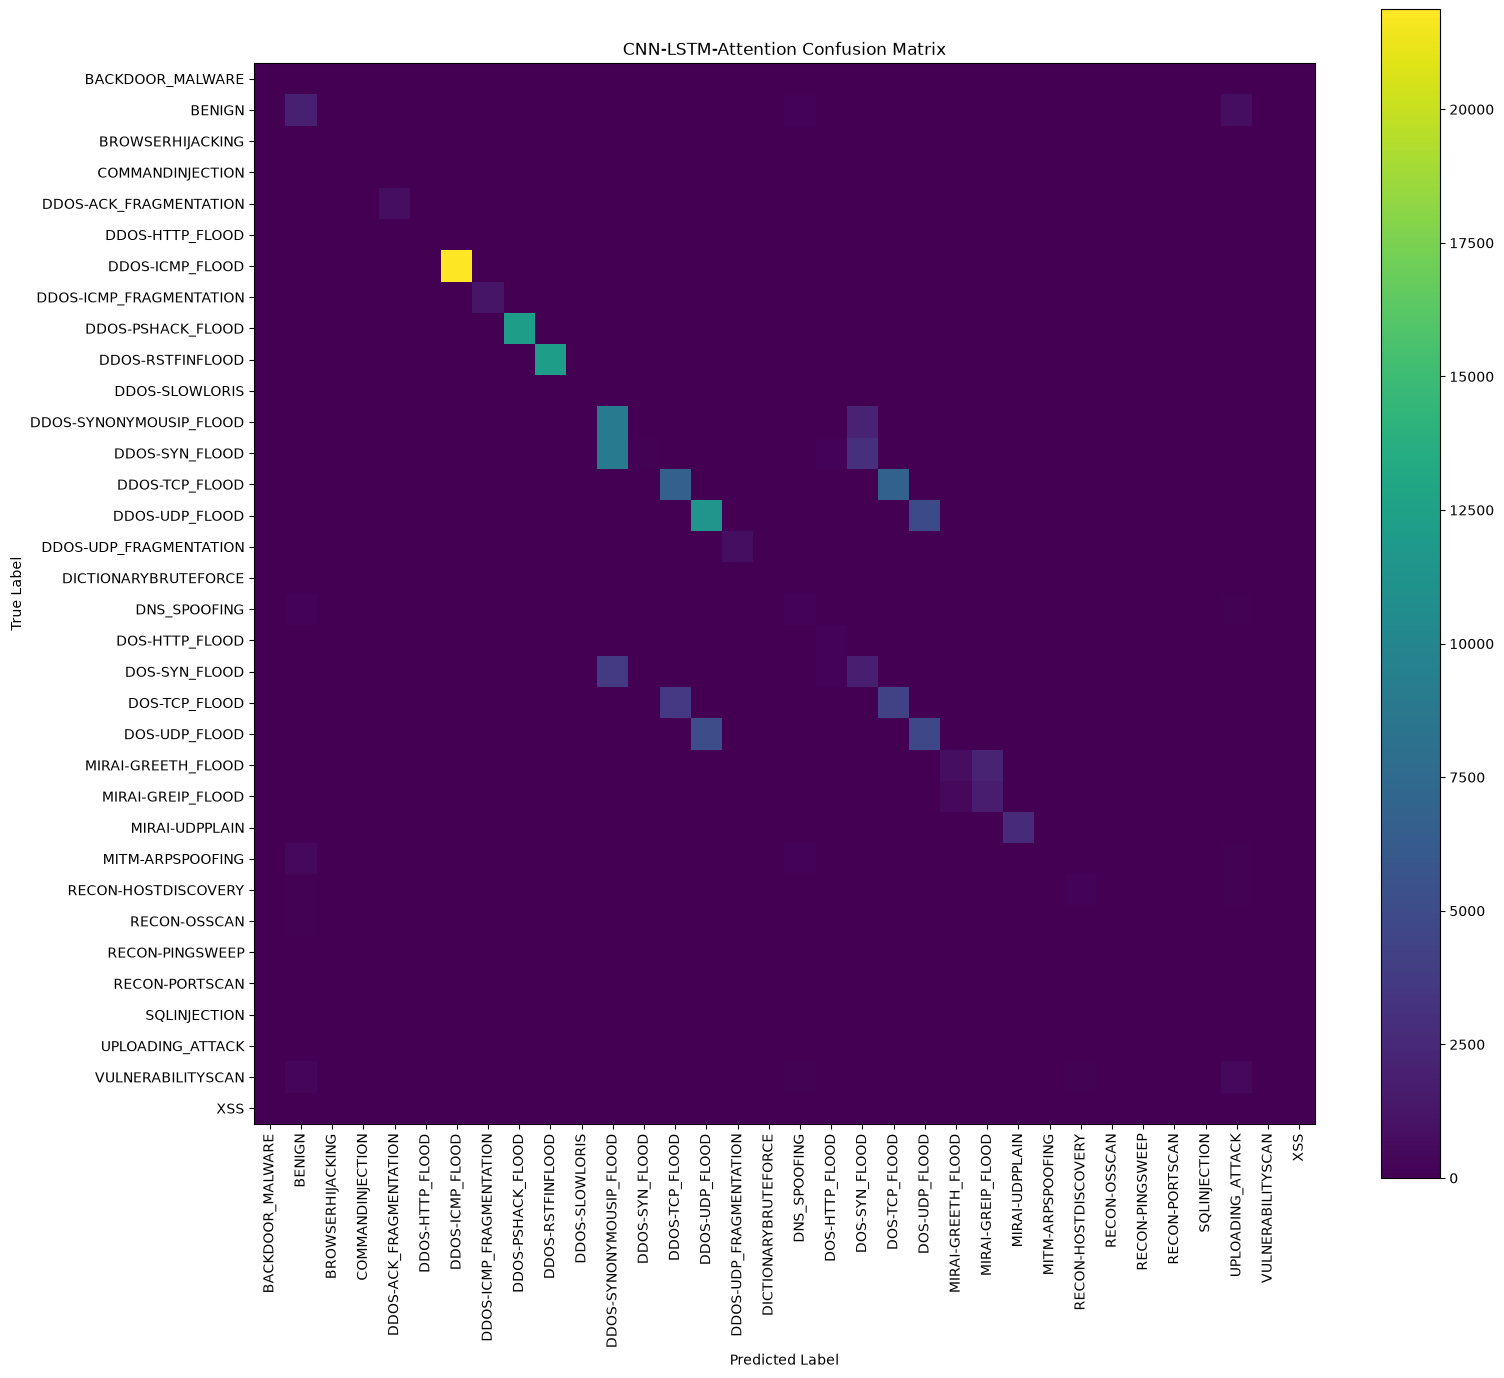

In [76]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_sequences,
    test_predictions
)

plt.figure(figsize=(16, 14))

plt.imshow(cm, interpolation="nearest")
plt.title("CNN-LSTM-Attention Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=90
)

plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

plt.colorbar()

plt.tight_layout()
plt.show()

In [77]:
from pathlib import Path

RESULTS_FIGURES = Path("../results/figures")
RESULTS_FIGURES.mkdir(parents=True, exist_ok=True)

cm_path = RESULTS_FIGURES / "confusion_matrix_cnn_lstm_attention.png"

plt.savefig(cm_path, dpi=300, bbox_inches="tight")

print("Saved to:", cm_path)

Saved to: ..\results\figures\confusion_matrix_cnn_lstm_attention.png


<Figure size 640x480 with 0 Axes>

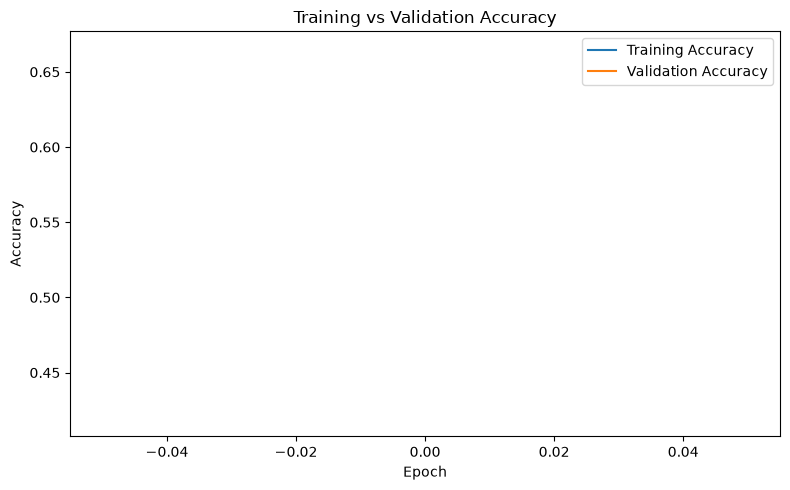

Saved to: ..\results\figures\training_validation_accuracy.png


In [78]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()

accuracy_path = RESULTS_FIGURES / "training_validation_accuracy.png"
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved to:", accuracy_path)

In [ ]:
import sys
sys.path.append("../src")

from model import build_model

model = build_model(
    timesteps=5,
    num_features=39,
    num_classes=34
)

print("Model ready!")

In [5]:
history_more = model.fit(
    X_train_sequences,
    y_train_sequences,
    initial_epoch=1,
    epochs=15,
    batch_size=512,
    validation_split=0.1,
    class_weight=class_weight_dict,
    shuffle=False,
    verbose=1
)

NameError: name 'model' is not defined

In [80]:
full_history = {
    "accuracy": (
        history.history["accuracy"]
        + history_more.history["accuracy"]
    ),
    "val_accuracy": (
        history.history["val_accuracy"]
        + history_more.history["val_accuracy"]
    ),
    "loss": (
        history.history["loss"]
        + history_more.history["loss"]
    ),
    "val_loss": (
        history.history["val_loss"]
        + history_more.history["val_loss"]
    )
}

print("Training accuracy:", full_history["accuracy"])
print("Validation accuracy:", full_history["val_accuracy"])
print("Training loss:", full_history["loss"])
print("Validation loss:", full_history["val_loss"])

Training accuracy: [0.4197605848312378, 0.6492466926574707, 0.6651574969291687]
Validation accuracy: [0.6647012233734131, 0.6738264560699463, 0.6818811893463135]
Training loss: [2.334402561187744, 1.5416549444198608, 1.4385391473770142]
Validation loss: [0.6760682463645935, 0.6346045136451721, 0.6178178191184998]


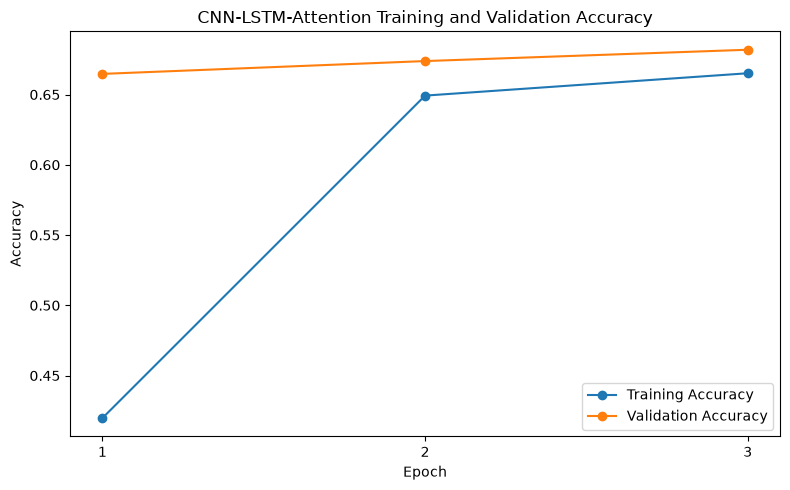

Accuracy graph saved to: ..\results\figures\training_validation_accuracy.png


In [81]:
epochs = range(1, 4)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    full_history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    full_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN-LSTM-Attention Training and Validation Accuracy")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()

accuracy_path = RESULTS_FIGURES / "training_validation_accuracy.png"
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()

print("Accuracy graph saved to:", accuracy_path)

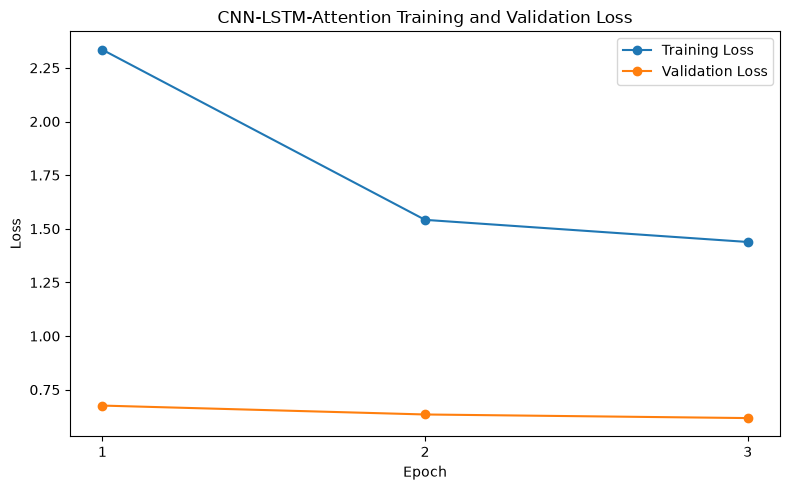

Loss graph saved to: ..\results\figures\training_validation_loss.png


In [82]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    full_history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    full_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN-LSTM-Attention Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()

loss_path = RESULTS_FIGURES / "training_validation_loss.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()

print("Loss graph saved to:", loss_path)

In [83]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "cnn_lstm_attention.keras"

model.save(model_path)

print("Model saved to:", model_path)

Model saved to: ..\models\cnn_lstm_attention.keras


In [84]:
import shap

print("SHAP version:", shap.__version__)
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.52.0
Model input shape: (None, 5, 39)
Model output shape: (None, 34)


In [ ]:
from pathlib import Path

RESULTS_FIGURES = Path("../results/figures")
RESULTS_FIGURES.mkdir(parents=True, exist_ok=True)

cm_path = RESULTS_FIGURES / "confusion_matrix_cnn_lstm_attention.png"

plt.savefig(cm_path, dpi=300, bbox_inches="tight")

print("Saved to:", cm_path)

Saved to: ..\results\figures\confusion_matrix_cnn_lstm_attention.png


<Figure size 640x480 with 0 Axes>

In [85]:
shap_background = X_train_sequences[:50]

print("SHAP background shape:", shap_background.shape)

SHAP background shape: (50, 5, 39)


In [86]:
explainer = shap.DeepExplainer(
    model,
    shap_background
)

print("SHAP DeepExplainer created successfully.")

SHAP DeepExplainer created successfully.


c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\shap\explainers\_deep\deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_7
Received: inputs=['Tensor(shape=(50, 5, 39))']
  warnings.warn(msg)


In [87]:
shap_test = X_test_sequences[:1]

shap_values = explainer.shap_values(shap_test)

print("SHAP calculation completed.")

if isinstance(shap_values, list):
    print("Number of outputs:", len(shap_values))
    print("First output shape:", np.array(shap_values[0]).shape)
else:
    print("SHAP values shape:", np.array(shap_values).shape)

c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_7
Received: inputs=['Tensor(shape=(100, 5, 39))']
  warnings.warn(msg)


StagingError: in user code:

    File "c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\shap\explainers\_deep\deep_tf.py", line 265, in grad_graph  *
        x_grad = tape.gradient(out, shap_rAnD)

    LookupError: gradient registry has no entry for: shap_BatchMatMulV2


In [88]:
gradient_explainer = shap.GradientExplainer(
    model,
    shap_background
)

print("SHAP GradientExplainer created successfully.")

SHAP GradientExplainer created successfully.


In [89]:
shap_test = X_test_sequences[:1]

gradient_shap_values = gradient_explainer.shap_values(shap_test)

print("SHAP calculation completed.")

if isinstance(gradient_shap_values, list):
    print("Number of outputs:", len(gradient_shap_values))
    print("First output shape:",
          np.array(gradient_shap_values[0]).shape)
else:
    print("SHAP values shape:",
          np.array(gradient_shap_values).shape)

c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_7
Received: inputs=['Tensor(shape=(1, 5, 39))']
  warnings.warn(msg)


StagingError: in user code:

    File "c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\shap\explainers\_gradient.py", line 304, in grad_graph  *
        x_grad = tape.gradient(out, x)

    LookupError: gradient registry has no entry for: shap_StridedSlice


In [90]:
# One test sequence
shap_test = X_test_sequences[:1]

# Get the class predicted by our model
sample_prediction = model.predict(shap_test, verbose=0)
predicted_class = np.argmax(sample_prediction[0])

predicted_label = label_encoder.inverse_transform(
    [predicted_class]
)[0]

print("Predicted class ID:", predicted_class)
print("Predicted label:", predicted_label)

# Flatten sequence: 5 × 39 = 195 values
background_flat = shap_background.reshape(
    shap_background.shape[0], -1
)

test_flat = shap_test.reshape(
    shap_test.shape[0], -1
)

print("Background shape:", background_flat.shape)
print("Test shape:", test_flat.shape)

Predicted class ID: 9
Predicted label: DDOS-RSTFINFLOOD
Background shape: (50, 195)
Test shape: (1, 195)


In [91]:
def model_predict_flattened(X_flat):
    X_sequence = X_flat.reshape(-1, 5, 39)
    return model.predict(X_sequence, verbose=0)

print("SHAP prediction wrapper created.")

SHAP prediction wrapper created.


In [92]:
kernel_explainer = shap.KernelExplainer(
    model_predict_flattened,
    background_flat
)

print("SHAP KernelExplainer created successfully.")

SHAP KernelExplainer created successfully.


In [93]:
kernel_shap_values, top_indexes = kernel_explainer.shap_values(
    test_flat,
    nsamples=100,
    ranked_outputs=1
)

print("SHAP calculation completed.")
print("SHAP values shape:", np.array(kernel_shap_values).shape)
print("Top predicted class index:", top_indexes)

100%|██████████| 1/1 [00:01<00:00,  1.59s/it]


ValueError: not enough values to unpack (expected 2, got 1)

In [94]:
kernel_shap_values = kernel_explainer.shap_values(
    test_flat,
    nsamples=100,
    ranked_outputs=1
)

print("SHAP calculation completed.")
print("SHAP values type:", type(kernel_shap_values))
print("SHAP values shape:", np.array(kernel_shap_values).shape)

100%|██████████| 1/1 [00:01<00:00,  1.35s/it]

SHAP calculation completed.
SHAP values type: <class 'numpy.ndarray'>
SHAP values shape: (1, 195, 34)


In [95]:
predicted_class = 9

shap_array = np.array(kernel_shap_values)

# SHAP values for the predicted class
class_shap = shap_array[0, :, predicted_class]

# Restore sequence structure
class_shap = class_shap.reshape(5, 39)

print("Predicted class:", predicted_class)
print("Predicted label:",
      label_encoder.inverse_transform([predicted_class])[0])

print("SHAP matrix shape:", class_shap.shape)

print("Mean absolute SHAP value:",
      np.mean(np.abs(class_shap)))

Predicted class: 9
Predicted label: DDOS-RSTFINFLOOD
SHAP matrix shape: (5, 39)
Mean absolute SHAP value: 0.004919117669387084


In [96]:
feature_names = X.columns.tolist()

feature_importance = np.mean(
    np.abs(class_shap),
    axis=0
)

top_indices = np.argsort(
    feature_importance
)[::-1][:10]

print("Top 10 features for:",
      label_encoder.inverse_transform([predicted_class])[0])

for rank, idx in enumerate(top_indices, start=1):
    print(
        rank,
        "→",
        feature_names[idx],
        "→",
        round(feature_importance[idx], 6)
    )

Top 10 features for: DDOS-RSTFINFLOOD
1 → fin_flag_number → 0.054266
2 → fin_count → 0.041603
3 → rst_count → 0.02075
4 → Min → 0.018798
5 → HTTPS → 0.016896
6 → UDP → 0.014573
7 → DNS → 0.011738
8 → ARP → 0.009876
9 → Rate → 0.003346
10 → Std → 0.0


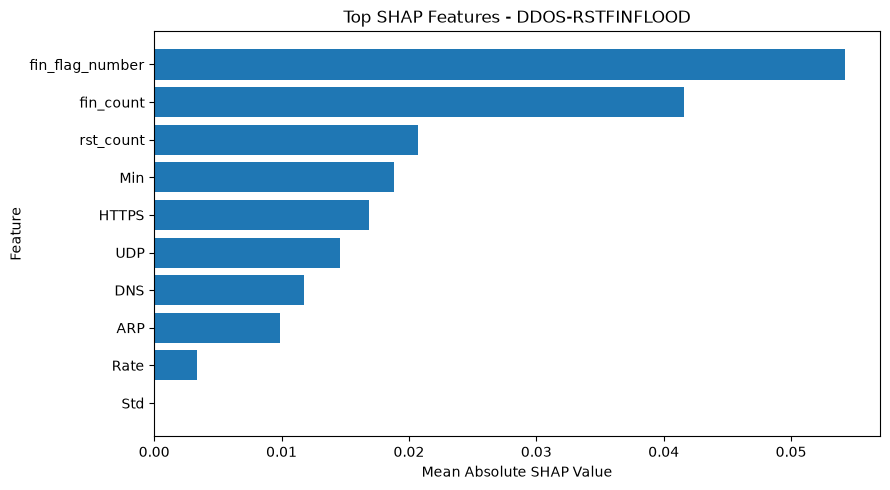

SHAP graph saved to: ..\results\figures\shap_feature_importance_ddos_rstfinflood.png


In [97]:
top_features = [feature_names[i] for i in top_indices]
top_values = feature_importance[top_indices]

plt.figure(figsize=(9, 5))

plt.barh(
    top_features[::-1],
    top_values[::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title(
    "Top SHAP Features - DDOS-RSTFINFLOOD"
)

plt.tight_layout()

shap_path = RESULTS_FIGURES / "shap_feature_importance_ddos_rstfinflood.png"

plt.savefig(
    shap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP graph saved to:", shap_path)

In [98]:
from sklearn.metrics import classification_report

report_dict = classification_report(
    y_test_sequences,
    test_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T

metrics_dir = Path("../results/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

report_path = metrics_dir / "classification_report_cnn_lstm_attention.csv"

report_df.to_csv(report_path)

print("Classification report saved to:", report_path)

Classification report saved to: ..\results\metrics\classification_report_cnn_lstm_attention.csv


In [99]:
label_mapping = pd.DataFrame({
    "encoded_id": range(len(label_encoder.classes_)),
    "label": label_encoder.classes_
})

mapping_path = metrics_dir / "label_mapping.csv"

label_mapping.to_csv(
    mapping_path,
    index=False
)

print("Label mapping saved to:", mapping_path)

Label mapping saved to: ..\results\metrics\label_mapping.csv


In [100]:
import joblib

scaler_path = MODEL_DIR / "ordered_scaler.pkl"

joblib.dump(
    ordered_scaler,
    scaler_path
)

print("Scaler saved to:", scaler_path)

Scaler saved to: ..\models\ordered_scaler.pkl


In [101]:
final_test_loss, final_test_accuracy = model.evaluate(
    X_test_sequences,
    y_test_sequences,
    batch_size=512,
    verbose=1
)

print("\nFinal Test Loss:", final_test_loss)
print("Final Test Accuracy:", final_test_accuracy)

279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6877 - loss: 0.6173

Final Test Loss: 0.617280125617981
Final Test Accuracy: 0.6876996159553528


In [102]:
final_test_probs = model.predict(
    X_test_sequences,
    batch_size=512,
    verbose=1
)

final_test_predictions = np.argmax(
    final_test_probs,
    axis=1
)

final_report = classification_report(
    y_test_sequences,
    final_test_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
)

print(final_report)

279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
                         precision    recall  f1-score   support

       BACKDOOR_MALWARE       0.00      0.00      0.00         9
                 BENIGN       0.71      0.38      0.49      3269
       BROWSERHIJACKING       0.14      0.06      0.08        18
       COMMANDINJECTION       0.00      0.00      0.00        17
 DDOS-ACK_FRAGMENTATION       0.98      0.97      0.98       859
        DDOS-HTTP_FLOOD       0.73      0.51      0.60        92
        DDOS-ICMP_FLOOD       1.00      1.00      1.00     21941
DDOS-ICMP_FRAGMENTATION       0.98      0.98      0.98      1303
      DDOS-PSHACK_FLOOD       1.00      0.99      1.00     12343
       DDOS-RSTFINFLOOD       1.00      1.00      1.00     12351
         DDOS-SLOWLORIS       0.23      0.85      0.36        65
DDOS-SYNONYMOUSIP_FLOOD       0.43      0.70      0.53     11209
         DDOS-SYN_FLOOD       0.53      0.08      0.14     12375
         DDOS-TCP_FLOOD       0.68      0.58   

In [103]:
final_report_dict = classification_report(
    y_test_sequences,
    final_test_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

final_report_df = pd.DataFrame(final_report_dict).T

final_report_path = metrics_dir / "final_classification_report_cnn_lstm_attention.csv"

final_report_df.to_csv(final_report_path)

print("Final classification report saved to:", final_report_path)

Final classification report saved to: ..\results\metrics\final_classification_report_cnn_lstm_attention.csv


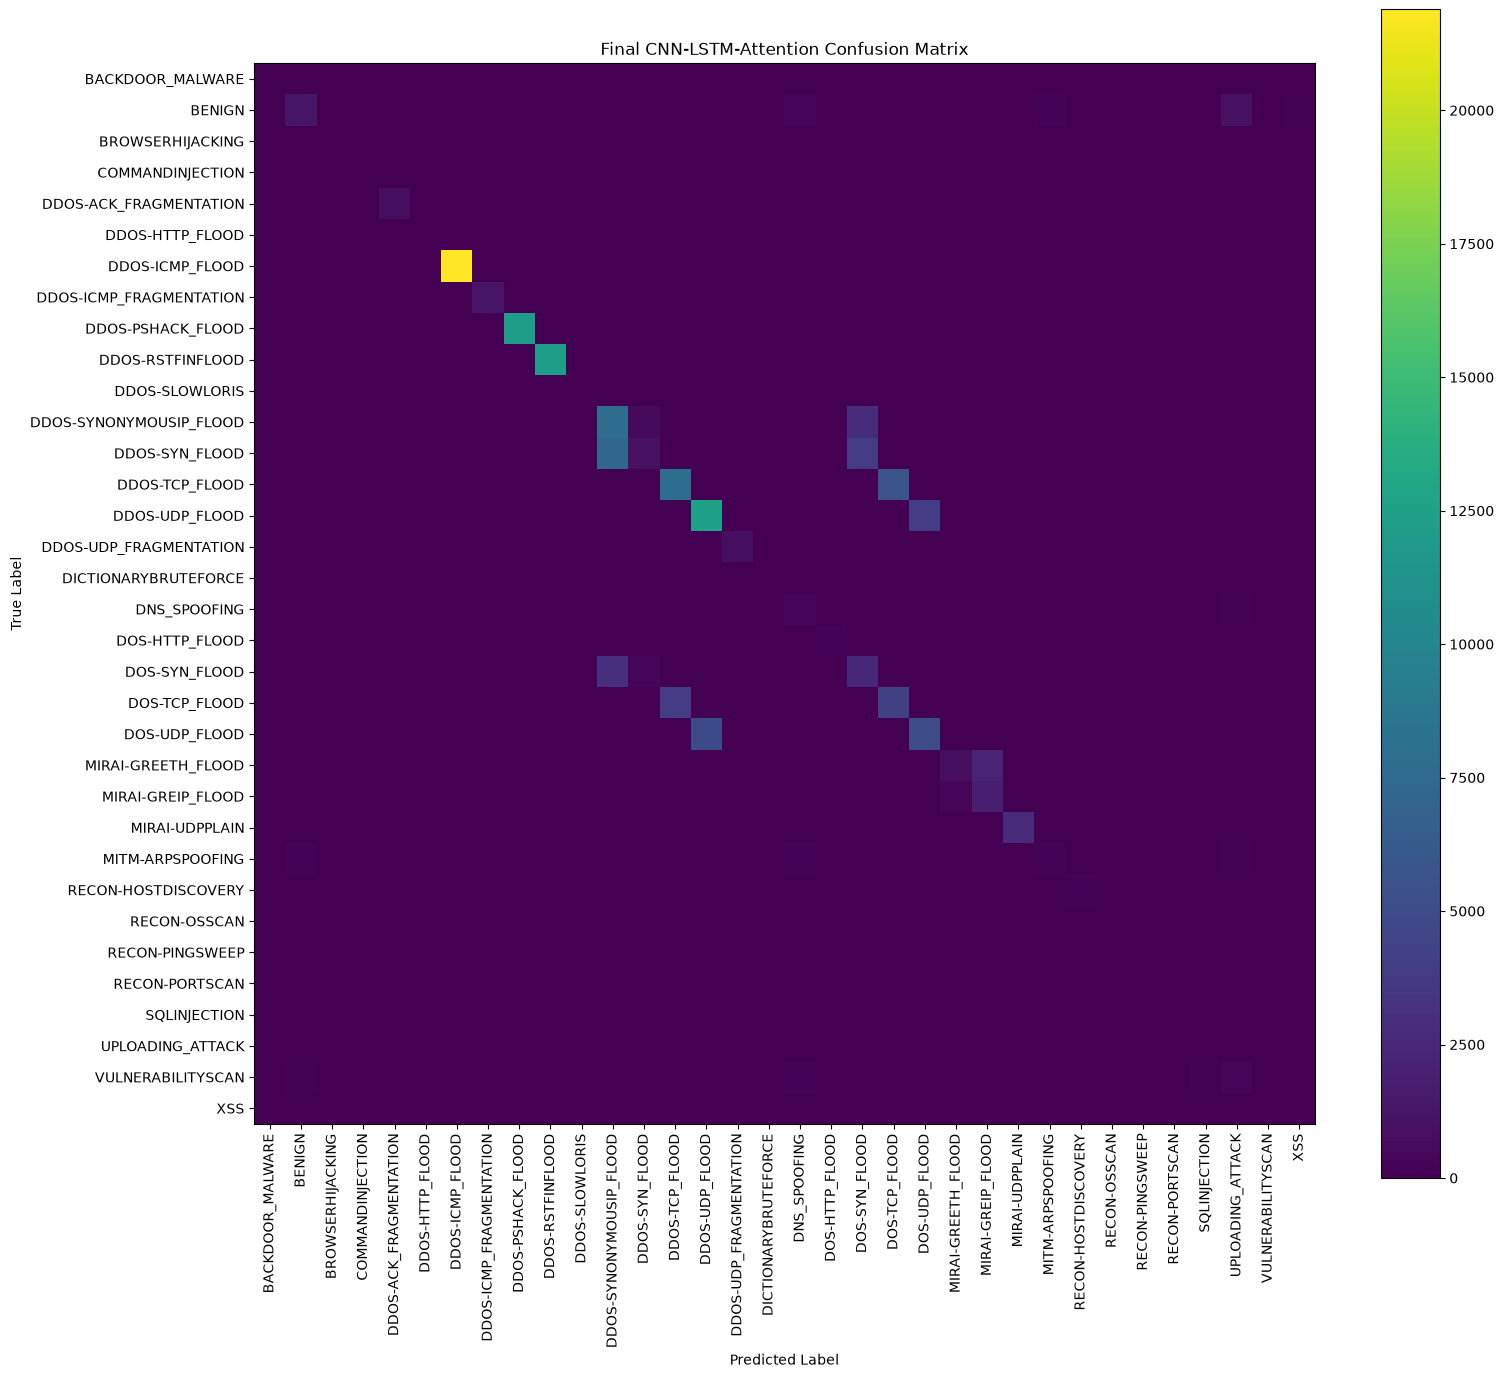

Final confusion matrix saved to: ..\results\figures\final_confusion_matrix_cnn_lstm_attention.png


In [104]:
final_cm = confusion_matrix(
    y_test_sequences,
    final_test_predictions
)

plt.figure(figsize=(16, 14))

plt.imshow(final_cm, interpolation="nearest")

plt.title("Final CNN-LSTM-Attention Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=90
)

plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

plt.colorbar()
plt.tight_layout()

final_cm_path = RESULTS_FIGURES / "final_confusion_matrix_cnn_lstm_attention.png"

plt.savefig(
    final_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final confusion matrix saved to:", final_cm_path)

In [105]:
final_model_path = MODEL_DIR / "cnn_lstm_attention_final.keras"

model.save(final_model_path)

print("Final model saved to:", final_model_path)

Final model saved to: ..\models\cnn_lstm_attention_final.keras


In [106]:
feature_names_df = pd.DataFrame({
    "feature_index": range(len(feature_names)),
    "feature_name": feature_names
})

feature_names_path = metrics_dir / "feature_names.csv"

feature_names_df.to_csv(
    feature_names_path,
    index=False
)

print("Feature names saved to:", feature_names_path)

Feature names saved to: ..\results\metrics\feature_names.csv


In [107]:
history_df = pd.DataFrame({
    "epoch": [1, 2, 3],
    "training_accuracy": full_history["accuracy"],
    "validation_accuracy": full_history["val_accuracy"],
    "training_loss": full_history["loss"],
    "validation_loss": full_history["val_loss"]
})

history_path = metrics_dir / "training_history_cnn_lstm_attention.csv"

history_df.to_csv(
    history_path,
    index=False
)

print("Training history saved to:", history_path)
print("\n", history_df)

Training history saved to: ..\results\metrics\training_history_cnn_lstm_attention.csv

    epoch  training_accuracy  validation_accuracy  training_loss  \
0      1           0.419761             0.664701       2.334403   
1      2           0.649247             0.673826       1.541655   
2      3           0.665157             0.681881       1.438539   

   validation_loss  
0         0.676068  
1         0.634605  
2         0.617818  


In [108]:
summary_path = MODEL_DIR / "cnn_lstm_attention_model_summary.txt"

with open(summary_path, "w") as f:
    model.summary(print_fn=lambda x: f.write(x + "\n"))

print("Model summary saved to:", summary_path)

UnicodeEncodeError: 'charmap' codec can't encode characters in position 23-98: character maps to <undefined>

In [109]:
summary_path = MODEL_DIR / "cnn_lstm_attention_model_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    model.summary(print_fn=lambda x: f.write(x + "\n"))

print("Model summary saved to:", summary_path)

Model summary saved to: ..\models\cnn_lstm_attention_model_summary.txt


In [110]:
final_kernel_explainer = shap.KernelExplainer(
    model_predict_flattened,
    background_flat
)

final_kernel_shap_values = final_kernel_explainer.shap_values(
    test_flat,
    nsamples=100,
    ranked_outputs=1
)

print("Final SHAP calculation completed.")
print(
    "SHAP values shape:",
    np.array(final_kernel_shap_values).shape
)

100%|██████████| 1/1 [00:01<00:00,  1.29s/it]

Final SHAP calculation completed.
SHAP values shape: (1, 195, 34)


In [112]:
shap_test = X_test_sequences[:1]

final_shap_prediction = model.predict(
    shap_test,
    verbose=0
)

final_predicted_class = np.argmax(
    final_shap_prediction[0]
)

final_predicted_label = label_encoder.inverse_transform(
    [final_predicted_class]
)[0]

print("Final predicted class:", final_predicted_class)
print("Final predicted label:", final_predicted_label)

Final predicted class: 9
Final predicted label: DDOS-RSTFINFLOOD


In [113]:
final_shap_array = np.array(final_kernel_shap_values)

# SHAP values for predicted class
final_class_shap = final_shap_array[
    0, :, final_predicted_class
]

# Convert back: 195 → 5 × 39
final_class_shap = final_class_shap.reshape(5, 39)

# Average importance across 5 timesteps
final_feature_importance = np.mean(
    np.abs(final_class_shap),
    axis=0
)

final_top_indices = np.argsort(
    final_feature_importance
)[::-1][:10]

print("Top 10 features for:", final_predicted_label)

for rank, idx in enumerate(final_top_indices, start=1):
    print(
        rank,
        "→",
        feature_names[idx],
        "→",
        round(final_feature_importance[idx], 6)
    )

Top 10 features for: DDOS-RSTFINFLOOD
1 → IAT → 0.037874
2 → fin_flag_number → 0.037531
3 → Header_Length → 0.033987
4 → fin_count → 0.0205
5 → IPv → 0.019921
6 → Protocol Type → 0.018179
7 → UDP → 0.015933
8 → ack_flag_number → 0.00415
9 → Tot size → 0.003771
10 → Max → 0.0


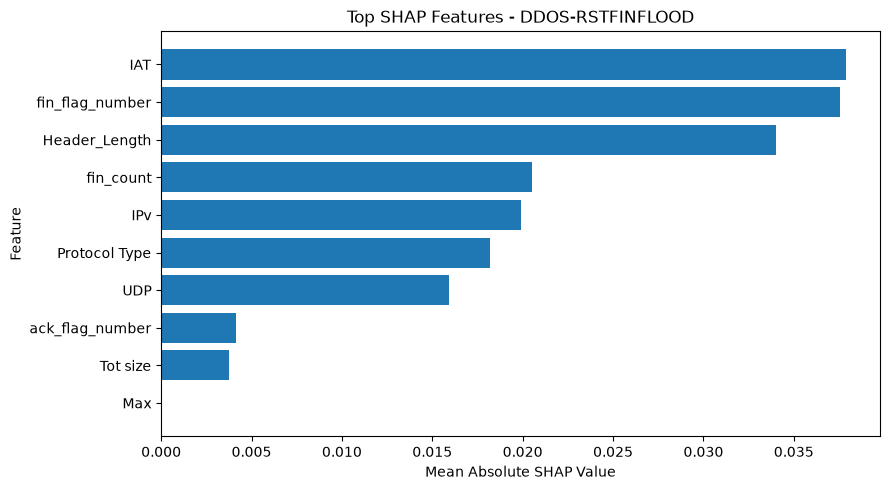

Final SHAP graph saved to: ..\results\figures\final_shap_feature_importance.png


In [114]:
final_top_features = [
    feature_names[i] for i in final_top_indices
]

final_top_values = final_feature_importance[
    final_top_indices
]

plt.figure(figsize=(9, 5))

plt.barh(
    final_top_features[::-1],
    final_top_values[::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title(
    f"Top SHAP Features - {final_predicted_label}"
)

plt.tight_layout()

final_shap_path = (
    RESULTS_FIGURES /
    "final_shap_feature_importance.png"
)

plt.savefig(
    final_shap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final SHAP graph saved to:", final_shap_path)